# Movie Data Analytics

**Problem Statement:** To analyse movie budgets, revenue, ratings and genres to identify trends and patterns in movie performance.

**Dataset:** TMDB Raw Movie Dataset (2010–2025)  
**Expected records:** Approximately 17,978 movies

## Project overview
**Beyond the Box Office: A Data-Driven Analysis of Movie Performance, Ratings and Profitability**

**Problem statement:** Movie budgets are large and returns are uncertain. This project asks how budget, genre, runtime, release timing and audience response relate to box-office revenue, ratings and profitability, using movies released between 2010 and 2025.

**Objectives (in notebook order)**
1. **Essential preprocessing:** inspect data, standardize column names, remove duplicates, convert key data types, handle invalid values, and create useful features.
2. **Exploratory Data Analysis:** explore release trends, genres, languages, finances and ratings.
3. **Analysis questions:** answer 15 descriptive questions with visualizations.
4. **Hypothesis testing:** test seven focused claims selected from the EDA.
5. **Machine learning:** predict movie revenue with Random Forest and Gradient Boosting regressors and compare them.

**Preprocessing kept minimal:** missing values are not filled in globally; analyses handle them where required, and the machine-learning pipeline imputes using training data only. Extreme values are retained unless a specific analysis defines a valid range.


## 1. Import libraries

In [2]:
# If required, uncomment and run:
# %pip install pandas numpy matplotlib seaborn scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
import json
import ast
import re
from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


## 2. Load the dataset

In [3]:
DATA_PATH = Path("movies_raw.csv")  # Change to your CSV filename/path

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH.resolve()}")

df_raw = pd.read_csv(DATA_PATH, low_memory=False)
df = df_raw.copy()

print("Original shape:", df.shape)
display(df.head())


Original shape: (17978, 16)


,movie_id,title,release_date,status,budget,revenue,runtime,genres,production_companies,production_countries,spoken_languages,original_language,vote_average,vote_count,popularity,adult
0,113727,Dark Seduction,2010-01-01,Released,0,0,89,Drama|Thriller|Romance,Lionsgate,Mexico,Español,es,6.799,102,1.6261,False
1,67250,12,2010-01-01,Released,0,0,3,Comedy,NaN,United States of America,English,en,5.000,57,0.3124,False
2,43615,"Lula, the Son of Brazil",2010-01-01,Released,9500000,3785593,130,Drama|History,LC Barreto|Filmes do Equador|InterVideo Produc...,Brazil,Português,pt,5.500,90,1.3337,False
3,38883,Protect and Serve,2010-01-03,Released,0,3807808,90,Comedy|Crime|Action,M6 Films|Same Player|Pathé|SCOPE Pictures|Webe...,France,Français,fr,4.500,106,0.5622,False
4,62105,Re-Cut,2010-01-04,Released,0,0,80,Horror|Thriller,Fritz Manger Productions|National Picture Show,United States of America,NaN,en,6.535,115,0.7341,False


## 3. Inspect the data

In [4]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("data_type"))

print("\nSummary:")
display(df.describe(include="all").T)


Shape: (17978, 16)

Columns:
['movie_id', 'title', 'release_date', 'status', 'budget', 'revenue', 'runtime', 'genres', 'production_companies', 'production_countries', 'spoken_languages', 'original_language', 'vote_average', 'vote_count', 'popularity', 'adult']

Data types:


,data_type
movie_id,int64
title,str
release_date,str
status,str
budget,int64
revenue,int64
runtime,int64
genres,str
production_companies,str
production_countries,str



Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
movie_id,17978.0,NaN,NaN,NaN,499968.873735,334180.238109,189.0,253307.75,444171.0,685586.75,1601195.0
title,17978,17322,Return,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_date,17978,4582,2020-10-02,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,17978,1,Released,17978,NaN,NaN,NaN,NaN,NaN,NaN,NaN
budget,17978.0,NaN,NaN,NaN,8389049.494883,28637071.865456,0.0,0.0,0.0,2300000.0,658800000.0
revenue,17978.0,NaN,NaN,NaN,23596567.163811,109657484.000691,0.0,0.0,0.0,1869958.75,2799439100.0
runtime,17978.0,NaN,NaN,NaN,99.501224,25.045983,0.0,90.0,98.0,110.0,585.0
genres,17968,2857,Drama,1473,NaN,NaN,NaN,NaN,NaN,NaN,NaN
production_companies,17484,15387,The Asylum,68,NaN,NaN,NaN,NaN,NaN,NaN,NaN
production_countries,17802,1808,United States of America,6076,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Standardize column names

In [5]:
df.columns = (
    df.columns.astype(str)
      .str.strip()
      .str.lower()
      .str.replace(r"[^a-z0-9]+", "_", regex=True)
      .str.strip("_")
)

print(df.columns.tolist())


['movie_id', 'title', 'release_date', 'status', 'budget', 'revenue', 'runtime', 'genres', 'production_companies', 'production_countries', 'spoken_languages', 'original_language', 'vote_average', 'vote_count', 'popularity', 'adult']


## 5. Check duplicates

In [6]:
print("Exact duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()

if "movie_id" in df.columns:
    print("Rows with repeated movie IDs:",
          df["movie_id"].duplicated(keep=False).sum())
    # Remove repeated IDs, keeping the first record.
    # Review duplicates before final submission if IDs may represent different releases.
    df = df.drop_duplicates(subset=["movie_id"], keep="first")

print("Shape after duplicate removal:", df.shape)


Exact duplicate rows: 0
Rows with repeated movie IDs: 0
Shape after duplicate removal: (17978, 16)


## 6. Clean text and convert data types

In [7]:
# Trim text and convert blank strings to missing values
text_cols = df.select_dtypes(include=["object", "string"]).columns
for col in text_cols:
    df[col] = df[col].apply(lambda x: x.strip() if isinstance(x, str) else x)

df = df.replace(r"^\s*$", np.nan, regex=True)

# Convert known numeric fields only when present
numeric_cols = [
    "budget", "revenue", "runtime", "vote_average",
    "vote_count", "popularity"
]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Parse release date if available
if "release_date" in df.columns:
    df["release_date"] = pd.to_datetime(
        df["release_date"], errors="coerce", format="mixed"
    )

print(df.dtypes)


movie_id                         int64
title                              str
release_date            datetime64[us]
status                             str
budget                           int64
revenue                          int64
runtime                          int64
genres                             str
production_companies               str
production_countries               str
spoken_languages                   str
original_language                  str
vote_average                   float64
vote_count                       int64
popularity                     float64
adult                             bool
dtype: object


## 7. Missing-value report

In [8]:
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)
display(missing_report)


,missing_count,missing_percent
production_companies,494,2.75
production_countries,176,0.98
spoken_languages,92,0.51
genres,10,0.06
status,0,0.00
movie_id,0,0.00
release_date,0,0.00
title,0,0.00
runtime,0,0.00
revenue,0,0.00


## 8. Keep missing values as missing


In [9]:

print("Missing values retained for analysis:", int(df.isna().sum().sum()))


Missing values retained for analysis: 772


## 9. Validate values and handle financial zeros

In [10]:
# Set impossible negative values to missing
for col in ["budget", "revenue", "runtime", "vote_count", "popularity"]:
    if col in df.columns:
        df.loc[df[col] < 0, col] = np.nan

# Ratings are expected to be on a 0–10 scale
if "vote_average" in df.columns:
    invalid_rating = df["vote_average"].notna() & ~df["vote_average"].between(0, 10)
    print("Invalid ratings:", int(invalid_rating.sum()))
    df.loc[invalid_rating, "vote_average"] = np.nan

if "budget" in df.columns:
    df["budget_analysis"] = df["budget"].where(df["budget"] > 0)

if "revenue" in df.columns:
    df["revenue_analysis"] = df["revenue"].where(df["revenue"] > 0)

for col in ["budget", "revenue", "runtime", "vote_average", "vote_count", "popularity"]:
    if col in df.columns:
        print(f"{col}: zeros={(df[col] == 0).sum()}, missing={df[col].isna().sum()}")


Invalid ratings: 0
budget: zeros=12463, missing=0
revenue: zeros=11156, missing=0
runtime: zeros=46, missing=0
vote_average: zeros=0, missing=0
vote_count: zeros=0, missing=0
popularity: zeros=0, missing=0


## 10. Create date and genre features

In [11]:
if "release_date" in df.columns:
    df["release_year"] = df["release_date"].dt.year
    df["release_month"] = df["release_date"].dt.month
    df["release_month_name"] = df["release_date"].dt.month_name()
    df["release_decade"] = ((df["release_year"] // 10) * 10).astype("Int64")

def clean_category(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip()
    if value.lower() in {"", "nan", "none", "null"}:
        return np.nan
    return re.sub(r"\s*\|\s*", "|", value)

for col in ["status", "original_language", "spoken_languages",
            "genres", "production_companies", "production_countries"]:
    if col in df.columns:
        df[col] = df[col].apply(clean_category)

def first_genre(value):
    if pd.isna(value):
        return "Unknown"
    text = str(value).strip()
    if text.startswith("["):
        try:
            parsed = json.loads(text)
        except (json.JSONDecodeError, TypeError):
            try:
                parsed = ast.literal_eval(text)
            except (ValueError, SyntaxError):
                parsed = None
        if isinstance(parsed, list):
            items = [str(x).strip() for x in parsed if str(x).strip()]
            return items[0] if items else "Unknown"
    parts = re.split(r"\s*[|,]\s*", text)
    return parts[0] if parts and parts[0] else "Unknown"

if "genres" in df.columns:
    df["primary_genre"] = df["genres"].apply(first_genre)

display(df.head())


,movie_id,title,release_date,status,budget,revenue,runtime,genres,production_companies,production_countries,spoken_languages,original_language,vote_average,vote_count,popularity,adult,budget_analysis,revenue_analysis,release_year,release_month,release_month_name,release_decade,primary_genre
0,113727,Dark Seduction,2010-01-01,Released,0.0,0.0,89.0,Drama|Thriller|Romance,Lionsgate,Mexico,Español,es,6.799,102.0,1.6261,False,NaN,NaN,2010,1,January,2010,Drama
1,67250,12,2010-01-01,Released,0.0,0.0,3.0,Comedy,NaN,United States of America,English,en,5.000,57.0,0.3124,False,NaN,NaN,2010,1,January,2010,Comedy
2,43615,"Lula, the Son of Brazil",2010-01-01,Released,9500000.0,3785593.0,130.0,Drama|History,LC Barreto|Filmes do Equador|InterVideo Produc...,Brazil,Português,pt,5.500,90.0,1.3337,False,9500000.0,3785593.0,2010,1,January,2010,Drama
3,38883,Protect and Serve,2010-01-03,Released,0.0,3807808.0,90.0,Comedy|Crime|Action,M6 Films|Same Player|Pathé|SCOPE Pictures|Webe...,France,Français,fr,4.500,106.0,0.5622,False,NaN,3807808.0,2010,1,January,2010,Comedy
4,62105,Re-Cut,2010-01-04,Released,0.0,0.0,80.0,Horror|Thriller,Fritz Manger Productions|National Picture Show,United States of America,NaN,en,6.535,115.0,0.7341,False,NaN,NaN,2010,1,January,2010,Horror


## 11. Create financial features

In [12]:
if {"budget_analysis", "revenue_analysis"}.issubset(df.columns):
    valid_financial = (
        df["budget_analysis"].notna()
        & df["revenue_analysis"].notna()
    )

    df["profit_estimate"] = np.nan
    df.loc[valid_financial, "profit_estimate"] = (
        df.loc[valid_financial, "revenue_analysis"]
        - df.loc[valid_financial, "budget_analysis"]
    )

    df["roi_percent"] = np.nan
    df.loc[valid_financial, "roi_percent"] = (
        df.loc[valid_financial, "profit_estimate"]
        / df.loc[valid_financial, "budget_analysis"]
    ) * 100

print("Financial features created where data is available.")


Financial features created where data is available.


## 12. Final quality check


Outlier detection is omitted here; extreme movie budgets and revenues may be genuine, so they are retained.


In [13]:
print("Final shape:", df.shape)

final_missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

display(final_missing)

if "release_date" in df.columns:
    print("Release date range:", df["release_date"].min(), "to", df["release_date"].max())

for col in ["budget_analysis", "revenue_analysis", "profit_estimate", "roi_percent"]:
    if col in df.columns:
        print(f"{col}: {df[col].notna().sum()} valid records")


Final shape: (17978, 25)


,missing_count,missing_percent
roi_percent,13873,77.17
profit_estimate,13873,77.17
budget_analysis,12463,69.32
revenue_analysis,11156,62.05
production_companies,494,2.75
production_countries,176,0.98
spoken_languages,92,0.51
genres,10,0.06
movie_id,0,0.00
revenue,0,0.00


Release date range: 2010-01-01 00:00:00 to 2025-12-30 00:00:00
budget_analysis: 5515 valid records
revenue_analysis: 6822 valid records
profit_estimate: 4105 valid records
roi_percent: 4105 valid records


## 13. Export cleaned dataset


In [14]:
# Export one reusable cleaned dataset only
OUTPUT_DIR = Path("movie_project_output")
OUTPUT_DIR.mkdir(exist_ok=True)
df.to_csv(OUTPUT_DIR / "movies_cleaned.csv", index=False)
print("Cleaned dataset saved to:", (OUTPUT_DIR / "movies_cleaned.csv").resolve())


Cleaned dataset saved to: D:\SEM 5\FODS\fods_review2\movie_project_output\movies_cleaned.csv


## 16. Exploratory Data Analysis (EDA)
Uses the cleaned `df` from the essential preprocessing steps above. All plots work on a copy (`eda`), so the preprocessing output is untouched.


### 16.1 Setup and data checks

In [15]:
import plotly.express as px
import plotly.graph_objects as go
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid", context="notebook")
ACCENT, ACCENT2, GREY = "#2E5E8C", "#E07A3F", "#8A8F98"
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.titleweight": "bold"})

eda = df.copy()
print("Dataset shape:", eda.shape)
print("\nColumns:", eda.columns.tolist())

needed = ["title", "release_year", "genres", "budget_analysis", "revenue_analysis",
          "runtime", "vote_average", "vote_count", "popularity"]
print("\nRequired columns missing:", [c for c in needed if c not in eda.columns] or "None")

Dataset shape: (17978, 25)

Columns: ['movie_id', 'title', 'release_date', 'status', 'budget', 'revenue', 'runtime', 'genres', 'production_companies', 'production_countries', 'spoken_languages', 'original_language', 'vote_average', 'vote_count', 'popularity', 'adult', 'budget_analysis', 'revenue_analysis', 'release_year', 'release_month', 'release_month_name', 'release_decade', 'primary_genre', 'profit_estimate', 'roi_percent']

Required columns missing: None


In [16]:
# Raw missing values (before SimpleImputer) vs zero values, for the fields used in EDA
raw_std = df_raw.copy()
raw_std.columns = (raw_std.columns.astype(str).str.strip().str.lower()
                   .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
raw_std = raw_std.reindex(eda.index)

eda_fields = ["release_date", "genres", "budget", "revenue", "runtime",
              "vote_average", "vote_count", "popularity"]
quality = pd.DataFrame({
    "raw_missing": raw_std[eda_fields].isna().sum(),
    "missing_now": eda[eda_fields].isna().sum(),
    "zeros": [int((eda[c] == 0).sum()) if c != "release_date" and c != "genres" else 0
              for c in eda_fields],
})
display(quality)

,raw_missing,missing_now,zeros
release_date,0,0,0
genres,10,10,0
budget,0,0,12463
revenue,0,0,11156
runtime,0,0,46
vote_average,0,0,0
vote_count,0,0,0
popularity,0,0,0


In [17]:
# Analysis-ready fields (original columns in `df` are not modified)
MIN_VALID = 1_000   # budgets/revenues below $1,000 are treated as placeholder values, not real figures

eda["budget_eda"]  = eda["budget_analysis"].where(eda["budget_analysis"] >= MIN_VALID)
eda["revenue_eda"] = eda["revenue_analysis"].where(eda["revenue_analysis"] >= MIN_VALID)
eda["runtime_eda"] = eda["runtime"].where(eda["runtime"] > 0)

# Genres that SimpleImputer filled in (originally missing) are excluded from genre plots
genre_imputed = raw_std["genres"].isna()
eda["genres_eda"] = eda["genres"].where(~genre_imputed)
eda["genre"] = eda["genres_eda"].str.split("|")

fin = eda.dropna(subset=["budget_eda", "revenue_eda"]).copy()   # valid financial records

records_used = pd.Series({
    "1. Release trends":      int(eda["release_year"].notna().sum()),
    "2. Genre distribution":  int(eda["genres_eda"].notna().sum()),
    "3. Budget vs revenue":   len(fin),
    "4. Ratings distribution": int(eda["vote_average"].notna().sum()),
    "5. Revenue by genre":    len(fin.dropna(subset=["genres_eda"])),
    "6. Correlation heatmap": "pairwise (see plot)",
    "7. Ratings vs popularity": int(eda[["vote_average", "popularity"]].dropna().shape[0]),
    "8. Language share":      int(eda["original_language"].notna().sum()),
    "9. ROI by genre":        len(fin.dropna(subset=["genres_eda"])),
    "10. Profit by budget tier": len(fin),
    "11. Release seasonality": int(eda[["release_year", "release_month"]].dropna().shape[0]),
    "12. Top 10 grossing":    10,
}, name="valid_records")
display(records_used.to_frame())

print(f"Zero budgets set aside: {int((eda['budget'] == 0).sum()):,} | zero revenues set aside: {int((eda['revenue'] == 0).sum()):,}")
print(f"Positive but under ${MIN_VALID:,} (treated as invalid): "
      f"budget {int(((eda['budget_analysis'] > 0) & (eda['budget_analysis'] < MIN_VALID)).sum())}, "
      f"revenue {int(((eda['revenue_analysis'] > 0) & (eda['revenue_analysis'] < MIN_VALID)).sum())}")
print("Blockbuster outliers are kept in every plot.")

,valid_records
1. Release trends,17978
2. Genre distribution,17968
3. Budget vs revenue,4090
4. Ratings distribution,17978
5. Revenue by genre,4090
6. Correlation heatmap,pairwise (see plot)
7. Ratings vs popularity,17978
8. Language share,17978
9. ROI by genre,4090
10. Profit by budget tier,4090


Zero budgets set aside: 12,463 | zero revenues set aside: 11,156
Positive but under $1,000 (treated as invalid): budget 35, revenue 45
Blockbuster outliers are kept in every plot.


* The dataset contains 17,978 movies, but many budget and revenue values are missing or recorded as zero. Financial analyses use only plausible reported values; recent-year counts may also be incomplete.

### 16.2 Plot 1: Movie release trends

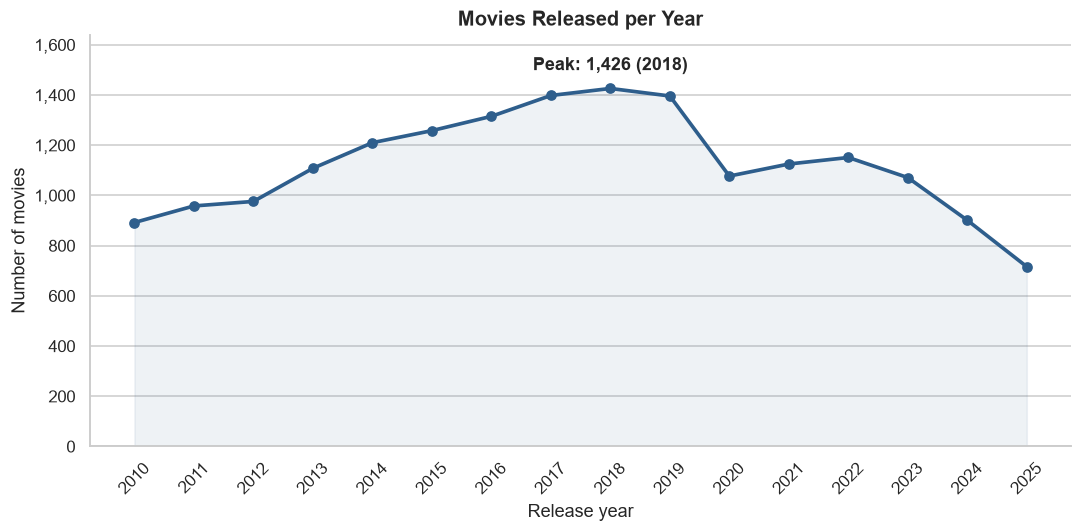

2010: 892 movies | peak 2018: 1,426 | 2025: 716
Growth 2010 to 2018: 59.9%
2019 to 2020 change: -22.9%
2018 to 2025 change: -49.8%
Latest release date in data: 2025-12-30
Minimum vote_count in data: 50


In [18]:
yearly = eda["release_year"].dropna().astype(int).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(yearly.index, yearly.values, marker="o", lw=2.4, color=ACCENT)
ax.fill_between(yearly.index, yearly.values, alpha=0.08, color=ACCENT)

peak_year = int(yearly.idxmax())
ax.annotate(f"Peak: {yearly.max():,} ({peak_year})", xy=(peak_year, yearly.max()),
            xytext=(0, 12), textcoords="offset points", ha="center", fontweight="bold")
ax.set(title="Movies Released per Year", xlabel="Release year", ylabel="Number of movies",
       ylim=(0, yearly.max() * 1.15))
ax.set_xticks(yearly.index)
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", rotation=45)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
sns.despine()
plt.tight_layout()
plt.show()

first, last = int(yearly.index.min()), int(yearly.index.max())
print(f"{first}: {yearly[first]:,} movies | peak {peak_year}: {yearly.max():,} | {last}: {yearly[last]:,}")
print(f"Growth {first} to {peak_year}: {(yearly[peak_year] / yearly[first] - 1) * 100:.1f}%")
print(f"2019 to 2020 change: {(yearly[2020] / yearly[2019] - 1) * 100:.1f}%")
print(f"{peak_year} to {last} change: {(yearly[last] / yearly[peak_year] - 1) * 100:.1f}%")
print("Latest release date in data:", eda["release_date"].max().date())
print("Minimum vote_count in data:", int(eda["vote_count"].min()))

**Interpretation:** Releases grew from 892 movies in 2010 to a peak of 1,426 in 2018 (+59.9%). Counts then fell 22.9% from 2019 to 2020 (1,396 to 1,077), stayed near 1,070 to 1,150 through 2023, and dropped to 716 by 2025 (49.8% below the peak). The 2020 dip coincides with the pandemic period, but this plot alone cannot show the cause. Every movie in the file has at least 50 votes, so recent titles that have not yet collected votes may be missing; the 2024 and 2025 decline should be read with that in mind.

### 16.3 Plot 2: Genre distribution

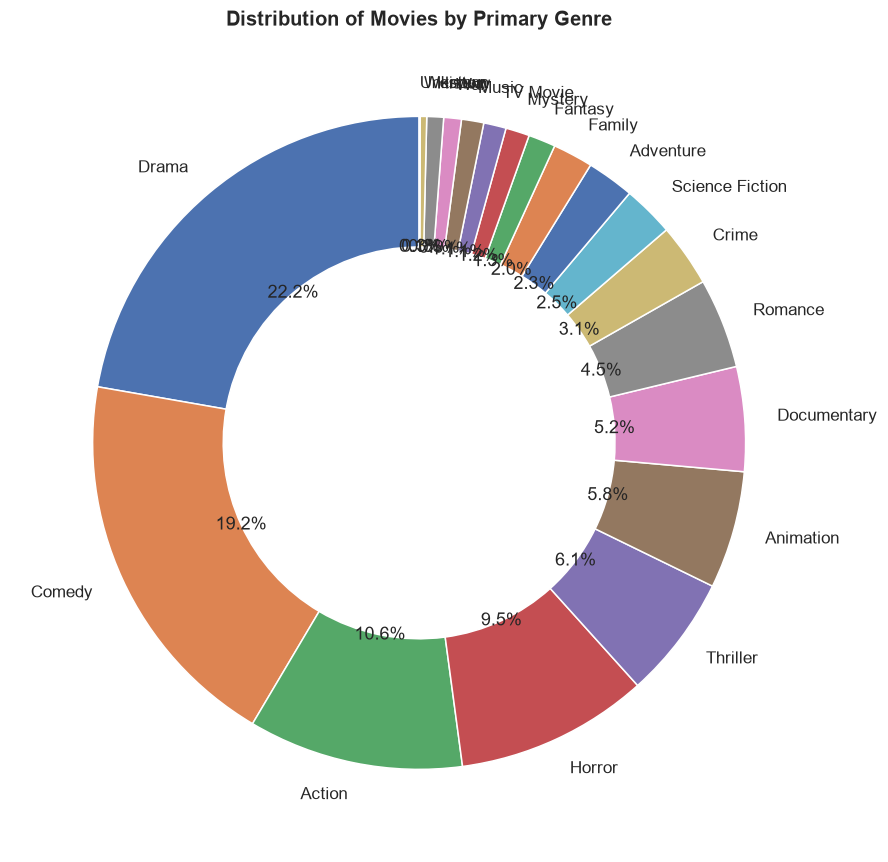

In [19]:


# Count movies in each primary genre
genre_counts = (
    df["primary_genre"]
    .dropna()
    .value_counts()
)

# Create donut chart
plt.figure(figsize=(10, 8))

plt.pie(
    genre_counts,
    labels=genre_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Distribution of Movies by Primary Genre")
plt.tight_layout()
plt.show()

**Interpretation:**  Drama and Comedy are the most common genres, and most movies have more than one genre. Genre percentages overlap because each movie can carry multiple tags..

### 16.4 Plot 3: Budget vs revenue

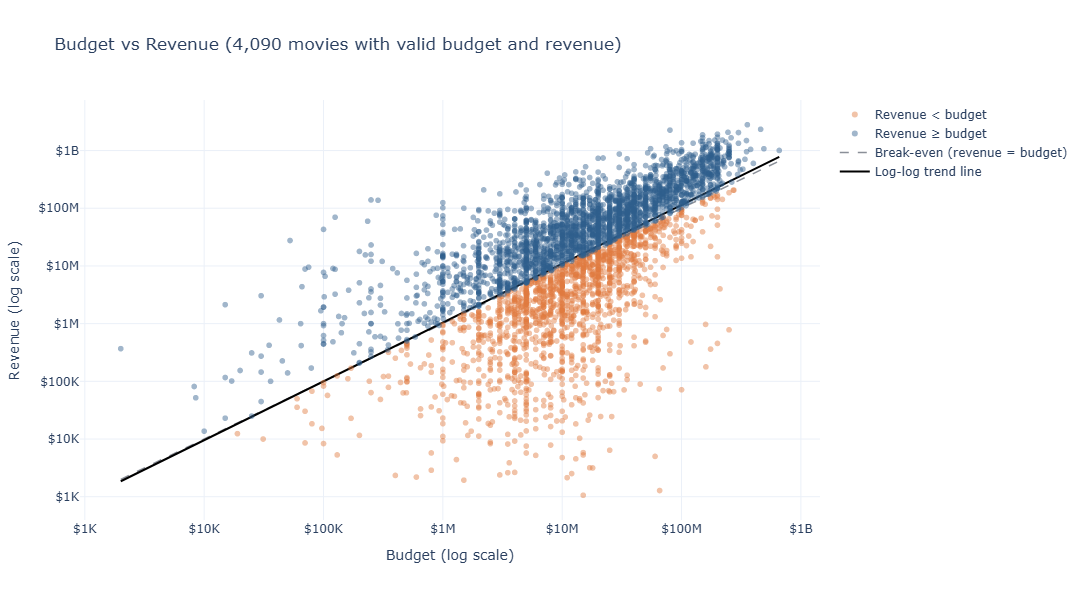

Valid records: 4,090
Spearman rho: 0.70 | Pearson r on log10 values: 0.64 | log-log slope: 1.02
Revenue >= budget: 61.8%
Median budget: $14,500,000 | median revenue: $19,798,124
Highest revenue: {'title': 'Avengers: Endgame', 'budget_eda': 356000000.0, 'revenue_eda': 2799439100.0}


In [20]:
# Both axes are heavily right-skewed, so log scales are used. Only movies with valid budget AND revenue.
tick_vals = [1e3, 1e4, 1e5, 1e6, 1e7, 1e8, 1e9]
tick_text = ["$1K", "$10K", "$100K", "$1M", "$10M", "$100M", "$1B"]

plot3 = fin.assign(
    Outcome=np.where(fin["revenue_eda"] >= fin["budget_eda"], "Revenue ≥ budget", "Revenue < budget"),
    Year=fin["release_year"].astype(int),
)
fig = px.scatter(
    plot3, x="budget_eda", y="revenue_eda", color="Outcome",
    color_discrete_map={"Revenue ≥ budget": ACCENT, "Revenue < budget": ACCENT2},
    log_x=True, log_y=True, opacity=0.45,
    hover_name="title", hover_data={"budget_eda": ":$,.0f", "revenue_eda": ":$,.0f", "Year": True, "Outcome": False},
    labels={"budget_eda": "Budget (log scale)", "revenue_eda": "Revenue (log scale)"},
    title=f"Budget vs Revenue ({len(plot3):,} movies with valid budget and revenue)",
)
lo, hi = plot3["budget_eda"].min(), plot3["budget_eda"].max()
fig.add_trace(go.Scatter(x=[lo, hi], y=[lo, hi], mode="lines", name="Break-even (revenue = budget)",
                         line=dict(color=GREY, dash="dash", width=1.5), hoverinfo="skip"))

slope, intercept = np.polyfit(np.log10(plot3["budget_eda"]), np.log10(plot3["revenue_eda"]), 1)
fig.add_trace(go.Scatter(x=[lo, hi], y=10 ** (intercept + slope * np.log10([lo, hi])), mode="lines",
                         name="Log-log trend line", line=dict(color="black", width=2), hoverinfo="skip"))
fig.update_xaxes(tickvals=tick_vals, ticktext=tick_text)
fig.update_yaxes(tickvals=tick_vals, ticktext=tick_text)
fig.update_layout(template="plotly_white", height=600, legend_title_text="", hovermode="closest")
fig.show()

rho = plot3[["budget_eda", "revenue_eda"]].corr(method="spearman").iloc[0, 1]
r_log = np.corrcoef(np.log10(plot3["budget_eda"]), np.log10(plot3["revenue_eda"]))[0, 1]
print(f"Valid records: {len(plot3):,}")
print(f"Spearman rho: {rho:.2f} | Pearson r on log10 values: {r_log:.2f} | log-log slope: {slope:.2f}")
print(f"Revenue >= budget: {(plot3['Outcome'] == 'Revenue ≥ budget').mean() * 100:.1f}%")
print(f"Median budget: ${plot3['budget_eda'].median():,.0f} | median revenue: ${plot3['revenue_eda'].median():,.0f}")
print("Highest revenue:", plot3.nlargest(1, "revenue_eda")[["title", "budget_eda", "revenue_eda"]].to_dict("records")[0])

**Interpretation:** Budget and revenue move together: Spearman rho is 0.70 and the correlation of the log values is 0.64 across 4,090 movies. The log-log trend slope is about 1.02, so on average a 10x larger budget goes with roughly 10x larger revenue. The spread around the line is wide, though: 61.8% of movies earned at least their budget, and 38.2% fell below the break-even line. Some points sit far above the trend, such as Ne Zha 2 (about $80M budget, $2.26B revenue), while Avengers: Endgame ($356M budget, $2.80B revenue) is the highest earner. A bigger budget therefore tends to go with more revenue but does not guarantee it. Revenue here is not profit, because marketing and distribution costs are not included.

### 16.5 Plot 4: Ratings distribution

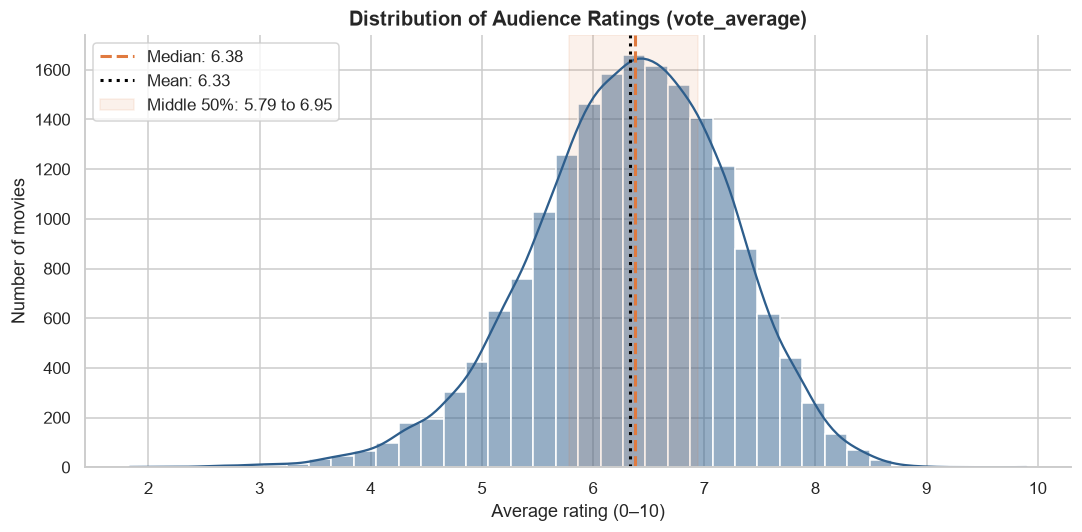

Valid records: 17,978
Mean 6.33 | median 6.38 | std 0.88 | skewness -0.39
Middle 50%: 5.79 to 6.95 | middle 90%: 4.80 to 7.70
Min 1.83 | max 9.90
Share of movies rated 5.5 to 7.5: 76.1%
Share rated below 4: 1.0% | above 8: 1.7%


In [21]:
ratings = eda["vote_average"].dropna()
mean_r, median_r, skew_r = ratings.mean(), ratings.median(), ratings.skew()
q1, q3 = ratings.quantile([0.25, 0.75])

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(ratings, bins=40, kde=True, color=ACCENT, edgecolor="white", ax=ax)
ax.axvline(median_r, color=ACCENT2, lw=2, ls="--", label=f"Median: {median_r:.2f}")
ax.axvline(mean_r, color="black", lw=2, ls=":", label=f"Mean: {mean_r:.2f}")
ax.axvspan(q1, q3, color=ACCENT2, alpha=0.10, label=f"Middle 50%: {q1:.2f} to {q3:.2f}")
ax.set(title="Distribution of Audience Ratings (vote_average)", xlabel="Average rating (0–10)", ylabel="Number of movies")
ax.legend(frameon=True, loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

p5, p95 = ratings.quantile([0.05, 0.95])
print(f"Valid records: {len(ratings):,}")
print(f"Mean {mean_r:.2f} | median {median_r:.2f} | std {ratings.std():.2f} | skewness {skew_r:.2f}")
print(f"Middle 50%: {q1:.2f} to {q3:.2f} | middle 90%: {p5:.2f} to {p95:.2f}")
print(f"Min {ratings.min():.2f} | max {ratings.max():.2f}")
print(f"Share of movies rated 5.5 to 7.5: {ratings.between(5.5, 7.5).mean() * 100:.1f}%")
print(f"Share rated below 4: {(ratings < 4).mean() * 100:.1f}% | above 8: {(ratings > 8).mean() * 100:.1f}%")

**Interpretation:** Ratings are centred around 6.4 (mean 6.33, median 6.38, standard deviation 0.88). The middle 50% of movies fall between 5.79 and 6.95, and 76.1% lie between 5.5 and 7.5. Skewness is -0.39, a mild left skew caused by a thin tail of low-rated movies (1.0% below 4.0, lowest 1.83). Ratings above 8.0 are rare (1.7%). All ratings are based on at least 50 votes, which limits noise from tiny samples.

### 16.6 Plot 5: Revenue by genre

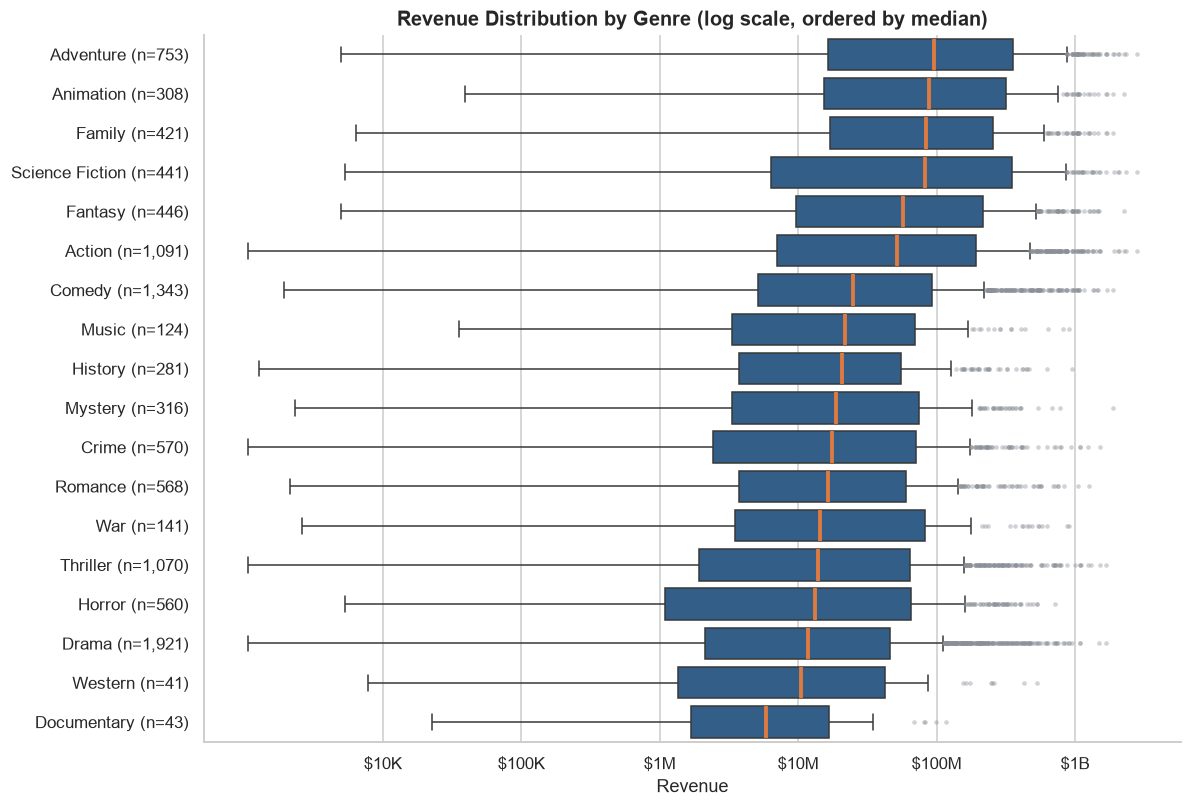

,movies,median,q1,q3,max,iqr_ratio
genre,,,,,,
Adventure,753,"$96,221,061","$16,349,303","$359,126,022","$2,799,439,100",22.0x
Animation,308,"$88,181,886","$15,256,715","$316,715,596","$2,259,822,417",20.8x
Family,421,"$83,761,844","$17,062,499","$254,212,245","$1,868,208,796",14.9x
Science Fiction,441,"$83,100,000","$6,333,688","$348,319,861","$2,799,439,100",55.0x
Fantasy,446,"$56,913,544","$9,638,589","$216,819,664","$2,259,822,417",22.5x
Action,1091,"$51,825,248","$7,014,516","$192,619,211","$2,799,439,100",27.5x
Comedy,1343,"$24,856,027","$5,100,836","$92,248,017","$1,868,208,796",18.1x
Music,124,"$21,884,786","$3,342,648","$69,568,922","$910,813,521",20.8x
History,281,"$20,659,643","$3,738,618","$55,736,588","$952,000,000",14.9x


Valid records: 4,090 movies; genres with fewer than 30 movies excluded: ['TV Movie']
Largest revenues: Avengers: Endgame ($2,799,439,100); Avatar: The Way of Water ($2,334,484,620); Ne Zha 2 ($2,259,822,417)


In [22]:
# Valid financial records only (budget and revenue both valid); movies appear in each of their genres.
rev_genre = (fin.dropna(subset=["genre"])[["title", "revenue_eda", "genre"]]
             .explode("genre").assign(genre=lambda d: d["genre"].str.strip()))
MIN_N = 30
counts5 = rev_genre["genre"].value_counts()
keep = counts5[counts5 >= MIN_N].index
rev_genre = rev_genre[rev_genre["genre"].isin(keep)]
order = rev_genre.groupby("genre")["revenue_eda"].median().sort_values(ascending=False).index.tolist()
labels = {g: f"{g} (n={counts5[g]:,})" for g in order}
rev_genre["label"] = rev_genre["genre"].map(labels)

fig, ax = plt.subplots(figsize=(11, 7.5))
sns.boxplot(data=rev_genre, x="revenue_eda", y="label", order=[labels[g] for g in order],
            color=ACCENT, saturation=0.9, linewidth=1,
            medianprops=dict(color=ACCENT2, linewidth=2.5),
            flierprops=dict(marker="o", markersize=3, markerfacecolor=GREY, alpha=0.4, markeredgecolor="none"),
            ax=ax)
ax.set_xscale("log")
ax.set_xticks([1e4, 1e5, 1e6, 1e7, 1e8, 1e9])
ax.set_xticklabels(["$10K", "$100K", "$1M", "$10M", "$100M", "$1B"])
ax.set(title="Revenue Distribution by Genre (log scale, ordered by median)", xlabel="Revenue", ylabel="")
sns.despine()
plt.tight_layout()
plt.show()

summary5 = (rev_genre.groupby("genre")["revenue_eda"]
            .agg(movies="count", median="median",
                 q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75), max="max")
            .assign(iqr_ratio=lambda d: d["q3"] / d["q1"])
            .loc[order])
display(summary5.style.format({"median": "${:,.0f}", "q1": "${:,.0f}", "q3": "${:,.0f}",
                               "max": "${:,.0f}", "iqr_ratio": "{:.1f}x"}))
print(f"Valid records: {fin.dropna(subset=['genres_eda']).shape[0]:,} movies; genres with fewer than {MIN_N} movies excluded: "
      f"{[g for g in counts5.index if counts5[g] < MIN_N] or 'none'}")
top = fin.nlargest(3, "revenue_eda")[["title", "revenue_eda"]]
print("Largest revenues:", "; ".join(f"{t} (${r:,.0f})" for t, r in zip(top["title"], top["revenue_eda"])))

**Interpretation:**  Adventure, Animation, Family and Science Fiction have the highest median revenues in this dataset. Genre comparisons should be read alongside differences in sample size and budget.

### 16.7 Plot 6: Correlation heatmap

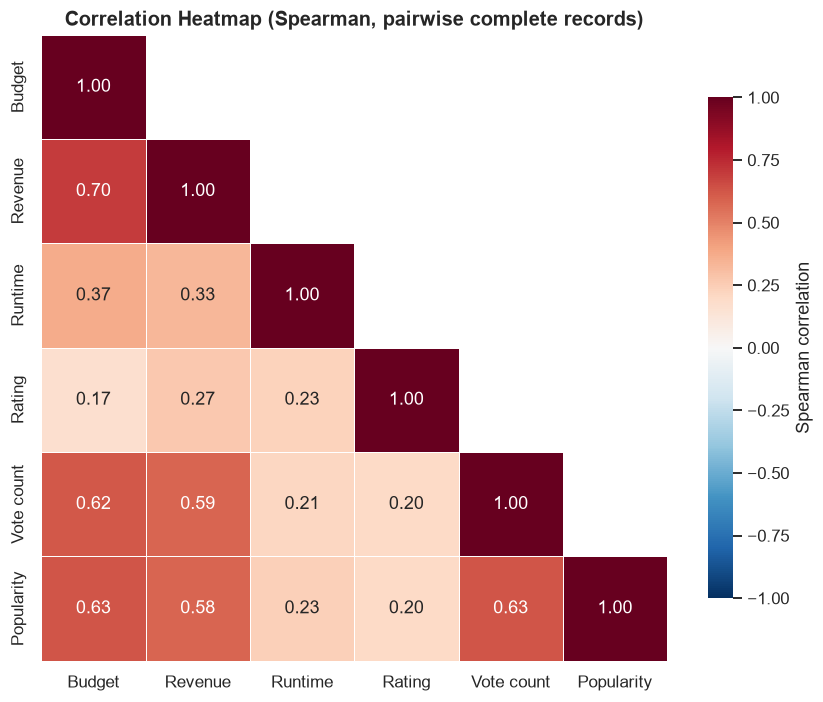

Records per pair: min 4,090, max 17,978


,var1,var2,rho,n
0,Revenue,Budget,0.70,4090
1,Popularity,Vote count,0.63,17978
2,Popularity,Budget,0.63,5480
3,Vote count,Budget,0.62,5480
4,Vote count,Revenue,0.59,6777
5,Popularity,Revenue,0.58,6777
6,Runtime,Budget,0.37,5476
7,Runtime,Revenue,0.33,6773
8,Rating,Revenue,0.27,6777
9,Popularity,Runtime,0.23,17932


In [23]:
# IDs, year and month are excluded. Spearman is used because most variables are strongly skewed.
corr_cols = {"budget_eda": "Budget", "revenue_eda": "Revenue", "runtime_eda": "Runtime",
             "vote_average": "Rating", "vote_count": "Vote count", "popularity": "Popularity"}
corr_data = eda[list(corr_cols)].rename(columns=corr_cols)
corr = corr_data.corr(method="spearman")

pair_n = pd.DataFrame({a: {b: int(corr_data[[a, b]].dropna().shape[0]) for b in corr_data} for a in corr_data})

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, square=True, cbar_kws={"label": "Spearman correlation", "shrink": 0.8}, ax=ax)
ax.set_title("Correlation Heatmap (Spearman, pairwise complete records)")
ax.grid(False)
plt.tight_layout()
plt.show()

pairs = pd.DataFrame([
    {"var1": a, "var2": b, "rho": corr.loc[a, b], "n": pair_n.loc[a, b]}
    for i, a in enumerate(corr.columns) for b in corr.columns[:i]
]).sort_values("rho", key=abs, ascending=False)
print(f"Records per pair: min {pair_n.values.min():,}, max {pair_n.values.max():,}")
display(pairs.round(2).reset_index(drop=True))

**Interpretation:** The strongest link is Budget and Revenue (rho 0.70). Popularity, vote count and budget form a second group at 0.62 to 0.63, and revenue correlates 0.58 to 0.59 with popularity and vote count. Rating is only weakly related to everything else (0.17 to 0.27), and no correlation is negative. Spearman rank correlation is used because the variables are strongly skewed, and each pair uses between 4,090 and 17,978 records. Correlation does not imply causation: for example, big-budget movies may reach more viewers, which raises vote counts, so the link need not mean one variable drives the other.

### 16.8 Plot 7: Ratings vs popularity

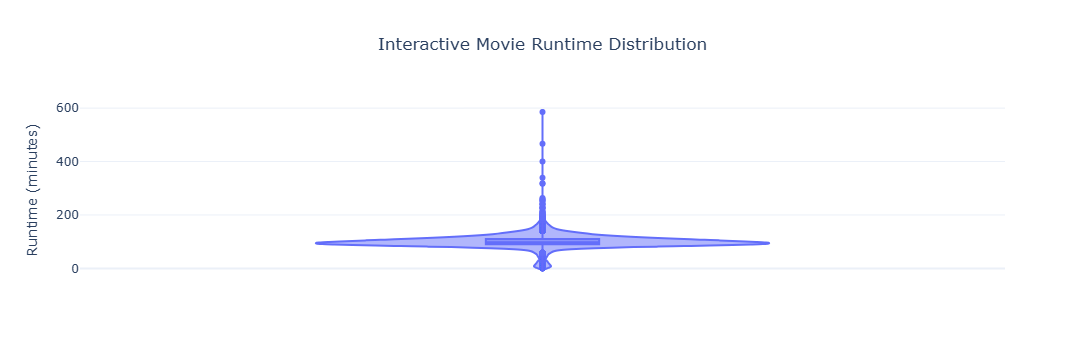

In [24]:

# Keep valid runtimes
runtime_df = df[
    df["runtime"].notna() &
    (df["runtime"] > 0)
].copy()

# Create interactive violin plot
fig = px.violin(
    runtime_df,
    y="runtime",
    box=True,
    points="outliers",
    hover_data=["title", "release_year"],
    title="Interactive Movie Runtime Distribution",
    labels={"runtime": "Runtime (minutes)"}
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    yaxis_title="Runtime (minutes)",
    showlegend=False
)

fig.show()

**Interpretation:** The violin plot illustrates the distribution of movie runtimes in minutes. The width of the plot indicates how frequently runtime values occur, with wider sections representing more movies in that range. The inner box plot summarizes the median and spread of runtimes, while individual points highlight potential outliers.

### 16.9 Additional plots (8–12)
Five extra views that go beyond the standard charts above.

#### Plot 8: Movies by original language (treemap)

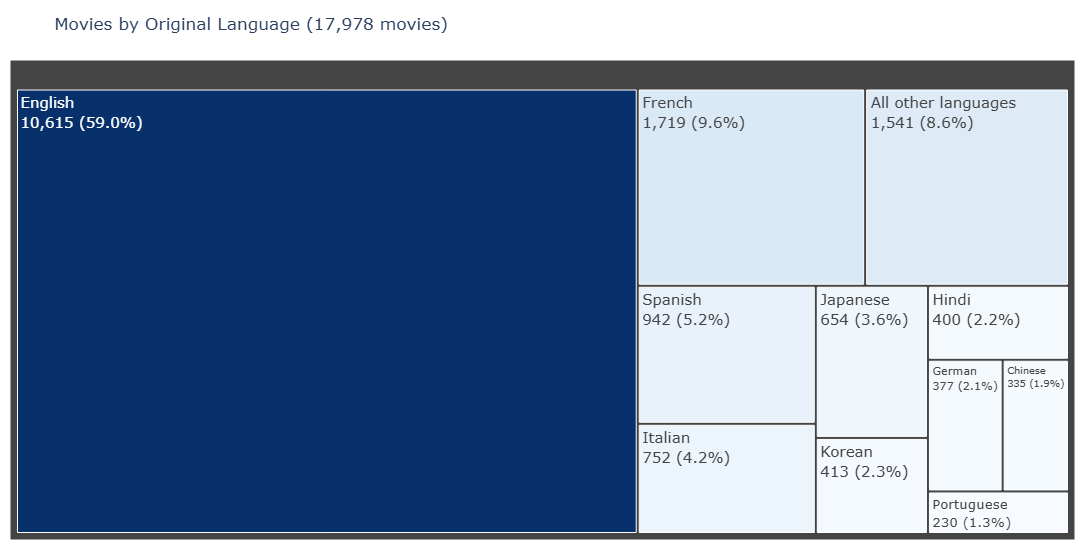

Valid records: 17,978 | distinct languages: 80
Top 5: English 10,615 (59.0%), French 1,719 (9.6%), Spanish 942 (5.2%), Italian 752 (4.2%), Japanese 654 (3.6%)
Top 3 combined: 73.8% | top 10 combined: 91.4%


In [25]:
lang_names = {"en": "English", "hi": "Hindi", "es": "Spanish", "fr": "French", "ja": "Japanese", "ko": "Korean",
              "zh": "Chinese", "de": "German", "it": "Italian", "pt": "Portuguese", "ru": "Russian", "ta": "Tamil",
              "te": "Telugu", "ml": "Malayalam", "tr": "Turkish", "cn": "Cantonese", "th": "Thai", "id": "Indonesian",
              "ar": "Arabic", "pl": "Polish", "sv": "Swedish", "da": "Danish", "nl": "Dutch", "kn": "Kannada", "bn": "Bengali"}
lang_counts = eda["original_language"].dropna().value_counts()
total_lang = int(lang_counts.sum())
top_lang = lang_counts.head(10)
lang_df = pd.DataFrame({
    "language": [lang_names.get(c, c) for c in top_lang.index] + ["All other languages"],
    "movies": list(top_lang.values) + [int(lang_counts.iloc[10:].sum())],
})
lang_df["label"] = [f"{l}<br>{m:,} ({m / total_lang * 100:.1f}%)" for l, m in zip(lang_df["language"], lang_df["movies"])]

fig = px.treemap(lang_df, path=["label"], values="movies", color="movies",
                 color_continuous_scale="Blues", title=f"Movies by Original Language ({total_lang:,} movies)")
fig.update_traces(textfont_size=15, hovertemplate="%{label}<extra></extra>")
fig.update_layout(template="plotly_white", height=550, coloraxis_showscale=False, margin=dict(t=60, l=10, r=10, b=10))
fig.show()

print(f"Valid records: {total_lang:,} | distinct languages: {len(lang_counts)}")
print("Top 5:", ", ".join(f"{lang_names.get(c, c)} {n:,} ({n / total_lang * 100:.1f}%)" for c, n in lang_counts.head(5).items()))
print(f"Top 3 combined: {lang_counts.head(3).sum() / total_lang * 100:.1f}% | top 10 combined: {top_lang.sum() / total_lang * 100:.1f}%")

**Interpretation:** English is the original language of 10,615 movies (59.0%), followed by French (1,719, 9.6%), Spanish (942, 5.2%), Italian (752, 4.2%) and Japanese (654, 3.6%). The file covers 80 languages, but the top 3 make up 73.8% of movies and the top 10 make up 91.4%. The dataset is therefore English-dominant, and any language comparison beyond the leading few would rest on small groups.

#### Plot 9: Median return on investment by genre

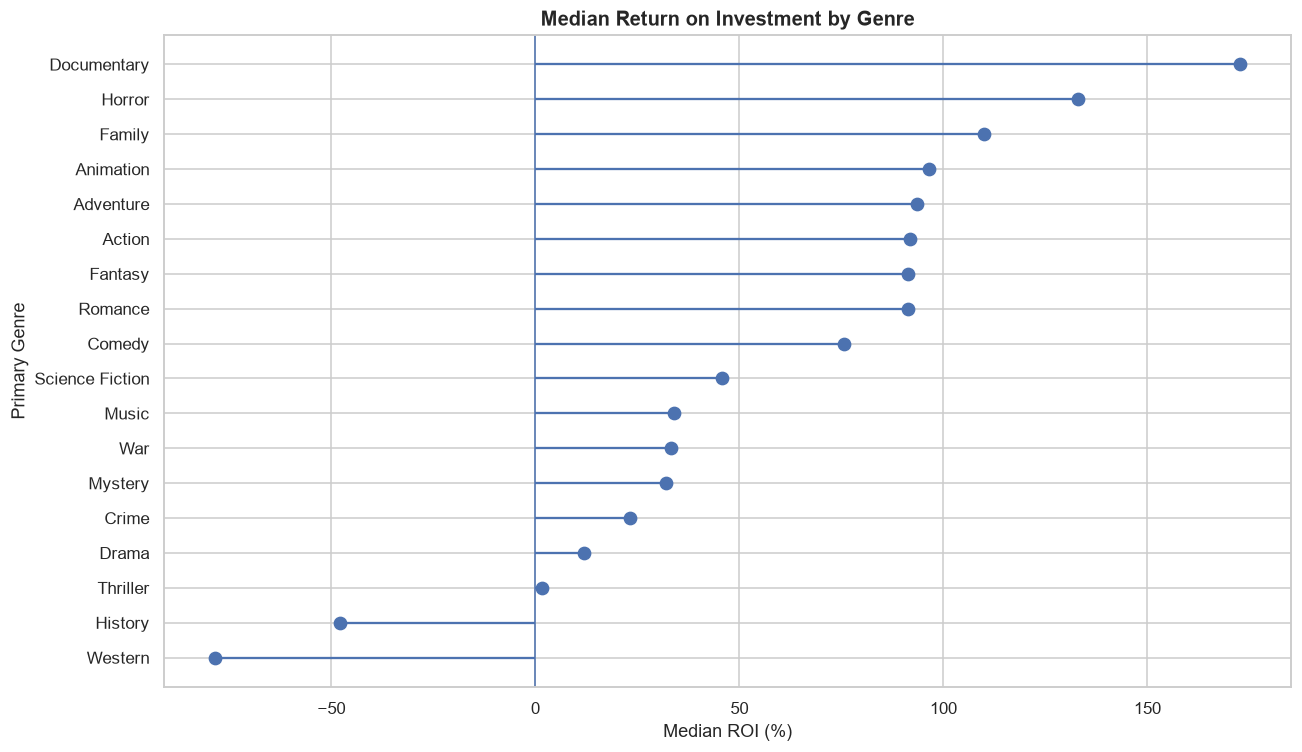

In [26]:

# Keep valid ROI values
roi_df = df[
    df["roi_percent"].notna()
    & df["primary_genre"].notna()
].copy()

# Calculate median ROI for each genre
median_roi = (
    roi_df.groupby("primary_genre")["roi_percent"]
    .median()
    .sort_values()
)

# Create lollipop chart
plt.figure(figsize=(12, 7))

plt.hlines(
    y=median_roi.index,
    xmin=0,
    xmax=median_roi.values,
    linewidth=1.5
)

plt.plot(
    median_roi.values,
    median_roi.index,
    "o",
    markersize=8
)

plt.axvline(0, linewidth=1)
plt.xlabel("Median ROI (%)")
plt.ylabel("Primary Genre")
plt.title("Median Return on Investment by Genre")
plt.tight_layout()
plt.show()

**Interpretation:** The dumbbell plot compares median ROI across different movie genres, highlighting differences in financial returns. Genres with higher median ROI show stronger returns relative to production budgets, while genres with lower median ROI show comparatively weaker returns.

#### Plot 10: Share of movies earning back their budget, by budget tier

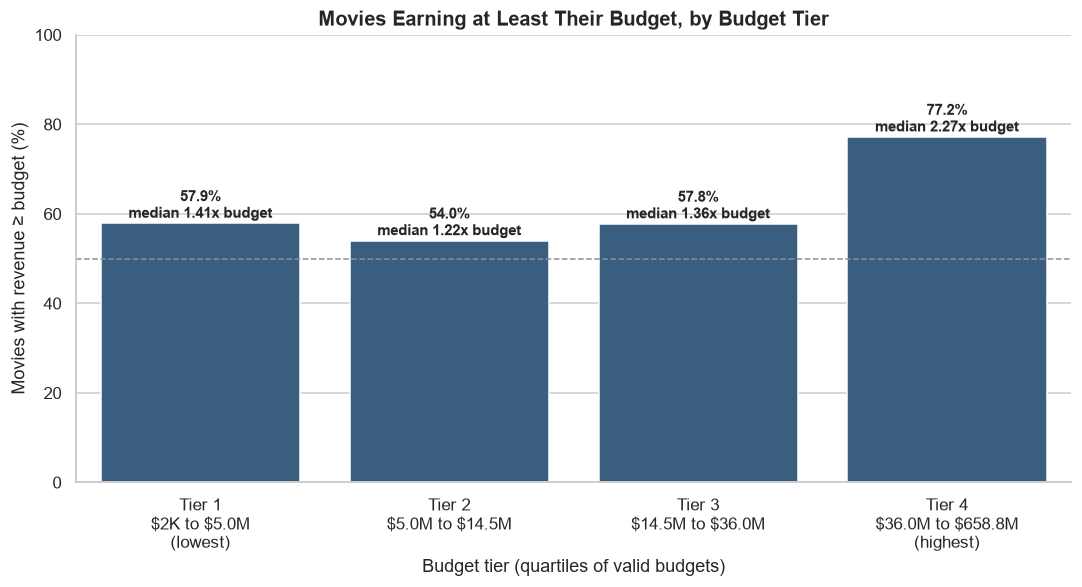

,movies,pct_back,median_multiple,pct_2x
budget_tier,,,,
Tier 1 $2K to $5.0M (lowest),1055,57.9,1.4,43.6
Tier 2 $5.0M to $14.5M,992,54.0,1.2,37.9
Tier 3 $14.5M to $36.0M,1021,57.8,1.4,37.4
Tier 4 $36.0M to $658.8M (highest),1022,77.2,2.3,56.3


Valid records: 4,090


In [27]:
edges = fin["budget_eda"].quantile([0, .25, .5, .75, 1]).values
money = lambda v: f"${v / 1e3:,.0f}K" if v < 1e6 else f"${v / 1e6:,.1f}M"
tier_labels = [f"Tier {i + 1}\n{money(edges[i])} to {money(edges[i + 1])}" for i in range(4)]
tier_labels[0] = tier_labels[0] + "\n(lowest)"
tier_labels[3] = tier_labels[3] + "\n(highest)"
fin["budget_tier"] = pd.qcut(fin["budget_eda"], 4, labels=tier_labels)
fin["multiple"] = fin["revenue_eda"] / fin["budget_eda"]

tier_tbl = (fin.groupby("budget_tier", observed=True)
            .agg(movies=("title", "count"), pct_back=("multiple", lambda s: (s >= 1).mean() * 100),
                 median_multiple=("multiple", "median"), pct_2x=("multiple", lambda s: (s >= 2).mean() * 100)))

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(x=tier_tbl.index, y=tier_tbl["pct_back"], color=ACCENT, ax=ax)
for i, (p, m) in enumerate(zip(tier_tbl["pct_back"], tier_tbl["median_multiple"])):
    ax.text(i, p + 1.2, f"{p:.1f}%\nmedian {m:.2f}x budget", ha="center", fontsize=10, fontweight="bold")
ax.set_xticks(range(4))
ax.set_xticklabels([l.replace("$", "\\$") for l in tier_tbl.index])   # escape $ so Matplotlib does not read math text
ax.axhline(50, color=GREY, ls="--", lw=1)
ax.set(title="Movies Earning at Least Their Budget, by Budget Tier", xlabel="Budget tier (quartiles of valid budgets)",
       ylabel="Movies with revenue ≥ budget (%)", ylim=(0, 100))
sns.despine()
plt.tight_layout()
plt.show()

display(tier_tbl.rename(index=lambda x: x.replace("\n", " ")).round(1))
print(f"Valid records: {len(fin):,}")

**Interpretation:** The highest budget tier has the largest share of movies earning back their reported budget. The lower three tiers have more similar break-even rates.

#### Plot 11: Release seasonality (year × month heatmap)

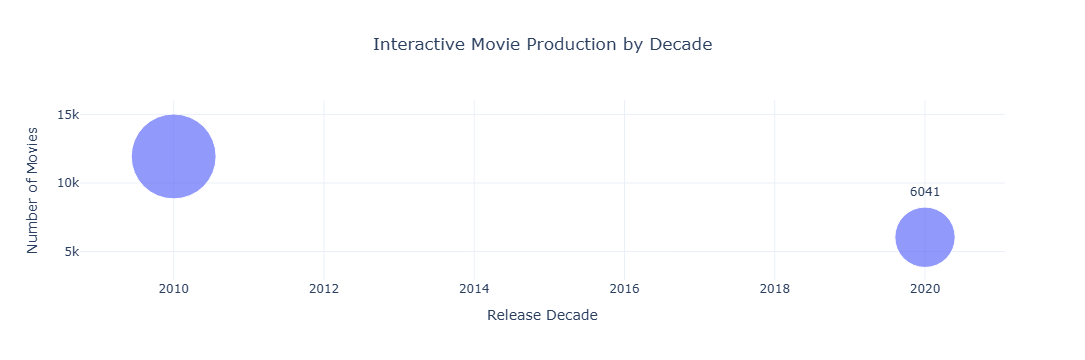

In [28]:
decade_df = df[df["release_decade"].notna()].copy()
decade_counts = (
    decade_df.groupby("release_decade")
    .size()
    .reset_index(name="movie_count")
    .sort_values("release_decade")
)
fig = px.scatter(
    decade_counts,
    x="release_decade",
    y="movie_count",
    size="movie_count",
    hover_name="release_decade",
    hover_data={"movie_count": True},
    size_max=60,
    title="Interactive Movie Production by Decade",
    labels={
        "release_decade": "Release Decade",
        "movie_count": "Number of Movies"
    }
)
fig.update_layout(
    template="plotly_white",
    title_x=0.5
)
fig.update_traces(
    marker=dict(opacity=0.7),
    mode="markers+text",
    text=decade_counts["movie_count"],
    textposition="top center"
)
fig.show()

**Interpretation:** The bubble plot illustrates movie production across different decades and primary genres. Each bubble represents a genre within a decade, and its size indicates the number of movies produced. Larger bubbles represent more movies, while smaller bubbles indicate fewer movies.



#### Plot 12: Top 10 highest-grossing movies (budget vs revenue)

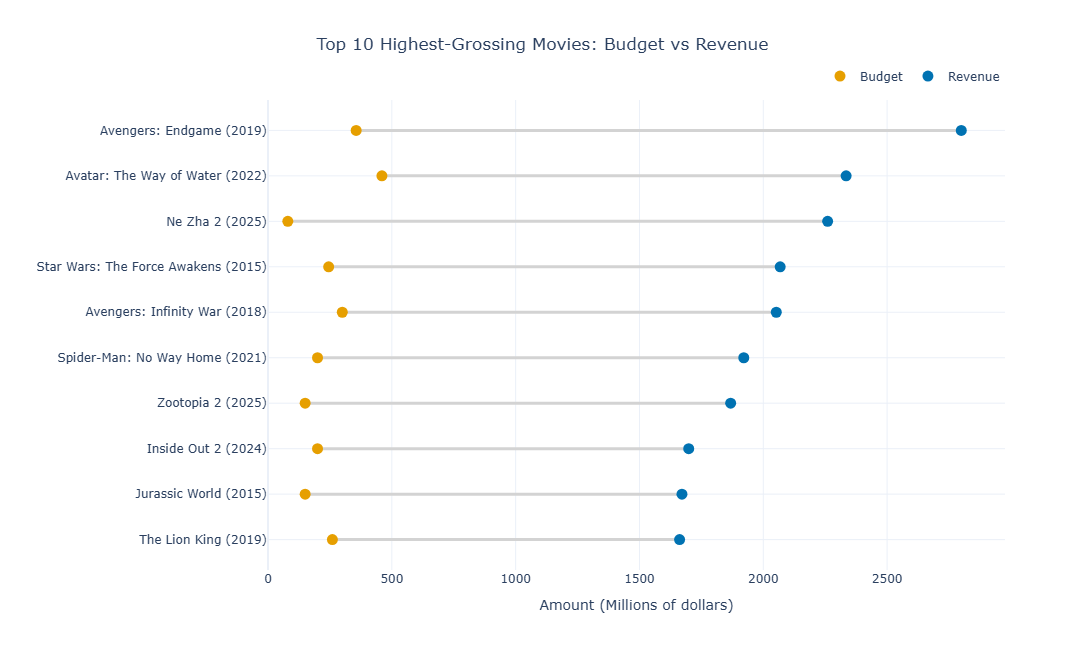

TOP 10 HIGHEST-GROSSING MOVIES

                       title  release_year  budget_eda  revenue_eda  multiple
           Avengers: Endgame          2019 356000000.0 2799439100.0       7.9
    Avatar: The Way of Water          2022 460000000.0 2334484620.0       5.1
                    Ne Zha 2          2025  80000000.0 2259822417.0      28.2
Star Wars: The Force Awakens          2015 245000000.0 2068223624.0       8.4
      Avengers: Infinity War          2018 300000000.0 2052415039.0       6.8
     Spider-Man: No Way Home          2021 200000000.0 1921206586.0       9.6
                  Zootopia 2          2025 150000000.0 1868208796.0      12.5
                Inside Out 2          2024 200000000.0 1698863816.0       8.5
              Jurassic World          2015 150000000.0 1671537444.0      11.1
               The Lion King          2019 260000000.0 1662020819.0       6.4

Top 10 share of total revenue among 4,090 valid movies: 5.1%
Median revenue multiple, top 10: 8.5x | all vali

In [29]:

# Select the top 10 movies by revenue
top10 = fin.nlargest(10, "revenue_eda").sort_values("revenue_eda").copy()
# Calculate revenue multiple safely
top10["multiple"] = np.where(top10["budget_eda"] > 0, top10["revenue_eda"] / top10["budget_eda"], np.nan)
# Convert values to millions
top10["budget_m"] = top10["budget_eda"] / 1e6
top10["revenue_m"] = top10["revenue_eda"] / 1e6
# Labels for movie names and release years
top10["movie_label"] = top10["title"].astype(str) + " (" + top10["release_year"].fillna(0).astype(int).astype(str) + ")"
# Create interactive figure
fig = go.Figure()
# Budget-to-revenue connecting lines
for _, row in top10.iterrows():
    fig.add_trace(go.Scatter(x=[row["budget_m"], row["revenue_m"]], y=[row["movie_label"], row["movie_label"]], mode="lines", line=dict(color="lightgray", width=3), hoverinfo="skip", showlegend=False))
# Budget markers
fig.add_trace(go.Scatter(x=top10["budget_m"], y=top10["movie_label"], mode="markers", name="Budget", marker=dict(size=11, color="#E69F00"), customdata=np.column_stack([top10["title"], top10["release_year"].fillna(0), top10["budget_eda"], top10["revenue_eda"], top10["multiple"]]), hovertemplate="<b>%{customdata[0]}</b> (%{customdata[1]:.0f})<br>Budget: $%{customdata[2]:,.0f}<br>Revenue: $%{customdata[3]:,.0f}<br>Revenue multiple: %{customdata[4]:.2f}x<extra>Budget</extra>"))
# Revenue markers
fig.add_trace(go.Scatter(x=top10["revenue_m"], y=top10["movie_label"], mode="markers", name="Revenue", marker=dict(size=11, color="#0072B2"), customdata=np.column_stack([top10["title"], top10["release_year"].fillna(0), top10["budget_eda"], top10["revenue_eda"], top10["multiple"]]), hovertemplate="<b>%{customdata[0]}</b> (%{customdata[1]:.0f})<br>Budget: $%{customdata[2]:,.0f}<br>Revenue: $%{customdata[3]:,.0f}<br>Revenue multiple: %{customdata[4]:.2f}x<extra>Revenue</extra>"))
fig.update_layout(title="Top 10 Highest-Grossing Movies: Budget vs Revenue", title_x=0.5, xaxis_title="Amount (Millions of dollars)", yaxis_title="", template="plotly_white", height=650, hovermode="closest", legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1))
fig.update_xaxes(rangemode="tozero")
fig.show()
# Display summary table
top10_tbl = top10.sort_values("revenue_eda", ascending=False).copy()
print("TOP 10 HIGHEST-GROSSING MOVIES\n")
print(top10_tbl[["title", "release_year", "budget_eda", "revenue_eda", "multiple"]].round(1).to_string(index=False))
print(f"\nTop 10 share of total revenue among {len(fin):,} valid movies: {top10['revenue_eda'].sum() / fin['revenue_eda'].sum() * 100:.1f}%")
print(f"Median revenue multiple, top 10: {top10_tbl['multiple'].median():.1f}x | all valid movies: {(fin.loc[fin['budget_eda'] > 0, 'revenue_eda'] / fin.loc[fin['budget_eda'] > 0, 'budget_eda']).median():.2f}x")


**Interpretation:** The top-grossing titles include movies with very different revenue-to-budget multiples. High gross revenue alone does not establish overall profitability.

## 17. EDA summary

**EDA summary:** Releases peaked in 2018; Drama and Comedy dominate the genre mix, and budget is positively associated with revenue. Ratings relate only weakly to popularity, while missing financial values and the dataset’s vote filter limit generalisation.

## 18. Descriptive analysis: fifteen questions

Each question below has its own calculation, interactive Plotly visualization and data-dependent interpretation. Financial comparisons use observed reported values rather than imputed financial values.


### 18.0 Helper functions

Shared plotting and formatting helpers used by the fifteen questions and the hypothesis tests.

In [30]:
# If Plotly is missing, uncomment and run:
# %pip install plotly

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, Markdown
from scipy import stats

TEMPLATE = "plotly_white"
PALETTE = px.colors.qualitative.Safe
ACCENT, ACCENT2, GREY = "#2E5E8C", "#E07A3F", "#8A8F98"
MONEY_TICKS = [1e3, 1e4, 1e5, 1e6, 1e7, 1e8, 1e9, 1e10]
MONEY_TEXT = ["$1K", "$10K", "$100K", "$1M", "$10M", "$100M", "$1B", "$10B"]


def fmt_money(v):
    if pd.isna(v):
        return "n/a"
    if abs(v) >= 1e9:
        return f"${v / 1e9:,.2f}B"
    if abs(v) >= 1e6:
        return f"${v / 1e6:,.1f}M"
    return f"${v / 1e3:,.0f}K"


def box_stats(values, log=False):
    v = pd.Series(values, dtype="float64").dropna()
    if v.empty:
        return pd.Series({k: np.nan for k in ["n", "q1", "median", "q3", "lowerfence", "upperfence", "mean"]})
    q1, med, q3 = v.quantile([0.25, 0.50, 0.75])
    w = np.log10(v) if log else v
    wq1, wq3 = w.quantile([0.25, 0.75])
    wiqr = wq3 - wq1
    inside = v[(w >= wq1 - 1.5 * wiqr) & (w <= wq3 + 1.5 * wiqr)]
    return pd.Series({"n": len(v), "q1": q1, "median": med, "q3": q3,
                      "lowerfence": inside.min(), "upperfence": inside.max(), "mean": v.mean()})


def money_box(values):
    return box_stats(values, log=True)


def add_box(fig, stats_tbl, labels, name=None, color=ACCENT, horizontal=False, row=None, col=None, showlegend=False):
    args = dict(q1=stats_tbl["q1"].tolist(), median=stats_tbl["median"].tolist(),
                q3=stats_tbl["q3"].tolist(), lowerfence=stats_tbl["lowerfence"].tolist(),
                upperfence=stats_tbl["upperfence"].tolist(), mean=stats_tbl["mean"].tolist(),
                name=name, marker_color=color, line_width=1.5, boxpoints=False, showlegend=showlegend)
    if horizontal:
        args.update(y=list(labels), orientation="h")
    else:
        args.update(x=list(labels))
    fig.add_trace(go.Box(**args), row=row, col=col)
    return fig


def money_axis(fig, axis="y", title="Revenue (USD, log scale)", **kw):
    upd = dict(type="log", tickvals=MONEY_TICKS, ticktext=MONEY_TEXT, title_text=title, hoverformat="$,.0f", **kw)
    (fig.update_yaxes if axis == "y" else fig.update_xaxes)(**upd)
    return fig


def finish(fig, title, height=550, margin=None, **layout):
    fig.update_layout(template=TEMPLATE, title=dict(text=title, x=0.01, xanchor="left"),
                      height=height, margin=margin or dict(t=80, l=60, r=30, b=60), **layout)
    fig.show()


def show_interpretation(text):
    display(Markdown("**Interpretation.** " + text))


def split_multi(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (list, tuple, set)):
        parts = [str(x).strip() for x in value if str(x).strip()]
    else:
        txt = str(value).strip()
        if txt.lower() in {"", "nan", "none", "null", "unknown"}:
            return np.nan
        parsed = None
        if txt.startswith("["):
            try:
                parsed = json.loads(txt)
            except (json.JSONDecodeError, TypeError):
                try:
                    parsed = ast.literal_eval(txt)
                except (ValueError, SyntaxError):
                    parsed = None
        if isinstance(parsed, list):
            parts = [str(x).strip() for x in parsed if str(x).strip()]
        else:
            parts = [x.strip() for x in re.split(r"\s*[|,]\s*", txt) if x.strip()]
    parts = list(dict.fromkeys(parts))
    return parts if parts else np.nan


print("Plotly helpers ready.")


Plotly helpers ready.


### 18.1 Analysis columns and group definitions

The analysis copy is built from the cleaned DataFrame, then observed numeric and category fields are restored from the original raw rows using the retained row index. This prevents median/mode imputation from fabricating ratings, popularity, vote counts, runtimes, financial figures, languages, genres or countries for the EDA.


In [31]:
# Create analysis copy and align the original raw records to the retained rows in df.
eda = df.copy()
raw_std = df_raw.copy()
raw_std.columns = (raw_std.columns.astype(str).str.strip().str.lower()
                   .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
raw_std = raw_std.reindex(eda.index)

required = ["title", "release_date", "genres", "budget", "revenue", "runtime",
            "vote_average", "vote_count", "popularity", "original_language", "production_countries"]
missing_required = [c for c in required if c not in raw_std.columns]
if missing_required:
    raise KeyError(f"Required source columns not found in the raw dataset: {missing_required}")

ana = eda.copy()

# Use source-observed values for analysis fields; do not analyse imputed values as if observed.
for col in ["budget", "revenue", "runtime", "vote_average", "vote_count", "popularity"]:
    ana[col] = pd.to_numeric(raw_std[col], errors="coerce")
    ana.loc[ana[col] < 0, col] = np.nan

ana.loc[~ana["vote_average"].between(0, 10), "vote_average"] = np.nan
ana["budget_eda"] = ana["budget"].where(ana["budget"] >= 1_000)
ana["revenue_eda"] = ana["revenue"].where(ana["revenue"] >= 1_000)
ana["runtime_eda"] = ana["runtime"].where(ana["runtime"] > 0)

# Restore original category fields so imputed mode values are not mistaken for observed metadata.
for col in ["genres", "original_language", "production_countries"]:
    ana[col] = raw_std[col].where(raw_std[col].notna())
    ana[col] = ana[col].apply(lambda v: str(v).strip() if isinstance(v, str) else v)
    ana.loc[ana[col].astype("string").str.lower().isin(["", "nan", "none", "null"]), col] = np.nan

ana["genre_list"] = ana["genres"].apply(split_multi)
ana["genre"] = ana["genre_list"]
ana["n_genres"] = ana["genre_list"].apply(lambda g: len(g) if isinstance(g, list) else np.nan)
ana["genre_count_group"] = pd.cut(ana["n_genres"], [0, 1, 2, np.inf],
                                  labels=["Single genre", "Two genres", "Three or more genres"])

ana["country_list"] = ana["production_countries"].apply(split_multi)

lang_names = {"en": "English", "hi": "Hindi", "es": "Spanish", "fr": "French", "ja": "Japanese",
              "ko": "Korean", "zh": "Chinese", "de": "German", "it": "Italian", "pt": "Portuguese",
              "ru": "Russian", "ta": "Tamil", "te": "Telugu", "ml": "Malayalam", "tr": "Turkish",
              "cn": "Cantonese", "th": "Thai", "id": "Indonesian", "ar": "Arabic", "pl": "Polish",
              "sv": "Swedish", "da": "Danish", "nl": "Dutch", "kn": "Kannada", "bn": "Bengali"}
ana["language_name"] = ana["original_language"].map(lambda c: lang_names.get(c, c) if pd.notna(c) else np.nan)

# Release periods: inclusive year bands 2010–2013, 2014–2017, 2018–2021 and 2022–2025.
ana["release_year"] = pd.to_numeric(ana["release_year"], errors="coerce")
PERIODS = ["2010–2013", "2014–2017", "2018–2021", "2022–2025"]
ana["release_period"] = pd.cut(ana["release_year"], [2009, 2013, 2017, 2021, 2025], labels=PERIODS)

BUDGET_RANGES = ["Under $1M", "$1M–10M", "$10M–50M", "$50M–100M", "$100M+"]
ana["budget_range"] = pd.cut(ana["budget_eda"], [0, 1e6, 1e7, 5e7, 1e8, np.inf],
                             right=False, labels=BUDGET_RANGES)
BUDGET_GROUPS = ["Low (< $10M)", "Mid ($10M–50M)", "High (≥ $50M)"]
ana["budget_group"] = pd.cut(ana["budget_eda"], [0, 1e7, 5e7, np.inf],
                             right=False, labels=BUDGET_GROUPS)

VOTE_GROUPS = ["Low (50–99 votes)", "Medium (100–999 votes)", "High (1,000+ votes)"]
ana["vote_group"] = pd.cut(ana["vote_count"], [50, 100, 1000, np.inf],
                           right=False, labels=VOTE_GROUPS)
RUNTIME_GROUPS = ["Under 40 min (short film)", "Short feature (40–89 min)",
                  "Medium (90–119 min)", "Long (120+ min)"]
ana["runtime_group"] = pd.cut(ana["runtime_eda"], [0, 40, 90, 120, np.inf],
                             right=False, labels=RUNTIME_GROUPS)

ana["earned_back"] = np.where(ana["budget_eda"].notna() & ana["revenue_eda"].notna(),
                              ana["revenue_eda"] >= ana["budget_eda"], np.nan)
fin2 = ana.dropna(subset=["budget_eda", "revenue_eda"]).copy()
fin2["earned_back"] = fin2["earned_back"].astype(bool)

coverage = pd.Series({
    "All retained movies": len(ana),
    "Observed genre lists": int(ana["genre_list"].apply(lambda x: isinstance(x, list)).sum()),
    "Observed country lists": int(ana["country_list"].apply(lambda x: isinstance(x, list)).sum()),
    "Observed budgets >= $1,000": int(ana["budget_eda"].notna().sum()),
    "Observed revenue >= $1,000": int(ana["revenue_eda"].notna().sum()),
    "Complete valid financial pairs": len(fin2),
    "Observed runtime > 0": int(ana["runtime_eda"].notna().sum()),
    "Observed ratings": int(ana["vote_average"].notna().sum()),
    "Observed popularity": int(ana["popularity"].notna().sum()),
}, name="records")
display(coverage.to_frame())

for col in ["release_period", "budget_range", "budget_group", "vote_group", "runtime_group", "genre_count_group"]:
    print(f"{col}: " + ", ".join(f"{k} = {v:,}" for k, v in ana[col].value_counts(sort=False).items()))
print("Financial values below $1,000 are excluded from financial comparisons; valid extreme values are retained.")


,records
All retained movies,17978
Observed genre lists,17968
Observed country lists,17802
"Observed budgets >= $1,000",5480
"Observed revenue >= $1,000",6777
Complete valid financial pairs,4090
Observed runtime > 0,17932
Observed ratings,17978
Observed popularity,17978


release_period: 2010–2013 = 3,934, 2014–2017 = 5,181, 2018–2021 = 5,024, 2022–2025 = 3,839
budget_range: Under $1M = 449, $1M–10M = 2,177, $10M–50M = 2,008, $50M–100M = 435, $100M+ = 411
budget_group: Low (< $10M) = 2,626, Mid ($10M–50M) = 2,008, High (≥ $50M) = 846
vote_group: Low (50–99 votes) = 6,243, Medium (100–999 votes) = 9,240, High (1,000+ votes) = 2,495
runtime_group: Under 40 min (short film) = 481, Short feature (40–89 min) = 3,954, Medium (90–119 min) = 10,852, Long (120+ min) = 2,645
genre_count_group: Single genre = 4,362, Two genres = 6,194, Three or more genres = 7,412
Financial values below $1,000 are excluded from financial comparisons; valid extreme values are retained.


In [32]:
# Long tables for multi-genre and multi-country comparisons.
genre_long = (ana.loc[ana["genre_list"].apply(lambda x: isinstance(x, list)),
                      ["movie_id", "title", "release_year", "release_period", "genre_list", "budget_eda",
                       "revenue_eda", "budget_range", "budget_group", "vote_average", "vote_count"]]
              .explode("genre_list").rename(columns={"genre_list": "genre"}))
country_long = (ana.loc[ana["country_list"].apply(lambda x: isinstance(x, list)),
                        ["movie_id", "title", "country_list", "budget_eda", "revenue_eda", "vote_average"]]
                .explode("country_list").rename(columns={"country_list": "country"}))

print(f"genre_long: {len(genre_long):,} movie-genre rows from {genre_long['movie_id'].nunique():,} movies, "
      f"{genre_long['genre'].nunique()} genres")
print(f"country_long: {len(country_long):,} movie-country rows from {country_long['movie_id'].nunique():,} movies, "
      f"{country_long['country'].nunique()} countries")


genre_long: 41,797 movie-genre rows from 17,968 movies, 19 genres
country_long: 25,412 movie-country rows from 17,802 movies, 137 countries


### Question 1: How does box-office revenue compare across different production-budget ranges?

Movies with a valid budget and revenue (`fin2`) are put into the five fixed budget ranges from section 18.1. For each range we compare the revenue distribution (quartiles), the median and mean revenue, and the share of movies whose revenue reached at least their budget.

In [33]:
q1_tbl = (fin2.groupby("budget_range", observed=True)
          .agg(movies=("title", "size"),
               median_budget=("budget_eda", "median"),
               median_revenue=("revenue_eda", "median"),
               mean_revenue=("revenue_eda", "mean"),
               pct_revenue_ge_budget=("earned_back", lambda s: s.mean() * 100)))
q1_tbl["median_revenue_to_budget"] = q1_tbl["median_revenue"] / q1_tbl["median_budget"]

display(q1_tbl.style.format({"movies": "{:,}", "median_budget": fmt_money, "median_revenue": fmt_money,
                             "mean_revenue": fmt_money, "pct_revenue_ge_budget": "{:.1f}%",
                             "median_revenue_to_budget": "{:.2f}x"}))
print(f"Valid records: {len(fin2):,} movies with both budget and revenue")

,movies,median_budget,median_revenue,mean_revenue,pct_revenue_ge_budget,median_revenue_to_budget
budget_range,,,,,,
Under $1M,198,$300K,$708K,$5.1M,70.7%,2.36x
$1M–10M,"1,386",$4.8M,$5.0M,$15.5M,54.7%,1.04x
$10M–50M,"1,707",$20.0M,$29.2M,$54.0M,57.4%,1.46x
$50M–100M,401,$65.0M,$146.7M,$199.0M,75.8%,2.26x
$100M+,398,$150.0M,$404.0M,$508.4M,86.4%,2.69x


Valid records: 4,090 movies with both budget and revenue


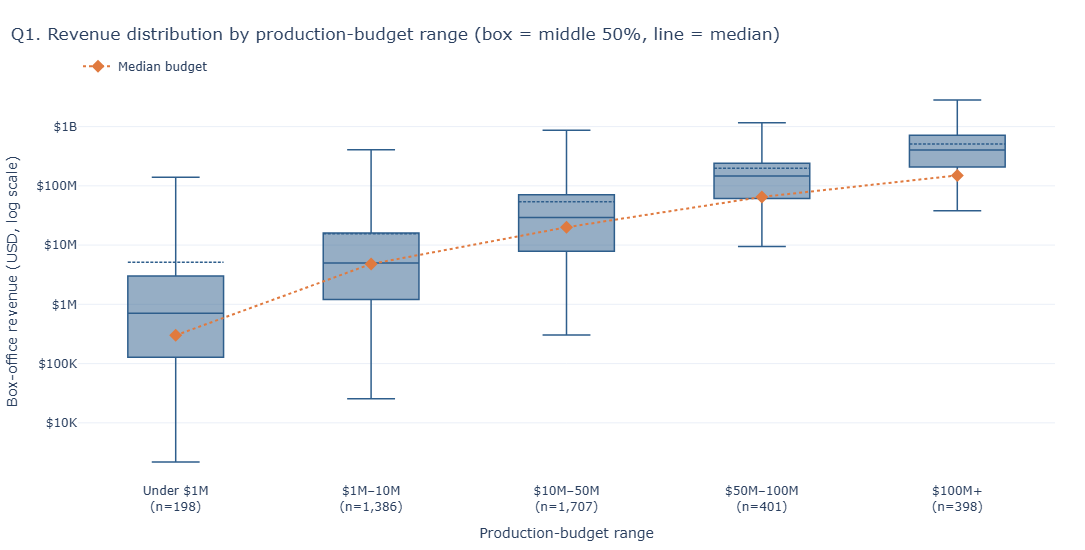

In [34]:
q1_box = fin2.groupby("budget_range", observed=True)["revenue_eda"].apply(money_box).unstack()
q1_labels = [f"{r}<br>(n={int(n):,})" for r, n in zip(q1_box.index, q1_box["n"])]

fig = go.Figure()
add_box(fig, q1_box, q1_labels, name="Revenue", color=ACCENT)
fig.add_trace(go.Scatter(x=q1_labels, y=q1_tbl["median_budget"], mode="markers+lines", name="Median budget",
                         marker=dict(symbol="diamond", size=10, color=ACCENT2), line=dict(dash="dot"),
                         hovertemplate="Median budget: %{y:$,.0f}<extra></extra>"))
money_axis(fig, "y", "Box-office revenue (USD, log scale)")
fig.update_xaxes(title_text="Production-budget range")
finish(fig, "Q1. Revenue distribution by production-budget range (box = middle 50%, line = median)",
       legend=dict(orientation="h", y=1.07, x=0))

In [35]:
if not q1_tbl.empty:
    high = q1_tbl["median_revenue"].idxmax()
    low = q1_tbl["median_revenue"].idxmin()
    show_interpretation(
        f"Median revenue is highest in **{high}** ({fmt_money(q1_tbl.loc[high, 'median_revenue'])}) "
        f"and lowest in **{low}** ({fmt_money(q1_tbl.loc[low, 'median_revenue'])}). "
        f"The table also reports the share of movies whose reported revenue reached their reported budget. "
        f"These are descriptive comparisons among {len(fin2):,} movies with both budget and revenue reported; "
        f"gross revenue reaching the production budget does not establish profitability."
    )
else:
    show_interpretation("There are not enough valid budget-and-revenue records to compare budget ranges.")


**Interpretation.** Median revenue is highest in **$100M+** ($404.0M) and lowest in **Under $1M** ($708K). The table also reports the share of movies whose reported revenue reached their reported budget. These are descriptive comparisons among 4,090 movies with both budget and revenue reported; gross revenue reaching the production budget does not establish profitability.

### Question 2: Which movie genres have the highest median revenue, and how do their revenue distributions differ?

Every movie with a valid revenue (budget not required) is counted once in **each** of its genres, so a movie tagged `Action|Adventure` adds its revenue to both groups. Genres with fewer than 30 valid revenue records are left out because their medians would be unstable. The spread inside each genre is summarised with the interquartile range (IQR) and the ratio Q3/Q1.

In [36]:
MIN_GENRE_N = 30
q2_long = genre_long.dropna(subset=["revenue_eda"])
q2_counts = q2_long["genre"].value_counts()
q2_long = q2_long[q2_long["genre"].isin(q2_counts[q2_counts >= MIN_GENRE_N].index)]

q2_tbl = q2_long.groupby("genre")["revenue_eda"].apply(money_box).unstack()
q2_tbl["q3_over_q1"] = q2_tbl["q3"] / q2_tbl["q1"]
q2_tbl = q2_tbl.sort_values("median", ascending=False)

display(q2_tbl[["n", "median", "mean", "q1", "q3", "q3_over_q1"]].style.format(
    {"n": "{:,.0f}", "median": fmt_money, "mean": fmt_money, "q1": fmt_money, "q3": fmt_money, "q3_over_q1": "{:.1f}x"}))
print(f"Movies with valid revenue and genre: {q2_long['movie_id'].nunique():,} | "
      f"genres dropped (< {MIN_GENRE_N} records): {list(q2_counts[q2_counts < MIN_GENRE_N].index) or 'none'}")

,n,median,mean,q1,q3,q3_over_q1
genre,,,,,,
Adventure,"1,026",$41.0M,$196.3M,$6.2M,$226.3M,36.5x
Family,619,$30.0M,$146.5M,$6.7M,$150.8M,22.5x
Action,"1,548",$27.4M,$127.7M,$2.9M,$122.1M,42.1x
Science Fiction,627,$23.1M,$176.6M,$1.2M,$203.2M,171.3x
Fantasy,724,$18.6M,$126.8M,$2.1M,$119.6M,57.5x
Animation,624,$17.9M,$125.5M,$3.5M,$108.2M,30.6x
Comedy,"2,225",$8.9M,$61.1M,$1.5M,$46.2M,31.8x
War,228,$8.2M,$57.2M,$1.4M,$37.0M,27.0x
Crime,879,$7.6M,$48.7M,$900K,$43.4M,48.2x


Movies with valid revenue and genre: 6,777 | genres dropped (< 30 records): ['TV Movie']


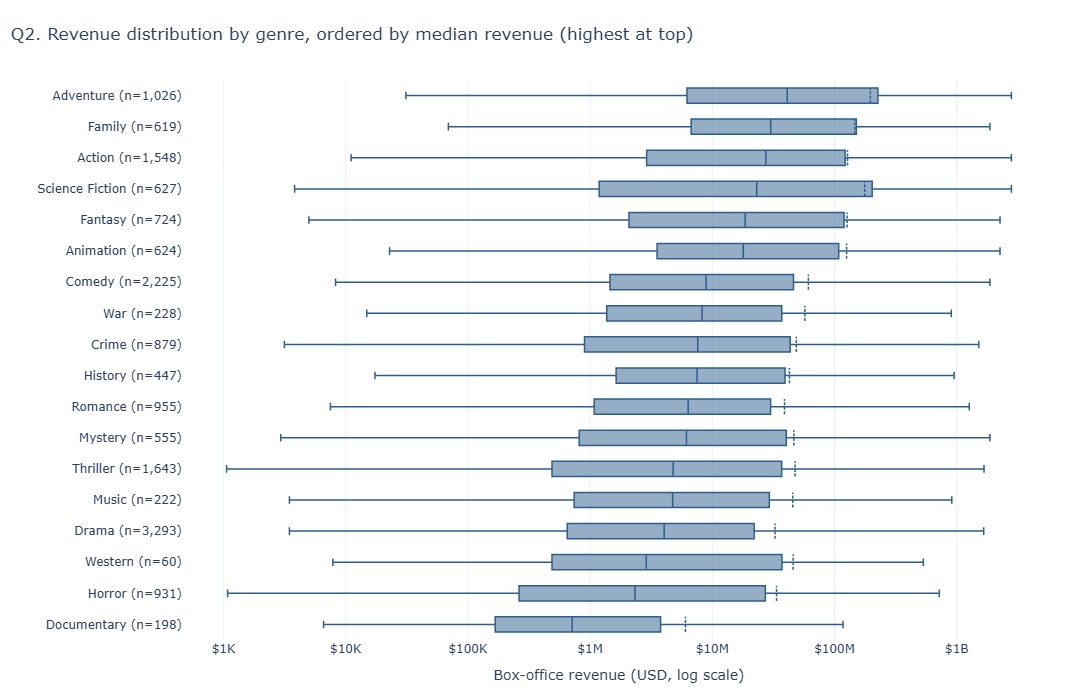

In [37]:
q2_labels = [f"{g} (n={int(n):,})" for g, n in zip(q2_tbl.index, q2_tbl["n"])]
fig = go.Figure()
add_box(fig, q2_tbl, q2_labels, color=ACCENT, horizontal=True)
money_axis(fig, "x", "Box-office revenue (USD, log scale)")
fig.update_yaxes(title_text="", categoryorder="array", categoryarray=q2_labels[::-1])
finish(fig, "Q2. Revenue distribution by genre, ordered by median revenue (highest at top)", height=700)

In [38]:
if not q2_tbl.empty:
    high = q2_tbl["median"].idxmax()
    low = q2_tbl["median"].idxmin()
    show_interpretation(
        f"Among genres meeting the minimum-record threshold, **{high}** has the highest median revenue "
        f"({fmt_money(q2_tbl.loc[high, 'median'])}), while **{low}** has the lowest "
        f"({fmt_money(q2_tbl.loc[low, 'median'])}). A movie may contribute to several genres, so genre groups overlap. "
        f"Revenue reporting rates and extreme blockbusters can affect the distributions."
    )
else:
    show_interpretation("No genre has enough valid reported-revenue records for this comparison.")


**Interpretation.** Among genres meeting the minimum-record threshold, **Adventure** has the highest median revenue ($41.0M), while **Documentary** has the lowest ($713K). A movie may contribute to several genres, so genre groups overlap. Revenue reporting rates and extreme blockbusters can affect the distributions.

### Question 3: Within the ten genres with the most valid financial records, how does revenue compare across low-, medium- and high-budget movies?

The comparison uses the ten genres with the most valid budget-and-revenue records, and three budget groups. Movies with multiple genres appear in each applicable genre, so genre-level counts can overlap.


In [39]:
MIN_CELL_N = 10
q3_long = genre_long.dropna(subset=["budget_eda", "revenue_eda"])
top_genres_fin = q3_long["genre"].value_counts().head(10).index.tolist()
q3_long = q3_long[q3_long["genre"].isin(top_genres_fin)]

q3_tbl = (q3_long.groupby(["genre", "budget_group"], observed=False)["revenue_eda"]
          .agg(movies="size", median_revenue="median",
               q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75))
          .reset_index())
q3_tbl.loc[q3_tbl["movies"] < MIN_CELL_N, ["median_revenue", "q1", "q3"]] = np.nan

q3_wide = q3_tbl.pivot(index="genre", columns="budget_group", values="median_revenue").loc[top_genres_fin]
q3_wide["High / Low"] = q3_wide[BUDGET_GROUPS[2]] / q3_wide[BUDGET_GROUPS[0]]
display(q3_wide.style.format({**{g: fmt_money for g in BUDGET_GROUPS}, "High / Low": "{:.1f}x"}))
display(q3_tbl.pivot(index="genre", columns="budget_group", values="movies").loc[top_genres_fin])

budget_group,Low (< $10M),Mid ($10M–50M),High (≥ $50M),High / Low
genre,,,,
Drama,$3.6M,$22.7M,$140.5M,39.0x
Comedy,$5.2M,$36.2M,$212.9M,40.7x
Action,$4.5M,$30.9M,$274.7M,61.7x
Thriller,$3.3M,$23.4M,$191.8M,58.4x
Adventure,$4.6M,$29.3M,$348.6M,76.1x
Crime,$3.5M,$30.1M,$177.6M,50.7x
Romance,$5.3M,$32.8M,$149.5M,28.1x
Horror,$3.2M,$49.2M,$186.3M,58.4x
Fantasy,$2.3M,$22.4M,$223.6M,95.2x


budget_group,Low (< $10M),Mid ($10M–50M),High (≥ $50M)
genre,,,
Drama,864,860,197
Comedy,523,553,267
Action,230,458,403
Thriller,445,471,154
Adventure,121,246,386
Crime,210,274,86
Romance,240,270,58
Horror,318,204,38
Fantasy,97,141,208


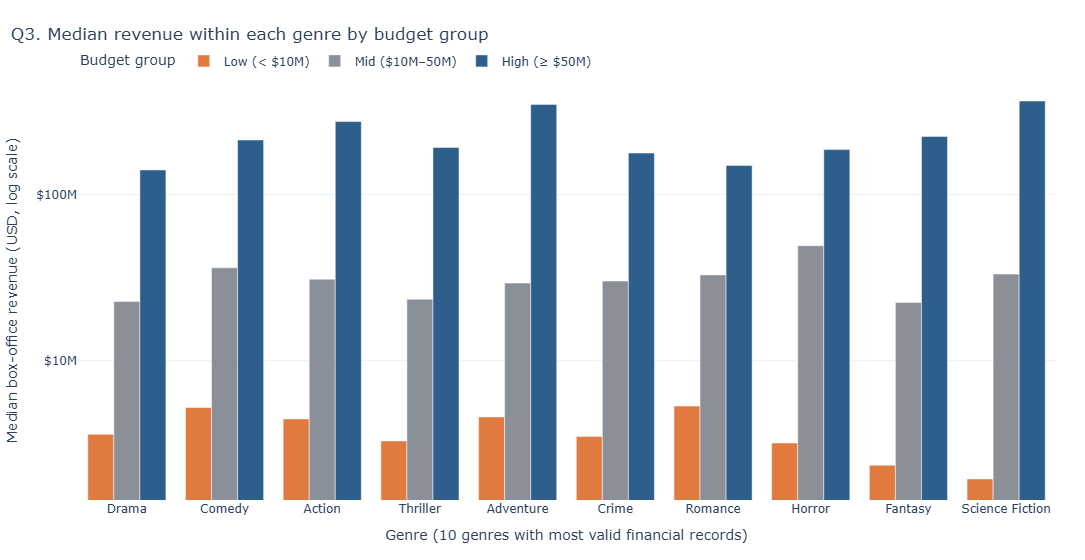

In [40]:
fig = go.Figure()
for i, grp in enumerate(BUDGET_GROUPS):
    d = q3_tbl[q3_tbl["budget_group"] == grp].set_index("genre").loc[top_genres_fin].reset_index()
    fig.add_trace(go.Bar(
        x=d["genre"], y=d["median_revenue"], name=grp, marker_color=[ACCENT2, GREY, ACCENT][i],
        customdata=np.stack([d["movies"], d["q1"], d["q3"]], axis=1),
        hovertemplate="<b>%{x}</b><br>" + grp + "<br>Median revenue: %{y:$,.0f}<br>"
                      "Q1: %{customdata[1]:$,.0f} | Q3: %{customdata[2]:$,.0f}<br>Movies: %{customdata[0]:,}<extra></extra>"))
money_axis(fig, "y", "Median box-office revenue (USD, log scale)")
fig.update_xaxes(title_text="Genre (10 genres with most valid financial records)")
finish(fig, "Q3. Median revenue within each genre by budget group", height=560, barmode="group",
       legend=dict(title="Budget group", orientation="h", y=1.08, x=0))

In [41]:
group_medians = q3_tbl.groupby("budget_group", observed=True)["median_revenue"].median().dropna()
if len(group_medians):
    highest = group_medians.idxmax()
    lowest = group_medians.idxmin()
    show_interpretation(
        f"Across the ten selected genres, the median of the genre-level median revenues is highest for "
        f"**{highest}** ({fmt_money(group_medians.loc[highest])}) and lowest for **{lowest}** "
        f"({fmt_money(group_medians.loc[lowest])}). The table shows the genre-by-genre comparisons; cells with fewer "
        f"than {MIN_CELL_N} records are not interpreted. This is an association, not evidence that budget alone causes revenue."
    )
else:
    show_interpretation("There are not enough valid genre-budget groups to compare.")


**Interpretation.** Across the ten selected genres, the median of the genre-level median revenues is highest for **High (≥ $50M)** ($202.4M) and lowest for **Low (< $10M)** ($3.6M). The table shows the genre-by-genre comparisons; cells with fewer than 10 records are not interpreted. This is an association, not evidence that budget alone causes revenue.

### Question 4: How have median movie budgets and revenues changed across release periods?

Medians are taken by release year and by 4-year period from `fin2`, so budget and revenue come from the same set of movies every year. Medians are used because a few blockbusters would pull the mean up. All values are nominal dollars (not inflation-adjusted).

In [42]:
q4_year = (fin2.groupby("release_year")
           .agg(movies=("title", "size"), median_budget=("budget_eda", "median"),
                median_revenue=("revenue_eda", "median"))
           .assign(median_ratio=lambda d: d["median_revenue"] / d["median_budget"]))
q4_year.index = q4_year.index.astype(int)
q4_period = (fin2.groupby("release_period", observed=True)
             .agg(movies=("title", "size"), median_budget=("budget_eda", "median"),
                  median_revenue=("revenue_eda", "median"),
                  pct_revenue_ge_budget=("earned_back", lambda s: s.mean() * 100)))

display(q4_period.style.format({"movies": "{:,}", "median_budget": fmt_money, "median_revenue": fmt_money,
                                "pct_revenue_ge_budget": "{:.1f}%"}))
display(q4_year.style.format({"movies": "{:,}", "median_budget": fmt_money, "median_revenue": fmt_money,
                              "median_ratio": "{:.2f}x"}))

,movies,median_budget,median_revenue,pct_revenue_ge_budget
release_period,,,,
2010–2013,"1,198",$15.0M,$21.8M,64.5%
2014–2017,"1,209",$12.0M,$21.6M,66.2%
2018–2021,859,$14.0M,$17.7M,56.6%
2022–2025,824,$17.0M,$18.5M,56.7%


,movies,median_budget,median_revenue,median_ratio
release_year,,,,
2010,303,$15.0M,$20.0M,1.33x
2011,302,$15.9M,$27.1M,1.70x
2012,285,$13.0M,$22.0M,1.69x
2013,308,$13.0M,$20.4M,1.57x
2014,308,$12.4M,$19.8M,1.60x
2015,284,$13.0M,$25.2M,1.94x
2016,322,$12.4M,$23.2M,1.87x
2017,295,$11.0M,$18.2M,1.65x
2018,286,$15.0M,$22.4M,1.49x


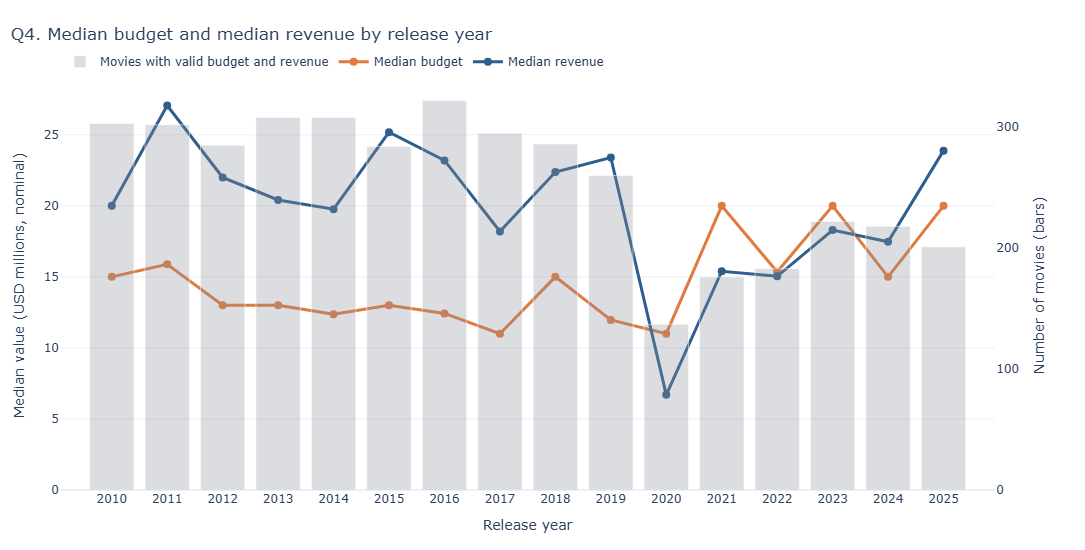

In [43]:
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Bar(x=q4_year.index, y=q4_year["movies"], name="Movies with valid budget and revenue",
                     marker_color="rgba(138,143,152,0.30)",
                     hovertemplate="%{x}: %{y:,} movies<extra></extra>"), secondary_y=True)
for col, name, color in [("median_budget", "Median budget", ACCENT2), ("median_revenue", "Median revenue", ACCENT)]:
    fig.add_trace(go.Scatter(x=q4_year.index, y=q4_year[col] / 1e6, mode="lines+markers", name=name,
                             line=dict(color=color, width=3), marker=dict(size=8),
                             customdata=q4_year["movies"],
                             hovertemplate="%{x}<br>" + name + ": $%{y:,.1f}M<br>Movies: %{customdata:,}<extra></extra>"),
                  secondary_y=False)
fig.update_yaxes(title_text="Median value (USD millions, nominal)", rangemode="tozero", secondary_y=False)
fig.update_yaxes(title_text="Number of movies (bars)", showgrid=False, rangemode="tozero", dtick=100, secondary_y=True)
fig.update_xaxes(title_text="Release year", dtick=1)
finish(fig, "Q4. Median budget and median revenue by release year", legend=dict(orientation="h", y=1.08, x=0))

In [44]:
if not q4_period.empty:
    hi_period = q4_period["median_revenue"].idxmax()
    lo_period = q4_period["median_revenue"].idxmin()
    show_interpretation(
        f"Among release periods with reported financial pairs, median revenue is highest in **{hi_period}** "
        f"({fmt_money(q4_period.loc[hi_period, 'median_revenue'])}) and lowest in **{lo_period}** "
        f"({fmt_money(q4_period.loc[lo_period, 'median_revenue'])}). The yearly chart shows the detailed trend and record counts. "
        f"Only movies with both budget and revenue reported are included, so changing reporting coverage may influence the pattern."
    )
else:
    show_interpretation("There are insufficient complete financial pairs across release periods.")


**Interpretation.** Among release periods with reported financial pairs, median revenue is highest in **2010–2013** ($21.8M) and lowest in **2018–2021** ($17.7M). The yearly chart shows the detailed trend and record counts. Only movies with both budget and revenue reported are included, so changing reporting coverage may influence the pattern.

### Question 5: Which movies have unusually high or low revenue compared with movies of similar budgets and genres?

**Method.** A "peer group" is all movies in `fin2` that share one genre and one budget range (Q1 ranges). Only peer groups with at least 20 movies are used.

1. For each movie and each of its genres, compute how far its `log10(revenue)` is from the median `log10(revenue)` of that peer group.
2. A multi-genre movie gets the **average** of these distances across its genres, so every genre is treated equally (not just the first one).
3. `performance_ratio = 10 ** distance`, so 3.0 means "earned about 3 times what a typical peer earned".
4. A movie is flagged as unusually high or low when its distance lies outside the 1.5 x IQR fences of all distances, the same IQR rule used in section 12.

**Limitations.** This is a screening method, not proof of anything unusual. Peer groups ignore release year, country, marketing and franchise status, and the budget ranges are wide. Flagged movies are **not removed and not treated as errors**; blockbusters and flops are real outcomes.

In [45]:
MIN_PEER_N = 20
peer = genre_long.dropna(subset=["budget_eda", "revenue_eda"]).copy()
peer["log_rev"] = np.log10(peer["revenue_eda"])
g = peer.groupby(["genre", "budget_range"], observed=True)["log_rev"]
peer["peer_n"] = g.transform("size")
peer["peer_median_log"] = g.transform("median")
peer = peer[peer["peer_n"] >= MIN_PEER_N]
peer["distance"] = peer["log_rev"] - peer["peer_median_log"]

q5 = (peer.groupby("movie_id")
      .agg(title=("title", "first"), release_year=("release_year", "first"),
           budget=("budget_eda", "first"), revenue=("revenue_eda", "first"),
           budget_range=("budget_range", "first"), genres_used=("genre", ", ".join),
           distance=("distance", "mean"), peer_median_log=("peer_median_log", "mean")))
q5["performance_ratio"] = 10 ** q5["distance"]
q5["typical_peer_revenue"] = 10 ** q5["peer_median_log"]

d_q1, d_q3 = q5["distance"].quantile([0.25, 0.75])
d_iqr = d_q3 - d_q1
low_fence, high_fence = d_q1 - 1.5 * d_iqr, d_q3 + 1.5 * d_iqr
q5["status"] = np.select([q5["distance"] > high_fence, q5["distance"] < low_fence],
                         ["Unusually high", "Unusually low"], "Within typical range")

print(f"Movies assessed: {len(q5):,} of {len(fin2):,} "
      f"({len(fin2) - len(q5):,} had no genre-budget peer group with >= {MIN_PEER_N} movies)")
print(f"Fences on log10 distance: {low_fence:.2f} to {high_fence:.2f} "
      f"(ratio {10 ** low_fence:.3f}x to {10 ** high_fence:.1f}x of the typical peer)")
display(q5["status"].value_counts().to_frame("movies"))

show_cols = ["title", "release_year", "budget", "revenue", "typical_peer_revenue", "performance_ratio", "genres_used"]
fmt5 = {"budget": fmt_money, "revenue": fmt_money, "typical_peer_revenue": fmt_money, "performance_ratio": "{:.3g}x",
        "release_year": "{:.0f}"}
print("Top 10 above peer expectation:")
display(q5.nlargest(10, "distance")[show_cols].style.format(fmt5).hide(axis="index"))
print("Top 10 below peer expectation:")
display(q5.nsmallest(10, "distance")[show_cols].style.format(fmt5).hide(axis="index"))

Movies assessed: 4,080 of 4,090 (10 had no genre-budget peer group with >= 20 movies)
Fences on log10 distance: -1.82 to 1.70 (ratio 0.015x to 50.2x of the typical peer)


,movies
status,
Within typical range,3866
Unusually low,202
Unusually high,12


Top 10 above peer expectation:


title,release_year,budget,revenue,typical_peer_revenue,performance_ratio,genres_used
Secret Superstar,2017,$286K,$137.4M,$621K,221x,Drama
Mr. Six,2015,$250K,$139.2M,$974K,143x,"Crime, Action, Drama"
Searching,2018,$880K,$75.6M,$590K,128x,"Drama, Thriller"
The Gallows,2015,$100K,$43.0M,$410K,105x,Horror
Animal World,2018,$125K,$69.9M,$802K,87.1x,"Drama, Action, Thriller"
Lost in the Stars,2023,$9.5M,$334.0M,$4.2M,78.9x,"Mystery, Crime, Thriller"
Life After Fighting,2024,$234K,$59.5M,$802K,74.2x,"Action, Drama, Thriller"
Your Name.,2016,$7.5M,$405.3M,$5.9M,68.4x,"Animation, Romance, Drama"
Split,2017,$9.0M,$278.5M,$4.1M,67.9x,"Horror, Thriller"
Annabelle,2014,$6.5M,$257.6M,$4.2M,61.9x,Horror


Top 10 below peer expectation:


title,release_year,budget,revenue,typical_peer_revenue,performance_ratio,genres_used
Society of the Snow,2023,$65.5M,$1K,$101.6M,1.26e-05x,"Drama, History"
Damsel,2024,$60.0M,$5K,$151.7M,3.3e-05x,"Fantasy, Action, Adventure"
Java Heat,2013,$15.0M,$1K,$26.5M,4e-05x,"Action, Crime, Drama, Thriller"
Sidewalls,2011,$11.0M,$2K,$27.3M,7.84e-05x,"Drama, Romance"
The Samaritan,2012,$12.0M,$3K,$23.4M,0.000108x,Thriller
The Fanatic,2019,$18.0M,$3K,$26.6M,0.000119x,"Crime, Thriller"
The Spy Gone North,2018,$17.0M,$3K,$23.2M,0.000137x,"Drama, History, Thriller"
The Gardener,2025,$10.0M,$5K,$33.4M,0.000143x,"Action, Comedy"
Kickboxer: Retaliation,2018,$13.0M,$5K,$26.5M,0.000171x,"Action, Drama"
The Guillotines,2012,$15.0M,$5K,$26.4M,0.0002x,"Action, History, Adventure, Drama"


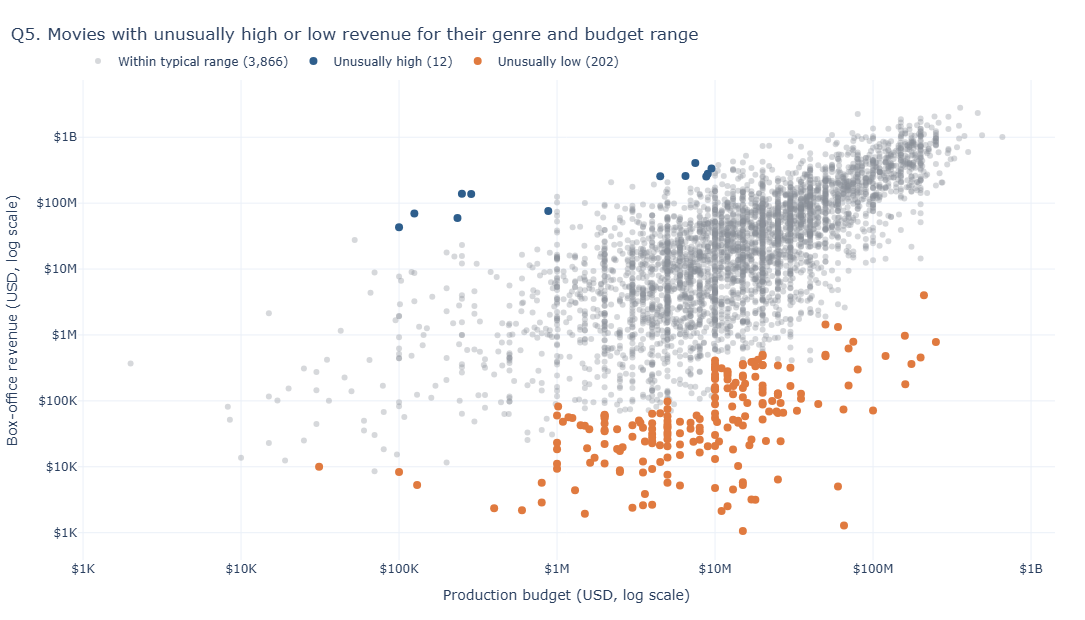

In [46]:
colors5 = {"Within typical range": "rgba(138,143,152,0.35)", "Unusually high": ACCENT, "Unusually low": ACCENT2}
fig = go.Figure()
for status in ["Within typical range", "Unusually high", "Unusually low"]:
    d = q5[q5["status"] == status]
    fig.add_trace(go.Scatter(
        x=d["budget"], y=d["revenue"], mode="markers", name=f"{status} ({len(d):,})",
        marker=dict(color=colors5[status], size=6 if status == "Within typical range" else 8),
        customdata=np.stack([d["release_year"], d["performance_ratio"], d["typical_peer_revenue"], d["genres_used"]], axis=1),
        text=d["title"],
        hovertemplate="<b>%{text}</b> (%{customdata[0]:.0f})<br>Budget: %{x:$,.0f}<br>Revenue: %{y:$,.0f}<br>"
                      "Typical peer revenue: %{customdata[2]:$,.0f}<br>Ratio to peers: %{customdata[1]:.3g}x<br>"
                      "Genres: %{customdata[3]}<extra></extra>"))
money_axis(fig, "x", "Production budget (USD, log scale)")
money_axis(fig, "y", "Box-office revenue (USD, log scale)")
finish(fig, "Q5. Movies with unusually high or low revenue for their genre and budget range", height=620,
       legend=dict(orientation="h", y=1.07, x=0))

In [47]:
status_counts = q5["status"].value_counts()
high_case = q5.loc[q5["distance"].idxmax()] if len(q5) else None
low_case = q5.loc[q5["distance"].idxmin()] if len(q5) else None
if len(q5):
    show_interpretation(
        f"The peer-group method classified {int(status_counts.get('Unusually high', 0)):,} movies as unusually high, "
        f"{int(status_counts.get('Unusually low', 0)):,} as unusually low and "
        f"{int(status_counts.get('Within typical range', 0)):,} within the typical range. "
        f"The highest relative performer in the assessed set is **{high_case['title']}** "
        f"({high_case['performance_ratio']:.2f}× the estimated peer median); the lowest is **{low_case['title']}** "
        f"({low_case['performance_ratio']:.2f}×). This is a screening rule, not proof of a data error or a causal explanation."
    )
else:
    show_interpretation("No movies had a sufficiently large budget-and-genre peer group for this analysis.")


**Interpretation.** The peer-group method classified 12 movies as unusually high, 202 as unusually low and 3,866 within the typical range. The highest relative performer in the assessed set is **Secret Superstar** (221.19× the estimated peer median); the lowest is **Society of the Snow** (0.00×). This is a screening rule, not proof of a data error or a causal explanation.

**Category B: Ratings and audience behaviour** (Questions 6–10)

### Question 6: How do audience ratings compare across movie genres?

Compare the observed rating distributions and median ratings across genres. Movies with multiple genres appear in each applicable genre, so genre groups overlap.


In [48]:
q6_tbl = genre_long.groupby("genre")["vote_average"].apply(box_stats).unstack()
q6_tbl["std"] = genre_long.groupby("genre")["vote_average"].std()
q6_tbl["pct_rated_7_plus"] = genre_long.groupby("genre")["vote_average"].apply(lambda s: (s >= 7).mean() * 100)
q6_tbl = q6_tbl.sort_values("median", ascending=False)
display(q6_tbl[["n", "median", "mean", "q1", "q3", "std", "pct_rated_7_plus"]].round(2)
        .style.format({"n": "{:,.0f}", "pct_rated_7_plus": "{:.1f}%"}, precision=2))
print(f"Movies used: {genre_long['movie_id'].nunique():,} | overall median rating: {ana['vote_average'].median():.2f}")

,n,median,mean,q1,q3,std,pct_rated_7_plus
genre,,,,,,,
Documentary,"1,103",7.10,7.08,6.70,7.46,0.65,58.9%
Music,591,7.00,6.94,6.46,7.49,0.83,51.3%
Animation,"1,478",7.00,6.98,6.56,7.46,0.72,52.2%
History,884,6.81,6.78,6.38,7.22,0.68,39.7%
War,467,6.70,6.65,6.20,7.20,0.78,36.6%
Family,"1,511",6.70,6.66,6.20,7.20,0.78,34.6%
Fantasy,"1,467",6.59,6.53,5.98,7.18,0.89,32.5%
Adventure,"1,763",6.57,6.49,6.00,7.11,0.92,30.7%
Drama,"7,767",6.54,6.51,6.00,7.03,0.76,27.3%


Movies used: 17,968 | overall median rating: 6.38


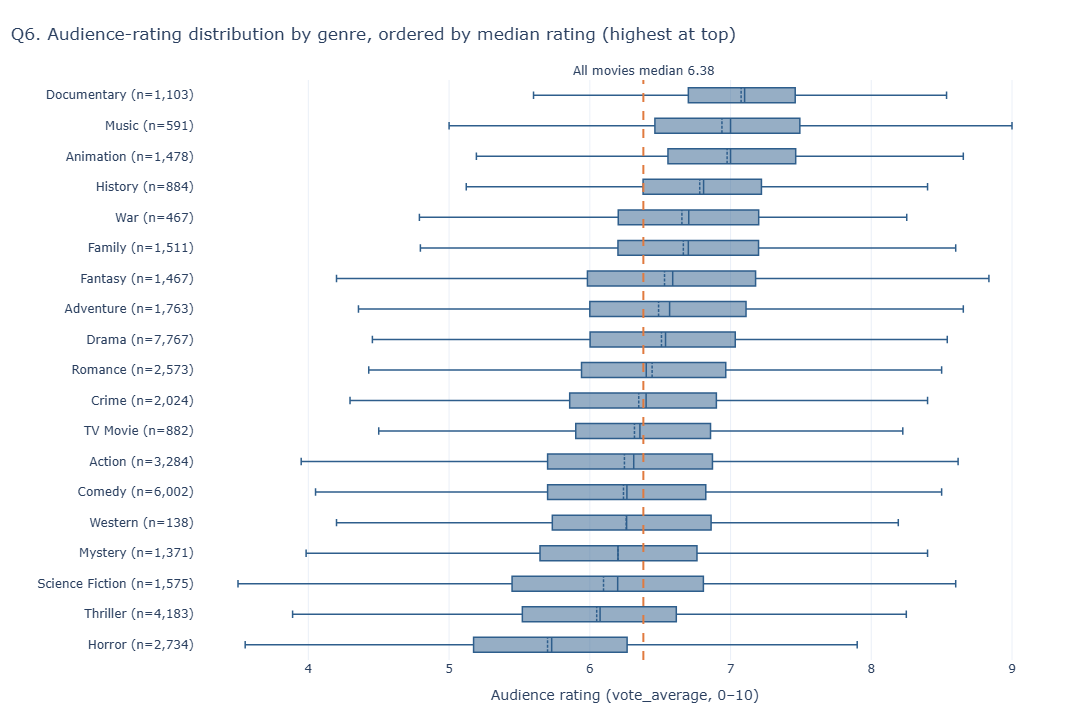

In [49]:
q6_labels = [f"{g} (n={int(n):,})" for g, n in zip(q6_tbl.index, q6_tbl["n"])]
fig = go.Figure()
add_box(fig, q6_tbl, q6_labels, color=ACCENT, horizontal=True)
overall_med = ana["vote_average"].median()
fig.add_vline(x=overall_med, line_dash="dash", line_color=ACCENT2,
              annotation_text=f"All movies median {overall_med:.2f}", annotation_position="top")
fig.update_xaxes(title_text="Audience rating (vote_average, 0–10)", hoverformat=".2f")
fig.update_yaxes(title_text="", categoryorder="array", categoryarray=q6_labels[::-1])
finish(fig, "Q6. Audience-rating distribution by genre, ordered by median rating (highest at top)", height=720)

In [50]:
if not q6_tbl.empty:
    hi = q6_tbl["median"].idxmax()
    lo = q6_tbl["median"].idxmin()
    show_interpretation(
        f"**{hi}** has the highest median observed rating ({q6_tbl.loc[hi, 'median']:.2f}), while **{lo}** has the lowest "
        f"({q6_tbl.loc[lo, 'median']:.2f}). The box plots show variation within each genre as well as differences between medians. "
        f"Because multi-genre movies appear in multiple genres, genre samples overlap."
    )
else:
    show_interpretation("No genre rating groups are available.")


**Interpretation.** **Documentary** has the highest median observed rating (7.10), while **Horror** has the lowest (5.73). The box plots show variation within each genre as well as differences between medians. Because multi-genre movies appear in multiple genres, genre samples overlap.

### Question 7: Do movies with higher popularity scores also tend to have higher audience ratings?

Popularity is very right-skewed, so it is shown on a log10 scale. With about 18,000 movies a plain scatter turns into one dark blob, so a 2-D density heatmap is used: each cell shows how many movies fall at that popularity and rating. The orange line is the median rating within each popularity decile. Spearman's rank correlation is used to describe the direction, as in section 16.7. This describes association only.

In [51]:
q7 = ana[["title", "popularity", "vote_average", "vote_count"]].dropna()
q7 = q7[q7["popularity"] > 0].copy()
q7["log_pop"] = np.log10(q7["popularity"])
q7["pop_decile"] = pd.qcut(q7["popularity"].rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])

q7_dec = (q7.groupby("pop_decile", observed=True)
          .agg(movies=("title", "size"), pop_min=("popularity", "min"), pop_max=("popularity", "max"),
               median_pop=("popularity", "median"), median_rating=("vote_average", "median"),
               pct_rated_7_plus=("vote_average", lambda s: (s >= 7).mean() * 100)))
display(q7_dec.round(2))

rho_q7 = q7[["popularity", "vote_average"]].corr(method="spearman").iloc[0, 1]
r_log_q7 = q7[["log_pop", "vote_average"]].corr().iloc[0, 1]
print(f"Valid records: {len(q7):,}")
print(f"Spearman rho (popularity, rating) = {rho_q7:.3f} | Pearson r (log10 popularity, rating) = {r_log_q7:.3f}")

,movies,pop_min,pop_max,median_pop,median_rating,pct_rated_7_plus
pop_decile,,,,,,
D1,1798,0.01,0.53,0.41,6.20,20.08
D2,1798,0.53,0.70,0.62,6.22,18.91
D3,1798,0.70,0.88,0.79,6.22,17.85
D4,1797,0.88,1.07,0.97,6.24,20.26
D5,1798,1.07,1.28,1.17,6.23,19.02
D6,1798,1.28,1.54,1.41,6.30,21.19
D7,1797,1.54,1.91,1.71,6.31,21.31
D8,1798,1.91,2.50,2.16,6.48,26.86
D9,1798,2.50,4.02,3.05,6.52,26.81


Valid records: 17,978
Spearman rho (popularity, rating) = 0.196 | Pearson r (log10 popularity, rating) = 0.218


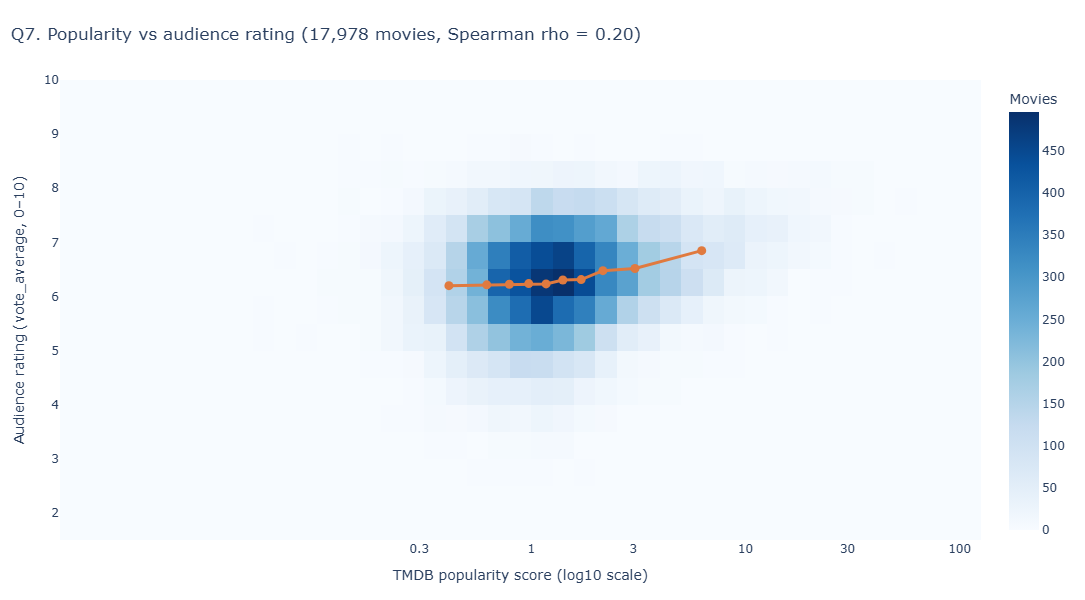

In [52]:
pop_ticks = [0.3, 1, 3, 10, 30, 100]
fig = go.Figure()
fig.add_trace(go.Histogram2d(
    x=q7["log_pop"], y=q7["vote_average"], nbinsx=45, nbinsy=40, colorscale="Blues",
    colorbar=dict(title="Movies"), name="Movies",
    hovertemplate="log10(popularity): %{x}<br>Rating: %{y}<br>Movies: %{z}<extra></extra>"))
fig.add_trace(go.Scatter(
    x=np.log10(q7_dec["median_pop"]), y=q7_dec["median_rating"], mode="lines+markers",
    name="Median rating per popularity decile", line=dict(color=ACCENT2, width=3), marker=dict(size=9),
    customdata=np.stack([q7_dec.index.astype(str), q7_dec["median_pop"], q7_dec["movies"]], axis=1),
    hovertemplate="Decile %{customdata[0]}<br>Median popularity: %{customdata[1]:.2f}<br>"
                  "Median rating: %{y:.2f}<br>Movies: %{customdata[2]:,}<extra></extra>"))
fig.update_xaxes(title_text="TMDB popularity score (log10 scale)", tickvals=np.log10(pop_ticks),
                 ticktext=[str(t) for t in pop_ticks])
fig.update_yaxes(title_text="Audience rating (vote_average, 0–10)")
finish(fig, f"Q7. Popularity vs audience rating ({len(q7):,} movies, Spearman rho = {rho_q7:.2f})", height=600,
       legend=dict(orientation="h", y=1.07, x=0))

In [53]:
rho_value = float(rho_q7) if pd.notna(rho_q7) else np.nan
if pd.notna(rho_value):
    strength = "very weak" if abs(rho_value) < 0.10 else "weak" if abs(rho_value) < 0.30 else "moderate" if abs(rho_value) < 0.50 else "strong"
    direction = "positive" if rho_value > 0 else "negative" if rho_value < 0 else "no monotonic"
    bottom = q7_dec.iloc[0]["median_rating"] if len(q7_dec) else np.nan
    top = q7_dec.iloc[-1]["median_rating"] if len(q7_dec) else np.nan
    show_interpretation(
        f"Spearman's rank correlation is **{rho_value:.2f}**, indicating a {strength} {direction} association between popularity and rating. "
        f"The lowest popularity decile has median rating {bottom:.2f} and the highest has {top:.2f}. "
        f"Popularity and rating may move together, but this descriptive result does not show that one causes the other."
    )
else:
    show_interpretation("There are insufficient observed popularity and rating values to calculate the association.")


**Interpretation.** Spearman's rank correlation is **0.20**, indicating a weak positive association between popularity and rating. The lowest popularity decile has median rating 6.20 and the highest has 6.85. Popularity and rating may move together, but this descriptive result does not show that one causes the other.

### Question 8: How do ratings differ between movies with low, medium and high vote counts?

Vote-count groups are Low (50–99), Medium (100–999) and High (1,000+). Movies with fewer than 50 votes are not part of this comparison. Ratings and vote counts are taken from observed source values, not imputed values.


In [54]:
q8_tbl = ana.groupby("vote_group", observed=True)["vote_average"].apply(box_stats).unstack()
grp8 = ana.groupby("vote_group", observed=True)["vote_average"]
q8_tbl["std"] = grp8.std()
q8_tbl["iqr"] = q8_tbl["q3"] - q8_tbl["q1"]
q8_tbl["pct_below_5"] = grp8.apply(lambda s: (s < 5).mean() * 100)
q8_tbl["pct_8_plus"] = grp8.apply(lambda s: (s >= 8).mean() * 100)
q8_tbl["min"] = grp8.min()
q8_tbl["max"] = grp8.max()
display(q8_tbl[["n", "median", "mean", "std", "iqr", "min", "max", "pct_below_5", "pct_8_plus"]]
        .style.format({"n": "{:,.0f}", "pct_below_5": "{:.1f}%", "pct_8_plus": "{:.1f}%"}, precision=2))

,n,median,mean,std,iqr,min,max,pct_below_5,pct_8_plus
vote_group,,,,,,,,,
Low (50–99 votes),"6,243",6.20,6.15,0.94,1.25,2.28,9.00,10.8%,1.5%
Medium (100–999 votes),"9,240",6.37,6.34,0.84,1.13,1.83,9.90,5.5%,1.7%
"High (1,000+ votes)","2,495",6.73,6.73,0.71,0.98,3.71,8.50,1.1%,3.5%


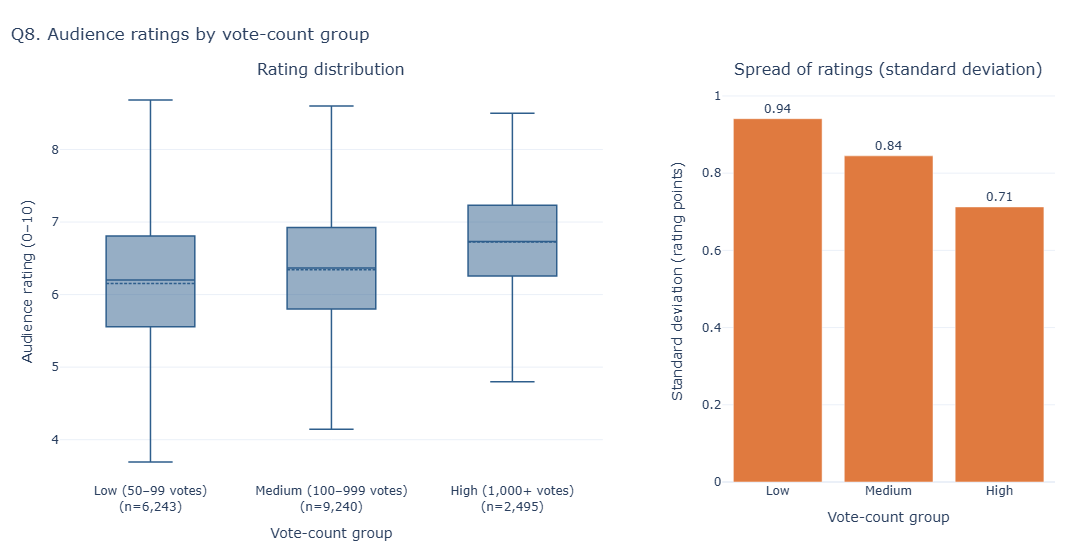

In [55]:
q8_labels = [f"{g}<br>(n={int(n):,})" for g, n in zip(q8_tbl.index, q8_tbl["n"])]
fig = make_subplots(rows=1, cols=2, column_widths=[0.62, 0.38], horizontal_spacing=0.12,
                    subplot_titles=("Rating distribution", "Spread of ratings (standard deviation)"))
add_box(fig, q8_tbl, q8_labels, color=ACCENT, row=1, col=1)
fig.add_trace(go.Bar(x=["Low", "Medium", "High"], y=q8_tbl["std"], marker_color=ACCENT2, showlegend=False,
                     text=[f"{v:.2f}" for v in q8_tbl["std"]], textposition="outside",
                     hovertemplate="%{x}<br>Std. deviation: %{y:.3f}<extra></extra>"), row=1, col=2)
fig.update_yaxes(title_text="Audience rating (0–10)", hoverformat=".2f", row=1, col=1)
fig.update_yaxes(title_text="Standard deviation (rating points)", rangemode="tozero", row=1, col=2)
fig.update_xaxes(title_text="Vote-count group", row=1, col=1)
fig.update_xaxes(title_text="Vote-count group", row=1, col=2)
finish(fig, "Q8. Audience ratings by vote-count group")

In [56]:
if not q8_tbl.empty:
    low_name, high_name = VOTE_GROUPS[0], VOTE_GROUPS[2]
    low_med = q8_tbl.loc[low_name, "median"] if low_name in q8_tbl.index else np.nan
    high_med = q8_tbl.loc[high_name, "median"] if high_name in q8_tbl.index else np.nan
    show_interpretation(
        f"The median rating is {low_med:.2f} in the low-vote group and {high_med:.2f} in the high-vote group "
        f"(where available). The chart also compares spread. Only movies with at least 50 observed votes are included; "
        f"vote count is not randomly assigned, so any pattern is an association rather than a causal effect."
    )
else:
    show_interpretation("No movies fall into the defined vote-count groups.")


**Interpretation.** The median rating is 6.20 in the low-vote group and 6.73 in the high-vote group (where available). The chart also compares spread. Only movies with at least 50 observed votes are included; vote count is not randomly assigned, so any pattern is an association rather than a causal effect.

### Question 9: How do revenue and ratings compare between single-genre and multi-genre movies?

Movies are grouped by how many genres they carry: Single genre, Two genres, Three or more genres. Ratings use every movie with a real genre list; revenue uses the movies in those groups that also have a valid revenue. Each movie is counted once here, so the groups do not overlap.

In [57]:
q9_rating = ana.groupby("genre_count_group", observed=True)["vote_average"].apply(box_stats).unstack()
q9_revenue = (ana.dropna(subset=["revenue_eda"]).groupby("genre_count_group", observed=True)["revenue_eda"]
              .apply(money_box).unstack())
q9_summary = pd.DataFrame({
    "movies": q9_rating["n"], "median_rating": q9_rating["median"], "mean_rating": q9_rating["mean"],
    "movies_with_revenue": q9_revenue["n"], "median_revenue": q9_revenue["median"], "mean_revenue": q9_revenue["mean"],
})
binary9 = ana.dropna(subset=["n_genres"]).assign(
    genre_type=lambda d: np.where(d["n_genres"] == 1, "Single genre", "Multi-genre (2+)"))
q9_binary = binary9.groupby("genre_type").agg(
    movies=("title", "size"), median_rating=("vote_average", "median"), mean_rating=("vote_average", "mean"),
    movies_with_revenue=("revenue_eda", "count"), median_revenue=("revenue_eda", "median"))

fmt9 = {"movies": "{:,.0f}", "movies_with_revenue": "{:,.0f}", "median_revenue": fmt_money, "mean_revenue": fmt_money,
        "median_rating": "{:.2f}", "mean_rating": "{:.2f}"}
display(q9_summary.style.format(fmt9))
display(q9_binary.style.format(fmt9))

,movies,median_rating,mean_rating,movies_with_revenue,median_revenue,mean_revenue
genre_count_group,,,,,,
Single genre,"4,362",6.33,6.27,"1,254",$2.8M,$19.7M
Two genres,"6,194",6.33,6.30,"2,263",$4.7M,$36.0M
Three or more genres,"7,412",6.41,6.39,"3,260",$12.4M,$97.5M


,movies,median_rating,mean_rating,movies_with_revenue,median_revenue
genre_type,,,,,
Multi-genre (2+),"13,606",6.39,6.35,"5,523",$8.1M
Single genre,"4,362",6.33,6.27,"1,254",$2.8M


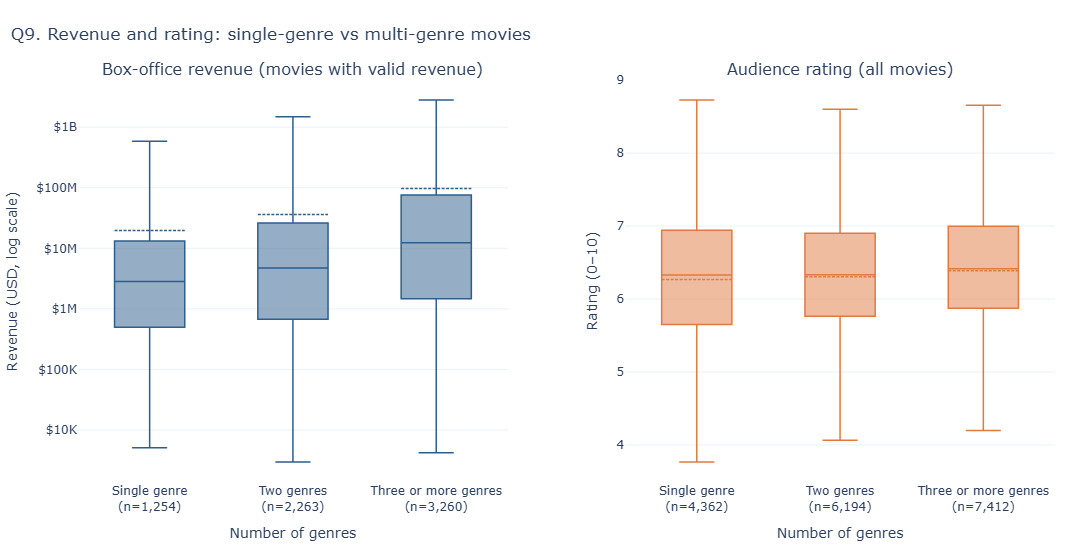

In [58]:
q9_labels = list(q9_rating.index.astype(str))
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.12,
                    subplot_titles=("Box-office revenue (movies with valid revenue)", "Audience rating (all movies)"))
add_box(fig, q9_revenue, [f"{l}<br>(n={int(n):,})" for l, n in zip(q9_labels, q9_revenue["n"])],
        color=ACCENT, row=1, col=1)
add_box(fig, q9_rating, [f"{l}<br>(n={int(n):,})" for l, n in zip(q9_labels, q9_rating["n"])],
        color=ACCENT2, row=1, col=2)
fig.update_yaxes(type="log", tickvals=MONEY_TICKS, ticktext=MONEY_TEXT, hoverformat="$,.0f",
                 title_text="Revenue (USD, log scale)", row=1, col=1)
fig.update_yaxes(title_text="Rating (0–10)", hoverformat=".2f", row=1, col=2)
fig.update_xaxes(title_text="Number of genres", row=1, col=1)
fig.update_xaxes(title_text="Number of genres", row=1, col=2)
finish(fig, "Q9. Revenue and rating: single-genre vs multi-genre movies")

In [59]:
if not q9_summary.empty:
    rev_group = q9_summary["median_revenue"].dropna()
    rating_group = q9_summary["median_rating"].dropna()
    rev_hi = rev_group.idxmax() if len(rev_group) else None
    rating_hi = rating_group.idxmax() if len(rating_group) else None
    parts = []
    if rev_hi is not None:
        parts.append(f"highest median revenue occurs for **{rev_hi}** ({fmt_money(rev_group.loc[rev_hi])})")
    if rating_hi is not None:
        parts.append(f"highest median rating occurs for **{rating_hi}** ({rating_group.loc[rating_hi]:.2f})")
    show_interpretation(
        "; ".join(parts) + ". Revenue and rating need not rank the genre-count groups in the same order. "
        "Genre-count groups are descriptive; genre count alone does not explain financial or audience outcomes."
    )
else:
    show_interpretation("There are insufficient records with valid genre counts for this comparison.")


**Interpretation.** highest median revenue occurs for **Three or more genres** ($12.4M); highest median rating occurs for **Three or more genres** (6.41). Revenue and rating need not rank the genre-count groups in the same order. Genre-count groups are descriptive; genre count alone does not explain financial or audience outcomes.

### Question 10: How do audience ratings and revenue differ across runtime groups?

Runtime groups are Under 40 minutes, 40–89 minutes, 90–119 minutes and 120+ minutes. Movies with missing or non-positive runtime are excluded from runtime comparisons. Revenue summaries use only movies with valid reported revenue.


In [60]:
q10_rating = ana.groupby("runtime_group", observed=True)["vote_average"].apply(box_stats).unstack()
q10_revenue = (ana.dropna(subset=["revenue_eda"]).groupby("runtime_group", observed=True)["revenue_eda"]
               .apply(money_box).unstack())
q10_summary = pd.DataFrame({
    "movies": q10_rating["n"], "median_rating": q10_rating["median"], "mean_rating": q10_rating["mean"],
    "movies_with_revenue": q10_revenue["n"], "median_revenue": q10_revenue["median"],
    "pct_with_reported_revenue": q10_revenue["n"] / q10_rating["n"] * 100,
})
display(q10_summary.style.format({"movies": "{:,.0f}", "movies_with_revenue": "{:,.0f}", "median_rating": "{:.2f}",
                                  "mean_rating": "{:.2f}", "median_revenue": fmt_money,
                                  "pct_with_reported_revenue": "{:.1f}%"}))
print(f"Runtime 0 (invalid, excluded): {int((ana['runtime'] == 0).sum())} movies")

,movies,median_rating,mean_rating,movies_with_revenue,median_revenue,pct_with_reported_revenue
runtime_group,,,,,,
Under 40 min (short film),481,6.94,6.90,6,$615K,1.2%
Short feature (40–89 min),"3,954",6.11,6.09,844,$1.7M,21.3%
Medium (90–119 min),"10,852",6.30,6.28,"4,379",$4.9M,40.4%
Long (120+ min),"2,645",6.85,6.80,"1,544",$23.0M,58.4%


Runtime 0 (invalid, excluded): 46 movies


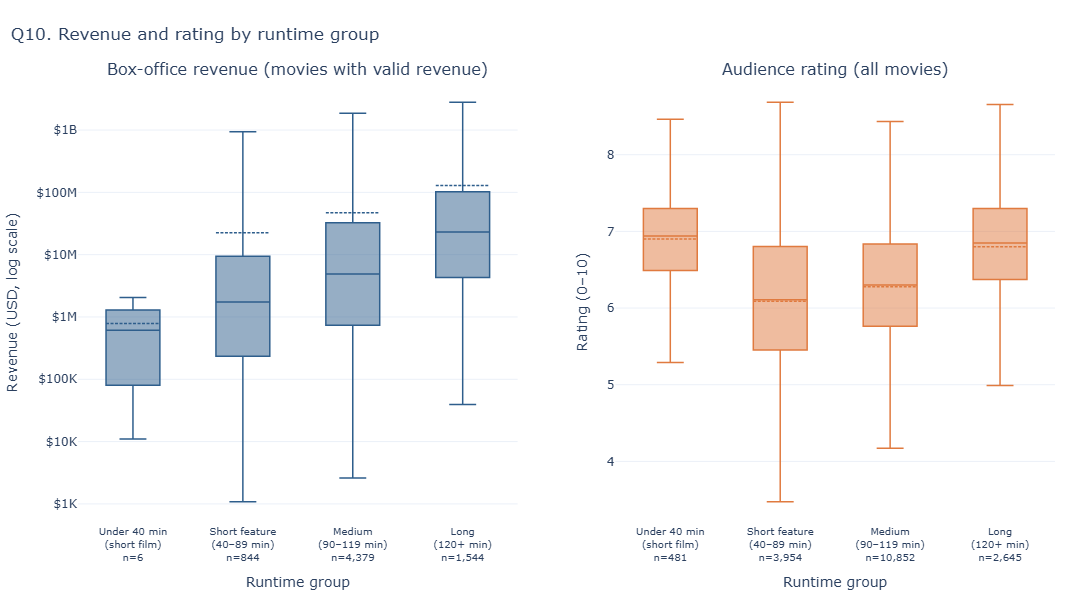

In [61]:
q10_labels = [l.replace(" (", "<br>(") for l in q10_rating.index.astype(str)]
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.10,
                    subplot_titles=("Box-office revenue (movies with valid revenue)", "Audience rating (all movies)"))
add_box(fig, q10_revenue, [f"{l}<br>n={int(n):,}" for l, n in zip(q10_labels, q10_revenue["n"])],
        color=ACCENT, row=1, col=1)
add_box(fig, q10_rating, [f"{l}<br>n={int(n):,}" for l, n in zip(q10_labels, q10_rating["n"])],
        color=ACCENT2, row=1, col=2)
fig.update_yaxes(type="log", tickvals=MONEY_TICKS, ticktext=MONEY_TEXT, hoverformat="$,.0f",
                 title_text="Revenue (USD, log scale)", row=1, col=1)
fig.update_yaxes(title_text="Rating (0–10)", hoverformat=".2f", row=1, col=2)
fig.update_xaxes(title_text="Runtime group", tickfont_size=10, row=1, col=1)
fig.update_xaxes(title_text="Runtime group", tickfont_size=10, row=1, col=2)
finish(fig, "Q10. Revenue and rating by runtime group", height=600)

In [62]:
rev = q10_summary["median_revenue"].dropna()
rat = q10_summary["median_rating"].dropna()
parts = []
if len(rev):
    g = rev.idxmax()
    parts.append(f"the highest median revenue is in **{g}** ({fmt_money(rev.loc[g])})")
if len(rat):
    g = rat.idxmax()
    parts.append(f"the highest median rating is in **{g}** ({rat.loc[g]:.2f})")
show_interpretation(
    "; ".join(parts) + ". Revenue is calculated only for movies with valid reported revenue, while ratings use observed ratings. "
    "Different revenue-reporting rates across runtime groups may affect the comparison."
)


**Interpretation.** the highest median revenue is in **Long (120+ min)** ($23.0M); the highest median rating is in **Under 40 min (short film)** (6.94). Revenue is calculated only for movies with valid reported revenue, while ratings use observed ratings. Different revenue-reporting rates across runtime groups may affect the comparison.

**Category C: Industry trends and comparisons** (Questions 11–15)

### Question 11: How has the number of movies released per year changed, and how does this compare with yearly median revenue?

Annual release counts include retained records with a valid release year. Yearly median revenue uses observed revenue values meeting the financial threshold, so record coverage is shown alongside the trend.


In [63]:
q11 = (ana.groupby("release_year")
       .agg(releases=("title", "size"), movies_with_revenue=("revenue_eda", "count"),
            median_revenue=("revenue_eda", "median")))
q11.index = q11.index.astype(int)
q11["pct_with_revenue"] = q11["movies_with_revenue"] / q11["releases"] * 100
q11["releases_change_pct"] = q11["releases"].pct_change() * 100
display(q11.style.format({"releases": "{:,}", "movies_with_revenue": "{:,}", "median_revenue": fmt_money,
                          "pct_with_revenue": "{:.1f}%", "releases_change_pct": "{:+.1f}%"}, na_rep="-"))
print(f"Smallest number of valid revenue records in any year: {q11['movies_with_revenue'].min()} "
      f"({q11['movies_with_revenue'].idxmin()})")

,releases,movies_with_revenue,median_revenue,pct_with_revenue,releases_change_pct
release_year,,,,,
2010,892,429,$9.5M,48.1%,-
2011,958,440,$9.8M,45.9%,+7.4%
2012,976,456,$7.9M,46.7%,+1.9%
2013,"1,108",460,$9.4M,41.5%,+13.5%
2014,"1,210",491,$5.2M,40.6%,+9.2%
2015,"1,258",461,$7.7M,36.6%,+4.0%
2016,"1,315",483,$9.1M,36.7%,+4.5%
2017,"1,398",503,$7.0M,36.0%,+6.3%
2018,"1,426",472,$7.0M,33.1%,+2.0%


Smallest number of valid revenue records in any year: 314 (2020)


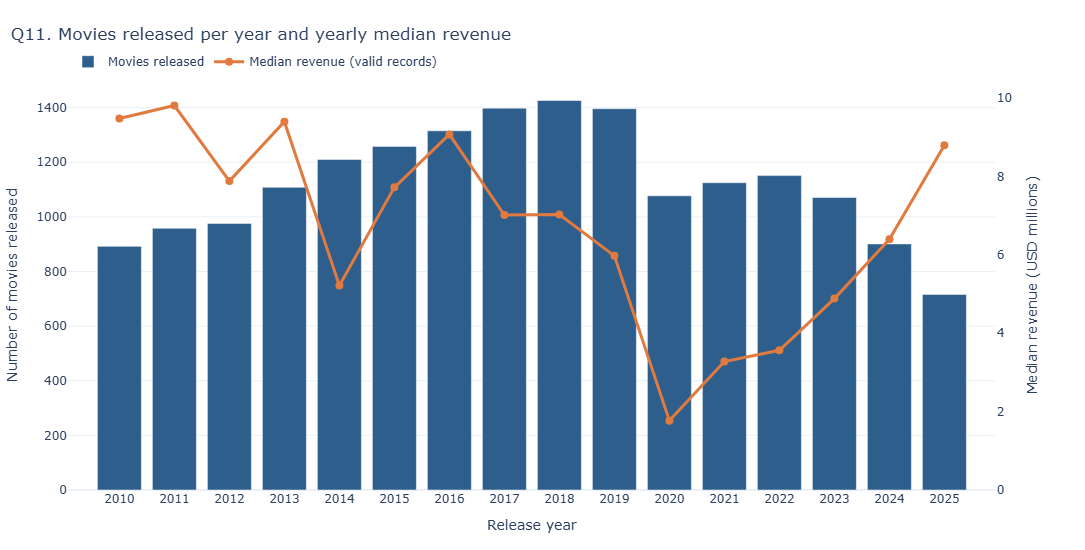

In [64]:
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Bar(x=q11.index, y=q11["releases"], name="Movies released", marker_color=ACCENT,
                     customdata=q11["releases_change_pct"],
                     hovertemplate="%{x}: %{y:,} releases<br>Change vs previous year: %{customdata:+.1f}%<extra></extra>"),
              secondary_y=False)
fig.add_trace(go.Scatter(x=q11.index, y=q11["median_revenue"] / 1e6, name="Median revenue (valid records)",
                         mode="lines+markers", line=dict(color=ACCENT2, width=3), marker=dict(size=8),
                         customdata=q11["movies_with_revenue"],
                         hovertemplate="%{x}<br>Median revenue: $%{y:,.1f}M<br>Based on %{customdata:,} movies<extra></extra>"),
              secondary_y=True)
fig.update_yaxes(title_text="Number of movies released", rangemode="tozero", secondary_y=False)
fig.update_yaxes(title_text="Median revenue (USD millions)", rangemode="tozero", showgrid=False, secondary_y=True)
fig.update_xaxes(title_text="Release year", dtick=1)
finish(fig, "Q11. Movies released per year and yearly median revenue", legend=dict(orientation="h", y=1.08, x=0))

In [65]:
release_peak_year = int(q11["releases"].idxmax()) if len(q11) else None
rev_peak_year = q11["median_revenue"].dropna().idxmax() if q11["median_revenue"].notna().any() else None
if release_peak_year is not None:
    release_text = f"the highest release count is {int(q11.loc[release_peak_year, 'releases']):,} movies in {release_peak_year}"
else:
    release_text = "no annual release-count peak could be calculated"
if rev_peak_year is not None:
    revenue_text = f"the highest yearly median reported revenue is {fmt_money(q11.loc[rev_peak_year, 'median_revenue'])} in {int(rev_peak_year)}"
else:
    revenue_text = "no yearly median revenue could be calculated"
show_interpretation(
    f"{release_text}, while {revenue_text}. The two trends need not move together. Recent-year counts and revenue summaries may be incomplete "
    "or affected by reporting coverage, so the pattern describes this dataset rather than all movies released worldwide."
)


**Interpretation.** the highest release count is 1,426 movies in 2018, while the highest yearly median reported revenue is $9.8M in 2011. The two trends need not move together. Recent-year counts and revenue summaries may be incomplete or affected by reporting coverage, so the pattern describes this dataset rather than all movies released worldwide.

### Question 12: How do median ratings and revenue compare across the most frequently represented original languages?

**Selection rule.** A language is included if it is the original language of at least 200 movies (about 1% of the dataset). Its median revenue is shown only if at least 30 of those movies have a valid revenue. Each movie has exactly one `original_language`, so there is no double counting.

In [66]:
MIN_LANG_MOVIES, MIN_LANG_REV = 200, 30
q12 = (ana.groupby("language_name")
       .agg(movies=("title", "size"), median_rating=("vote_average", "median"),
            movies_with_revenue=("revenue_eda", "count"), median_revenue=("revenue_eda", "median")))
q12 = q12[q12["movies"] >= MIN_LANG_MOVIES].sort_values("movies", ascending=False)
q12.loc[q12["movies_with_revenue"] < MIN_LANG_REV, "median_revenue"] = np.nan
q12["pct_with_revenue"] = q12["movies_with_revenue"] / q12["movies"] * 100
q12["share_of_dataset"] = q12["movies"] / len(ana) * 100
display(q12.style.format({"movies": "{:,}", "median_rating": "{:.2f}", "movies_with_revenue": "{:,}",
                          "median_revenue": fmt_money, "pct_with_revenue": "{:.1f}%", "share_of_dataset": "{:.1f}%"}))
print(f"{len(q12)} languages meet the threshold and cover {q12['movies'].sum() / len(ana) * 100:.1f}% of all movies")

,movies,median_rating,movies_with_revenue,median_revenue,pct_with_revenue,share_of_dataset
language_name,,,,,,
English,"10,615",6.27,"4,182",$8.7M,39.4%,59.0%
French,"1,719",6.13,524,$3.3M,30.5%,9.6%
Spanish,942,6.68,226,$2.1M,24.0%,5.2%
Italian,752,6.10,243,$2.1M,32.3%,4.2%
Japanese,654,7.09,317,$10.5M,48.5%,3.6%
Korean,413,7.03,176,$14.9M,42.6%,2.3%
Hindi,400,6.57,197,$15.4M,49.2%,2.2%
German,377,6.50,116,$4.1M,30.8%,2.1%
Chinese,335,6.75,169,$82.0M,50.4%,1.9%


11 languages meet the threshold and cover 92.7% of all movies


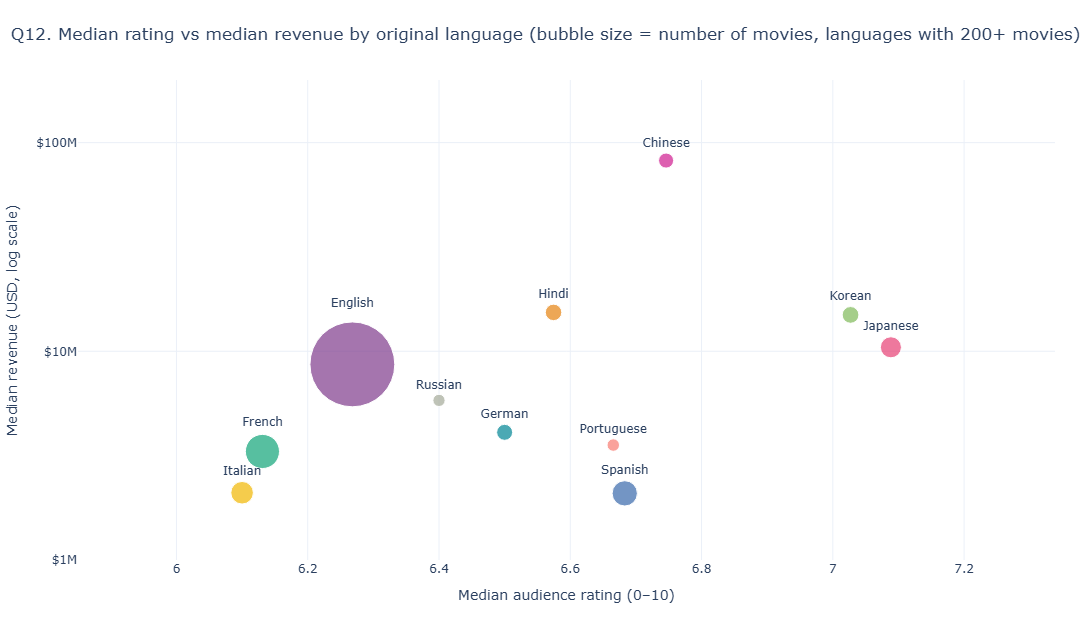

In [67]:
d12 = q12.dropna(subset=["median_revenue"]).reset_index()
fig = px.scatter(
    d12, x="median_rating", y="median_revenue", size="movies", text="language_name", size_max=60,
    color="language_name", color_discrete_sequence=px.colors.qualitative.Bold, log_y=True,
    custom_data=["movies", "movies_with_revenue", "pct_with_revenue"],
    labels={"median_rating": "Median audience rating (0–10)", "median_revenue": "Median revenue (USD, log scale)"})
fig.update_traces(textposition="top center",
                  hovertemplate="<b>%{text}</b><br>Median rating: %{x:.2f}<br>Median revenue: %{y:$,.0f}<br>"
                                "Movies: %{customdata[0]:,}<br>With valid revenue: %{customdata[1]:,} "
                                "(%{customdata[2]:.1f}%)<extra></extra>")
fig.update_yaxes(tickvals=MONEY_TICKS, ticktext=MONEY_TEXT, range=[6, 8.3])
fig.update_xaxes(range=[d12["median_rating"].min() - 0.25, d12["median_rating"].max() + 0.25])
finish(fig, f"Q12. Median rating vs median revenue by original language (bubble size = number of movies, "
            f"languages with {MIN_LANG_MOVIES}+ movies)", height=620, showlegend=False)

In [68]:
if not q12.empty:
    hi_r = q12["median_rating"].idxmax()
    lo_r = q12["median_rating"].idxmin()
    revs = q12["median_revenue"].dropna()
    rev_hi = revs.idxmax() if len(revs) else None
    rev_lo = revs.idxmin() if len(revs) else None
    txt = (f"Among languages meeting the {MIN_LANG_MOVIES}-movie threshold, **{hi_r}** has the highest median rating "
           f"({q12.loc[hi_r, 'median_rating']:.2f}) and **{lo_r}** the lowest ({q12.loc[lo_r, 'median_rating']:.2f}).")
    if rev_hi is not None:
        txt += f" **{rev_hi}** has the highest median reported revenue ({fmt_money(revs.loc[rev_hi])})"
    if rev_lo is not None:
        txt += f", while **{rev_lo}** has the lowest ({fmt_money(revs.loc[rev_lo])})"
    txt += ". Differences should be interpreted cautiously because languages have different movie counts and financial-reporting rates."
    show_interpretation(txt)
else:
    show_interpretation("No language meets the minimum movie-count threshold.")


**Interpretation.** Among languages meeting the 200-movie threshold, **Japanese** has the highest median rating (7.09) and **Italian** the lowest (6.10). **Chinese** has the highest median reported revenue ($82.0M), while **Spanish** has the lowest ($2.1M). Differences should be interpreted cautiously because languages have different movie counts and financial-reporting rates.

### Question 13: Which production countries have the highest movie counts, and how do their median ratings and revenues compare?

**Counting method.** A movie made by several countries (for example `France|Belgium`) counts once for **each** country, so country totals add up to more than the number of movies. Country values that were imputed by `SimpleImputer` are excluded. The 10 countries with the most movies are compared on count, median rating and median revenue (valid revenue only).

In [69]:
q13 = (country_long.groupby("country")
       .agg(movies=("movie_id", "nunique"), median_rating=("vote_average", "median"),
            movies_with_revenue=("revenue_eda", "count"), median_revenue=("revenue_eda", "median"))
       .sort_values("movies", ascending=False).head(10))
q13["pct_with_revenue"] = q13["movies_with_revenue"] / q13["movies"] * 100
solo = ana[ana["country_list"].apply(lambda c: isinstance(c, list) and len(c) == 1)]
q13["single_country_movies"] = solo["country_list"].str[0].value_counts().reindex(q13.index)
display(q13.style.format({"movies": "{:,}", "median_rating": "{:.2f}", "movies_with_revenue": "{:,}",
                          "median_revenue": fmt_money, "pct_with_revenue": "{:.1f}%", "single_country_movies": "{:,}"}))
multi_share = (ana["country_list"].dropna().apply(len) > 1).mean() * 100
print(f"Movies with a valid country list: {ana['country_list'].notna().sum():,} | co-productions (2+ countries): {multi_share:.1f}%")

,movies,median_rating,movies_with_revenue,median_revenue,pct_with_revenue,single_country_movies
country,,,,,,
United States of America,"8,820",6.30,"3,731",$12.6M,42.3%,"6,076"
France,"2,543",6.27,"1,013",$3.5M,39.8%,"1,056"
United Kingdom,"2,007",6.36,989,$4.6M,49.3%,658
Canada,"1,274",6.18,399,$3.0M,31.3%,408
Italy,963,6.13,354,$2.5M,36.8%,587
Germany,924,6.50,415,$3.4M,44.9%,256
Japan,748,7.02,375,$11.8M,50.1%,603
Belgium,730,6.30,312,$3.0M,42.7%,22
Spain,676,6.37,254,$3.2M,37.6%,310


Movies with a valid country list: 17,802 | co-productions (2+ countries): 28.4%


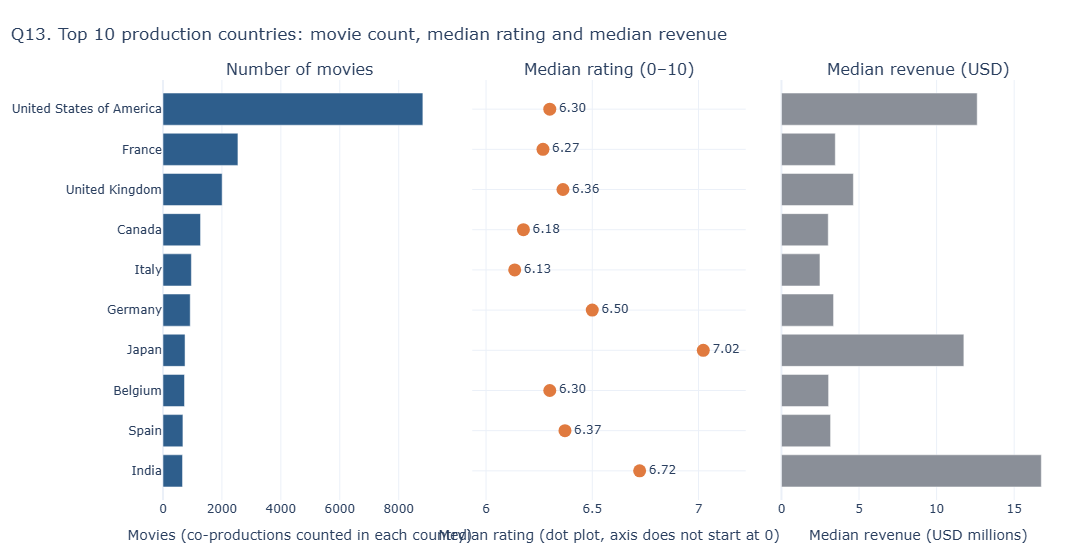

In [70]:
order13 = q13.index[::-1].tolist()
fig = make_subplots(rows=1, cols=3, shared_yaxes=True, horizontal_spacing=0.04,
                    subplot_titles=("Number of movies", "Median rating (0–10)", "Median revenue (USD)"))
fig.add_trace(go.Bar(y=order13, x=q13.loc[order13, "movies"], orientation="h", marker_color=ACCENT,
                     hovertemplate="%{y}: %{x:,} movies<extra></extra>"), row=1, col=1)
fig.add_trace(go.Scatter(y=order13, x=q13.loc[order13, "median_rating"], mode="markers+text", marker=dict(size=13, color=ACCENT2),
                         text=[f"{v:.2f}" for v in q13.loc[order13, "median_rating"]], textposition="middle right",
                         hovertemplate="%{y}: median rating %{x:.2f}<extra></extra>"), row=1, col=2)
fig.add_trace(go.Bar(y=order13, x=q13.loc[order13, "median_revenue"] / 1e6, orientation="h", marker_color=GREY,
                     customdata=q13.loc[order13, "movies_with_revenue"],
                     hovertemplate="%{y}: median revenue $%{x:,.1f}M<br>Based on %{customdata:,} movies<extra></extra>"),
              row=1, col=3)
fig.update_xaxes(title_text="Movies (co-productions counted in each country)", row=1, col=1)
fig.update_xaxes(title_text="Median rating (dot plot, axis does not start at 0)", range=[max(0, float(q13["median_rating"].min()) - 0.2), min(10, float(q13["median_rating"].max()) + 0.2)], row=1, col=2)
fig.update_xaxes(title_text="Median revenue (USD millions)", row=1, col=3)
finish(fig, "Q13. Top 10 production countries: movie count, median rating and median revenue",
       height=560, showlegend=False)

In [71]:
if not q13.empty:
    count_country = q13["movies"].idxmax()
    rating_country = q13["median_rating"].idxmax()
    revenue_values = q13["median_revenue"].dropna()
    revenue_country = revenue_values.idxmax() if len(revenue_values) else None
    txt = (f"**{count_country}** has the largest representation ({int(q13.loc[count_country, 'movies']):,} movie-country records), "
           f"while **{rating_country}** has the highest median rating ({q13.loc[rating_country, 'median_rating']:.2f}).")
    if revenue_country is not None:
        txt += f" **{revenue_country}** has the highest median reported revenue ({fmt_money(revenue_values.loc[revenue_country])})."
    txt += " Co-productions count in each associated country, so country totals overlap and comparisons are not independent."
    show_interpretation(txt)
else:
    show_interpretation("No production-country groups are available.")


**Interpretation.** **United States of America** has the largest representation (8,820 movie-country records), while **Japan** has the highest median rating (7.02). **India** has the highest median reported revenue ($16.8M). Co-productions count in each associated country, so country totals overlap and comparisons are not independent.

### Question 14: How do financial summaries change when movies with zero or potentially unreported budgets and revenues are excluded?

A budget or revenue of 0 may indicate that the figure was **not reported**, rather than that the movie cost or earned nothing. This cannot be confirmed for every record, so instead of silently removing zeros we compare four versions of the same summary:

| Version | Rule |
|---|---|
| A. All records | zeros kept as real zeros |
| B. Exclude zeros | value > 0 |
| C. Exclude zeros and placeholders | value >= $1,000 (the `MIN_VALID` rule from section 16.1) |
| D. Complete financial pairs | both budget and revenue >= $1,000 (`fin2`) |

Budget and revenue are summarised separately in A to C, and on the same movies in D.

In [72]:
def fin_summary(values, label, field):
    v = pd.Series(values, dtype="float64").dropna()
    return {"version": label, "field": field, "records": len(v), "mean": v.mean(), "median": v.median(),
            "q1": v.quantile(0.25), "q3": v.quantile(0.75), "pct_zero": (v == 0).mean() * 100,
            "total": v.sum()}

versions = {
    "A. All records": (ana["budget"], ana["revenue"]),
    "B. Exclude zeros": (ana["budget"].where(ana["budget"] > 0), ana["revenue"].where(ana["revenue"] > 0)),
    "C. Exclude zeros and < $1,000": (ana["budget_eda"], ana["revenue_eda"]),
    "D. Complete pairs (fin2)": (fin2["budget_eda"], fin2["revenue_eda"]),
}
q14 = pd.DataFrame([fin_summary(v, k, f) for k, (b, r) in versions.items()
                    for v, f in [(b, "Budget"), (r, "Revenue")]])
display(q14.style.format({"records": "{:,}", "mean": fmt_money, "median": fmt_money, "q1": fmt_money,
                          "q3": fmt_money, "pct_zero": "{:.1f}%", "total": fmt_money}).hide(axis="index"))

rr_all = ana["revenue"].sum() / ana["budget"].sum()
rr_pairs = fin2["revenue_eda"].sum() / fin2["budget_eda"].sum()
print(f"Total revenue / total budget: all records {rr_all:.2f}x | complete pairs only {rr_pairs:.2f}x")
print(f"Share of movies earning back budget (complete pairs): {fin2['earned_back'].mean() * 100:.1f}%")

version,field,records,mean,median,q1,q3,pct_zero,total
A. All records,Budget,"17,978",$8.4M,$0K,$0K,$2.3M,69.3%,$150.82B
A. All records,Revenue,"17,978",$23.6M,$0K,$0K,$1.9M,62.1%,$424.22B
B. Exclude zeros,Budget,"5,515",$27.3M,$10.0M,$3.5M,$29.0M,0.0%,$150.82B
B. Exclude zeros,Revenue,"6,822",$62.2M,$6.2M,$854K,$40.3M,0.0%,$424.22B
"C. Exclude zeros and < $1,000",Budget,"5,480",$27.5M,$10.0M,$3.5M,$29.8M,0.0%,$150.82B
"C. Exclude zeros and < $1,000",Revenue,"6,777",$62.6M,$6.4M,$911K,$40.7M,0.0%,$424.22B
D. Complete pairs (fin2),Budget,"4,090",$33.7M,$14.5M,$5.0M,$36.0M,0.0%,$137.78B
D. Complete pairs (fin2),Revenue,"4,090",$97.0M,$19.8M,$3.4M,$86.0M,0.0%,$396.78B


Total revenue / total budget: all records 2.81x | complete pairs only 2.88x
Share of movies earning back budget (complete pairs): 61.8%


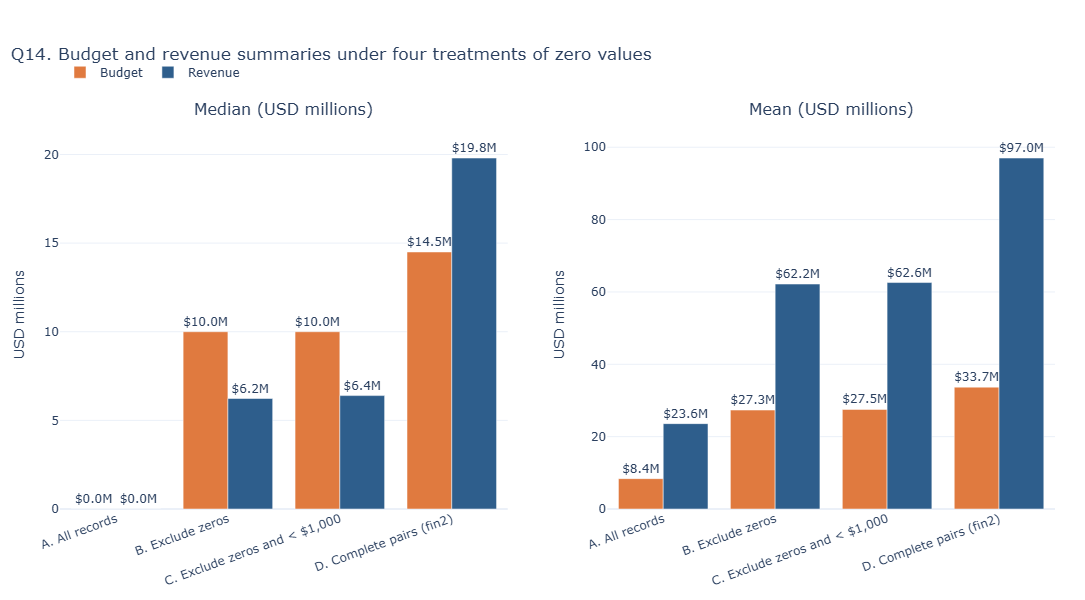

In [73]:
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.10,
                    subplot_titles=("Median (USD millions)", "Mean (USD millions)"))
for field, color in [("Budget", ACCENT2), ("Revenue", ACCENT)]:
    d = q14[q14["field"] == field]
    for col, stat in [(1, "median"), (2, "mean")]:
        fig.add_trace(go.Bar(
            x=d["version"], y=d[stat] / 1e6, name=field, marker_color=color, showlegend=(col == 1),
            legendgroup=field, customdata=np.stack([d["records"], d["pct_zero"]], axis=1),
            text=[f"${v / 1e6:,.1f}M" for v in d[stat]], textposition="outside",
            hovertemplate="%{x}<br>" + field + f" {stat}: $%{{y:,.2f}}M<br>Records: %{{customdata[0]:,}}<br>"
                          "Zeros: %{customdata[1]:.1f}%<extra></extra>"), row=1, col=col)
fig.update_yaxes(title_text="USD millions", rangemode="tozero", row=1, col=1)
fig.update_yaxes(title_text="USD millions", rangemode="tozero", row=1, col=2)
fig.update_xaxes(tickangle=-20, row=1, col=1)
fig.update_xaxes(tickangle=-20, row=1, col=2)
finish(fig, "Q14. Budget and revenue summaries under four treatments of zero values", height=600,
       barmode="group", legend=dict(orientation="h", y=1.16, x=0), margin=dict(t=120, l=60, r=30, b=60))

,pct_budget_reported,pct_revenue_reported
vote_group,,
Low (50–99 votes),13.9,17.3
Medium (100–999 votes),27.4,38.7
"High (1,000+ votes)",83.3,84.9


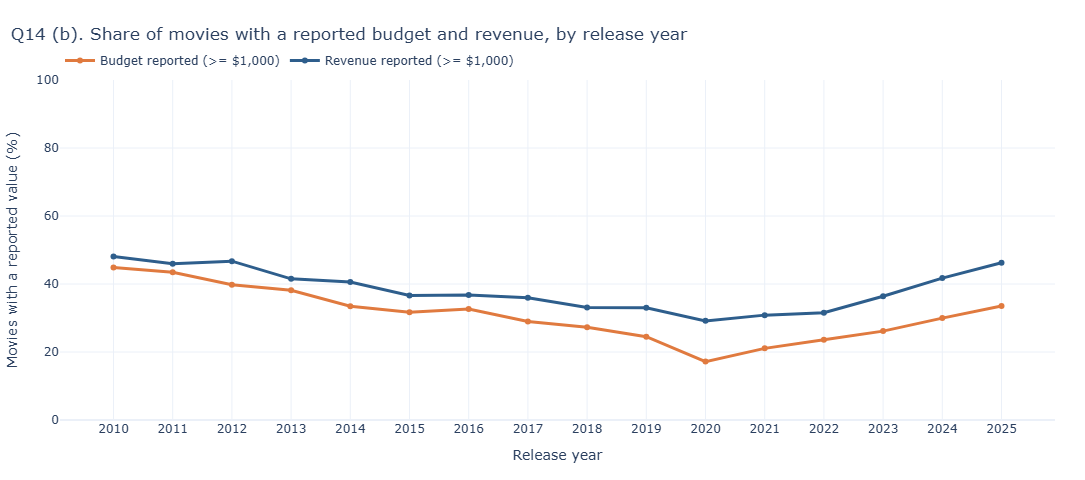

In [74]:
# Second view: how often budget and revenue are reported, by year (are the zeros spread evenly?)
q14_year = (ana.groupby("release_year")
            .agg(pct_budget_reported=("budget_eda", lambda s: s.notna().mean() * 100),
                 pct_revenue_reported=("revenue_eda", lambda s: s.notna().mean() * 100),
                 movies=("title", "size")))
q14_year.index = q14_year.index.astype(int)
q14_votes = ana.groupby("vote_group", observed=True).agg(
    pct_budget_reported=("budget_eda", lambda s: s.notna().mean() * 100),
    pct_revenue_reported=("revenue_eda", lambda s: s.notna().mean() * 100))
display(q14_votes.round(1))

fig = go.Figure()
for col, name, color in [("pct_budget_reported", "Budget reported (>= $1,000)", ACCENT2),
                         ("pct_revenue_reported", "Revenue reported (>= $1,000)", ACCENT)]:
    fig.add_trace(go.Scatter(x=q14_year.index, y=q14_year[col], mode="lines+markers", name=name,
                             line=dict(color=color, width=3), customdata=q14_year["movies"],
                             hovertemplate="%{x}: %{y:.1f}% of %{customdata:,} movies<extra></extra>"))
fig.update_yaxes(title_text="Movies with a reported value (%)", range=[0, 100])
fig.update_xaxes(title_text="Release year", dtick=1)
finish(fig, "Q14 (b). Share of movies with a reported budget and revenue, by release year", height=480,
       legend=dict(orientation="h", y=1.1, x=0))

In [75]:
budget_A = q14[(q14["version"] == "A. All records") & (q14["field"] == "Budget")].iloc[0]
budget_C = q14[(q14["version"] == "C. Exclude zeros and < $1,000") & (q14["field"] == "Budget")].iloc[0]
revenue_A = q14[(q14["version"] == "A. All records") & (q14["field"] == "Revenue")].iloc[0]
revenue_C = q14[(q14["version"] == "C. Exclude zeros and < $1,000") & (q14["field"] == "Revenue")].iloc[0]
show_interpretation(
    f"Keeping zero values produces median budget {fmt_money(budget_A['median'])} and median revenue {fmt_money(revenue_A['median'])}; "
    f"excluding zero/placeholder values changes these to {fmt_money(budget_C['median'])} and {fmt_money(revenue_C['median'])}. "
    f"The reporting-rate chart shows that availability differs across years and vote-count groups. Zero may mean 'not reported', "
    "but that cannot be confirmed for every record. Financial conclusions should therefore be based on reported-value subsets and disclose their coverage."
)


**Interpretation.** Keeping zero values produces median budget $0K and median revenue $0K; excluding zero/placeholder values changes these to $10.0M and $6.4M. The reporting-rate chart shows that availability differs across years and vote-count groups. Zero may mean 'not reported', but that cannot be confirmed for every record. Financial conclusions should therefore be based on reported-value subsets and disclose their coverage.

### Question 15: How has genre distribution changed across release periods, and how do median ratings compare?

For each 4-year period, a genre's **share** is the percentage of that period's movies that carry the genre. Because a movie can have several genres, the shares in a period add up to more than 100%. The second heatmap shows the median rating for each genre and period; cells with fewer than 20 movies are left blank.

In [76]:
MIN_CELL_15 = 20
period_movies = genre_long.groupby("release_period", observed=True)["movie_id"].nunique()
q15_counts = genre_long.groupby(["genre", "release_period"], observed=True)["movie_id"].nunique().unstack()
q15_share = q15_counts.div(period_movies, axis=1) * 100
genre_order15 = q15_counts.sum(axis=1).sort_values(ascending=False).index
q15_share = q15_share.loc[genre_order15]
q15_counts = q15_counts.loc[genre_order15]
q15_share["change_pts"] = q15_share[PERIODS[-1]] - q15_share[PERIODS[0]]

q15_rating = genre_long.groupby(["genre", "release_period"], observed=True)["vote_average"].median().unstack().loc[genre_order15]
q15_rating_masked = q15_rating.where(q15_counts >= MIN_CELL_15)

print("Movies per period:", period_movies.to_dict())
display(q15_share.round(1).sort_values("change_pts"))
display(q15_rating.round(2))

Movies per period: {'2010–2013': 3931, '2014–2017': 5180, '2018–2021': 5023, '2022–2025': 3834}


release_period,2010–2013,2014–2017,2018–2021,2022–2025,change_pts
genre,,,,,
TV Movie,5.2,6.7,5.2,1.7,-3.4
Drama,44.1,44.5,42.4,41.7,-2.4
Animation,9.7,7.5,8.4,7.5,-2.2
Romance,15.7,15.0,13.1,13.6,-2.2
Family,9.2,8.2,9.0,7.2,-2.0
Comedy,35.3,32.9,31.9,34.2,-1.1
Documentary,6.0,6.4,6.7,5.3,-0.6
Science Fiction,9.0,8.7,8.5,8.8,-0.2
Western,0.7,0.8,0.7,0.9,0.2


release_period,2010–2013,2014–2017,2018–2021,2022–2025
genre,,,,
Drama,6.43,6.47,6.60,6.65
Comedy,6.10,6.11,6.40,6.41
Thriller,5.94,5.92,6.13,6.23
Action,6.20,6.16,6.38,6.44
Horror,5.38,5.49,5.86,6.00
Romance,6.30,6.30,6.62,6.50
Crime,6.32,6.31,6.45,6.41
Adventure,6.35,6.42,6.72,6.72
Science Fiction,6.10,6.02,6.20,6.41


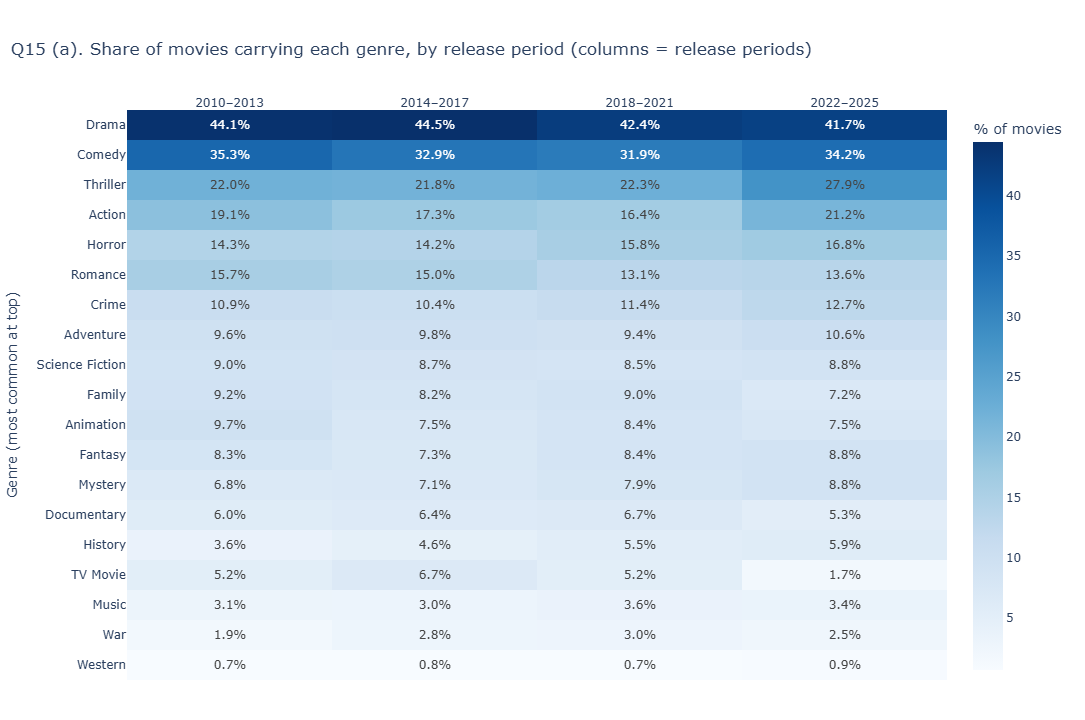

In [77]:
fig = go.Figure(go.Heatmap(
    z=q15_share[PERIODS].values, x=PERIODS, y=list(genre_order15), colorscale="Blues",
    colorbar=dict(title="% of movies"), customdata=q15_counts[PERIODS].values,
    texttemplate="%{z:.1f}%",
    hovertemplate="%{y}, %{x}<br>Share of movies: %{z:.1f}%<br>Movies: %{customdata:,}<extra></extra>"))
fig.update_yaxes(title_text="Genre (most common at top)", autorange="reversed")
fig.update_xaxes(title_text="", side="top")
finish(fig, "Q15 (a). Share of movies carrying each genre, by release period (columns = release periods)", height=720,
       margin=dict(t=110, l=60, r=30, b=40))

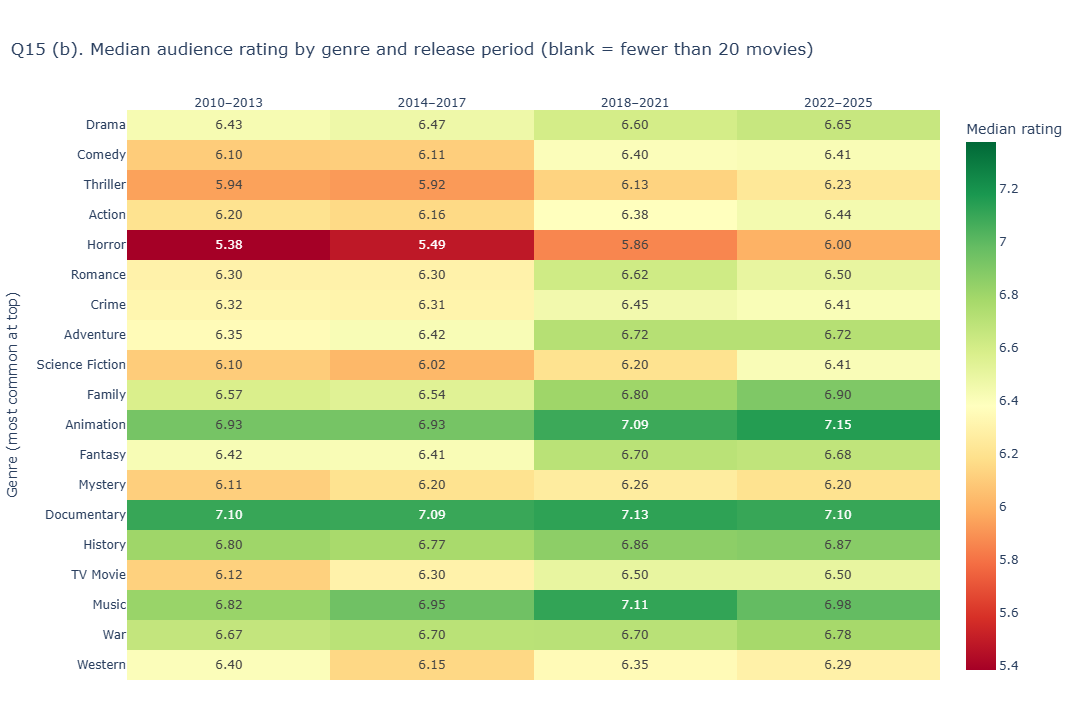

In [78]:
fig = go.Figure(go.Heatmap(
    z=q15_rating_masked[PERIODS].values, x=PERIODS, y=list(genre_order15), colorscale="RdYlGn", zmid=float(overall_med),
    colorbar=dict(title="Median rating"), customdata=q15_counts[PERIODS].values,
    texttemplate="%{z:.2f}",
    hovertemplate="%{y}, %{x}<br>Median rating: %{z:.2f}<br>Movies: %{customdata:,}<extra></extra>"))
fig.update_yaxes(title_text="Genre (most common at top)", autorange="reversed")
fig.update_xaxes(title_text="", side="top")
finish(fig, f"Q15 (b). Median audience rating by genre and release period (blank = fewer than {MIN_CELL_15} movies)",
       height=720, margin=dict(t=110, l=60, r=30, b=40))

In [79]:
change = q15_share["change_pts"].dropna()
if len(change):
    rising = change.idxmax()
    falling = change.idxmin()
    period_rating = ana.groupby("release_period", observed=True)["vote_average"].median().dropna()
    rating_change = (period_rating.iloc[-1] - period_rating.iloc[0]) if len(period_rating) >= 2 else np.nan
    extra = (f" Overall median rating changed by {rating_change:+.2f} points between the first and last available periods."
             if pd.notna(rating_change) else "")
    show_interpretation(
        f"The genre share with the largest increase is **{rising}** ({change.loc[rising]:+.1f} percentage points), "
        f"while **{falling}** has the largest decrease ({change.loc[falling]:+.1f} points).{extra} "
        "Genre shares can sum to more than 100% because a movie may have multiple genres. Rating shifts can also reflect changes in vote coverage."
    )
else:
    show_interpretation("There are insufficient genre-by-period observations to calculate changes.")


**Interpretation.** The genre share with the largest increase is **Thriller** (+5.9 percentage points), while **TV Movie** has the largest decrease (-3.4 points). Overall median rating changed by +0.23 points between the first and last available periods. Genre shares can sum to more than 100% because a movie may have multiple genres. Rating shifts can also reflect changes in vote coverage.

## 19. Overall Findings from Exploratory Data Analysis

The following summary is generated from the current calculations above. It describes patterns in this dataset only and distinguishes reported financial records from missing or imputed source values.


In [80]:
summary_lines = []
if not q1_tbl.empty:
    top_budget = q1_tbl["median_revenue"].idxmax()
    summary_lines.append(f"- **Budget and revenue:** median revenue is highest in budget range **{top_budget}** ({fmt_money(q1_tbl.loc[top_budget, 'median_revenue'])}).")
if not q2_tbl.empty:
    top_genre = q2_tbl["median"].idxmax()
    summary_lines.append(f"- **Genre revenue:** **{top_genre}** has the highest median reported revenue among the genres meeting the record threshold ({fmt_money(q2_tbl.loc[top_genre, 'median'])}).")
if not q6_tbl.empty:
    top_rating_genre = q6_tbl["median"].idxmax()
    low_rating_genre = q6_tbl["median"].idxmin()
    summary_lines.append(f"- **Audience ratings:** the highest and lowest genre medians are **{top_rating_genre}** ({q6_tbl.loc[top_rating_genre, 'median']:.2f}) and **{low_rating_genre}** ({q6_tbl.loc[low_rating_genre, 'median']:.2f}).")
if pd.notna(rho_q7):
    summary_lines.append(f"- **Popularity and ratings:** Spearman correlation is {rho_q7:.2f}; interpret this as an association, not causation.")
if not q11.empty:
    peak_y = int(q11["releases"].idxmax())
    summary_lines.append(f"- **Release trends:** the largest release count in the dataset occurs in {peak_y} ({int(q11.loc[peak_y, 'releases']):,} movies).")
if not q15_share.empty:
    delta = q15_share["change_pts"].dropna()
    if len(delta):
        g = delta.idxmax()
        summary_lines.append(f"- **Genre trends:** **{g}** shows the largest share increase between the first and last release periods ({delta.loc[g]:+.1f} percentage points).")
summary_lines.append(f"- **Coverage limitation:** {len(fin2):,} movies have both observed budget and revenue values of at least $1,000; conclusions about revenue are based on this subset.")
summary_lines.append("- **Financial caution:** revenue minus budget is not audited profit because marketing, distribution, taxes, cinema shares and other costs are unavailable.")
display(Markdown("\n".join(summary_lines)))


- **Budget and revenue:** median revenue is highest in budget range **$100M+** ($404.0M).
- **Genre revenue:** **Adventure** has the highest median reported revenue among the genres meeting the record threshold ($41.0M).
- **Audience ratings:** the highest and lowest genre medians are **Documentary** (7.10) and **Horror** (5.73).
- **Popularity and ratings:** Spearman correlation is 0.20; interpret this as an association, not causation.
- **Release trends:** the largest release count in the dataset occurs in 2018 (1,426 movies).
- **Genre trends:** **Thriller** shows the largest share increase between the first and last release periods (+5.9 percentage points).
- **Coverage limitation:** 4,090 movies have both observed budget and revenue values of at least $1,000; conclusions about revenue are based on this subset.
- **Financial caution:** revenue minus budget is not audited profit because marketing, distribution, taxes, cinema shares and other costs are unavailable.

## 20. Selecting EDA findings for hypothesis testing

Seven claims are selected because they connect directly to the descriptive EDA and use **only test methods named in the supplied L12/L13 lecture slides**: chi-square test of independence, one-sample t-test, two-sample t-test, permutation test, and A/B testing by randomisation. Not every EDA question needs its own test.

| EDA-derived claim | EDA source | Method shown in L12/L13 |
|---|---|---|
| 1. Earning back the reported budget is associated with budget range. | Q1, Q14 | Chi-square test of independence |
| 2. Mean ratings differ between single-genre and multi-genre movies. | Q9 | Permutation test for comparing samples |
| 3. Median ratings differ between the lowest and highest popularity deciles. | Q7 | Permutation test for comparing samples |
| 4. Thriller tagging is associated with release period. | Q15 | Chi-square test of independence |
| 5. The mean log revenue-to-budget ratio differs from the break-even value. | Q1, Q14 | One-sample t-test |
| 6. Mean ratings differ between short and long movies. | Q10 | Two-sample t-test |
| 7. The proportion rated at least 7 differs between low-vote and high-vote groups. | Q8 | A/B testing / randomisation |

**Interpretation note:** The claims are exploratory because they were selected after inspecting the same dataset. Treat p-values as evidence within this analysis, not independent confirmation on a separate sample. Use \(\alpha=0.05\). No test establishes causation.


## 21. Hypothesis Testing

The tests below use only methods listed in the supplied L12/L13 slides: chi-square tests, one-sample and two-sample t-tests, permutation testing, and A/B testing by randomisation. Each test states the hypotheses, reports the computed statistic and p-value, and makes a decision using \(\alpha=0.05\).

Decision rule: reject \(H_0\) when \(p \leq 0.05\); otherwise, fail to reject \(H_0\). Failing to reject does not prove that \(H_0\) is true. Interpret results alongside sample sizes and effect sizes.


In [81]:
ALPHA = 0.05
N_PERM = 10_000
rng = np.random.default_rng(42)

def test_decision(p, alpha=ALPHA):
    return "Reject H0" if p <= alpha else "Fail to reject H0"

def p_label(p, n_perm=None):
    if n_perm is not None and p == 0:
        return f"< {1 / n_perm:.4f} (no equally/extremely large result in {n_perm:,} permutations)"
    return f"{p:.4g}"

def permutation_test(a, b, statistic="median", n_perm=N_PERM, rng=rng, chunk_size=250):
    a = pd.Series(a, dtype="float64").dropna().to_numpy()
    b = pd.Series(b, dtype="float64").dropna().to_numpy()
    if len(a) < 2 or len(b) < 2:
        raise ValueError("Each permutation-test group must contain at least two valid observations.")
    stat_fn = np.mean if statistic == "mean" else np.median
    observed = float(stat_fn(a) - stat_fn(b))
    pooled = np.concatenate([a, b])
    perm_stats = np.empty(n_perm, dtype=float)
    for start in range(0, n_perm, chunk_size):
        k = min(chunk_size, n_perm - start)
        shuffled = rng.permuted(np.tile(pooled, (k, 1)), axis=1)
        perm_stats[start:start+k] = stat_fn(shuffled[:, :len(a)], axis=1) - stat_fn(shuffled[:, len(a):], axis=1)
    extreme = int(np.sum(np.abs(perm_stats) >= abs(observed)))
    p = extreme / n_perm
    return {"a": a, "b": b, "observed": observed, "permutations": perm_stats, "extreme": extreme, "p": p}

def show_permutation_plot(result, title, x_title):
    fig = go.Figure()
    fig.add_trace(go.Histogram(x=result["permutations"], nbinsx=70, marker_color=GREY,
                               name="Permuted statistic",
                               hovertemplate="Statistic: %{x:.4g}<br>Permutations: %{y}<extra></extra>"))
    fig.add_vline(x=result["observed"], line_color=ACCENT2, line_width=3,
                  annotation_text=f"Observed = {result['observed']:.4g}", annotation_position="top left")
    fig.add_vline(x=-abs(result["observed"]), line_color=ACCENT2, line_dash="dot",
                  annotation_text="Opposite tail", annotation_position="top right")
    fig.update_xaxes(title_text=x_title)
    fig.update_yaxes(title_text="Number of permutations")
    finish(fig, title, height=460, showlegend=False)

def chi_square_independence(observed):
    observed = np.asarray(observed, dtype=float)
    row_totals = observed.sum(axis=1, keepdims=True)
    col_totals = observed.sum(axis=0, keepdims=True)
    expected = row_totals @ col_totals / observed.sum()
    contributions = (observed - expected) ** 2 / expected
    chi2 = float(contributions.sum())
    dfree = int((observed.shape[0] - 1) * (observed.shape[1] - 1))
    p = float(stats.chi2.sf(chi2, dfree))
    critical = float(stats.chi2.ppf(1 - ALPHA, dfree))
    return expected, contributions, chi2, dfree, p, critical

print(f"Significance level alpha = {ALPHA}; permutations per randomisation test = {N_PERM:,}.")


Significance level alpha = 0.05; permutations per randomisation test = 10,000.


### HT1 / Decision 1. Is earning back the budget associated with budget range?

**From EDA:** Q1 and Q14 compare the share of movies whose reported revenue is at least their reported production budget.

- \(H_0\): budget range and earning back the reported budget are independent.
- \(H_1\): budget range and earning back the reported budget are associated.
- Method: chi-square test of independence; \(\alpha=0.05\).
- Assumption: each movie contributes to one budget-range × outcome cell, and expected cell counts should be sufficiently large.


Observed counts (O):


earned_back,Earned back,Did not earn back
budget_range,,
Under $1M,140,58
$1M–10M,758,628
$10M–50M,980,727
$50M–100M,304,97
$100M+,344,54


Expected counts under H0 (E):


earned_back,Earned back,Did not earn back
budget_range,,
Under $1M,122.3,75.7
$1M–10M,856.0,530.0
$10M–50M,1054.2,652.8
$50M–100M,247.7,153.3
$100M+,245.8,152.2


Cell contributions (O-E)^2/E:


earned_back,Earned back,Did not earn back
budget_range,,
Under $1M,2.57,4.14
$1M–10M,11.22,18.12
$10M–50M,5.23,8.45
$50M–100M,12.82,20.70
$100M+,39.23,63.35


Minimum expected count = 75.7
Chi-square = 185.823; df = 4; critical value = 9.488; p-value = 4.185e-39
Decision: Reject H0


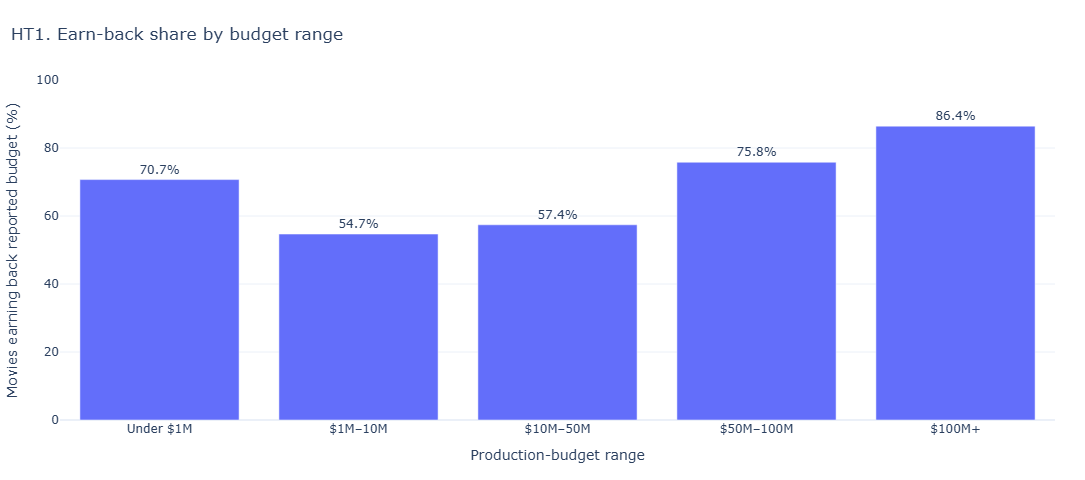

In [82]:
obs1 = pd.crosstab(fin2["budget_range"], fin2["earned_back"].map({True: "Earned back", False: "Did not earn back"}))
obs1 = obs1.reindex(index=BUDGET_RANGES, columns=["Earned back", "Did not earn back"], fill_value=0)
exp1, contrib1, chi1, df1, p1, crit1 = chi_square_independence(obs1.values)
print("Observed counts (O):"); display(obs1)
print("Expected counts under H0 (E):"); display(pd.DataFrame(exp1, index=obs1.index, columns=obs1.columns).round(1))
print("Cell contributions (O-E)^2/E:"); display(pd.DataFrame(contrib1, index=obs1.index, columns=obs1.columns).round(2))
print(f"Minimum expected count = {exp1.min():.1f}")
print(f"Chi-square = {chi1:.3f}; df = {df1}; critical value = {crit1:.3f}; p-value = {p_label(p1)}")
print("Decision:", test_decision(p1))
rate1 = obs1["Earned back"] / obs1.sum(axis=1) * 100
fig = px.bar(x=rate1.index.astype(str), y=rate1.values, text=[f"{v:.1f}%" for v in rate1.values],
             labels={"x":"Production-budget range", "y":"Movies earning back reported budget (%)"},
             title="HT1. Share of movies earning back their reported budget by budget range")
fig.update_traces(textposition="outside", hovertemplate="%{x}<br>Earned back: %{y:.1f}%<extra></extra>")
fig.update_yaxes(range=[0, min(100, max(rate1.max()*1.18, 10))])
finish(fig, "HT1. Earn-back share by budget range", height=480, showlegend=False)


**Interpretation:** Use the computed chi-square statistic, expected counts and p-value above. A rejection supports an association between budget range and earning back the reported budget; it does not show that budget causes the outcome.


### HT2 / Decision 2. Do single-genre and multi-genre movies have different mean ratings?

**From EDA:** Q9 compares ratings by number of genres.

- \(H_0\): the mean rating is the same for single-genre and multi-genre movies.
- \(H_1\): the mean rating differs.
- Method: two-group permutation test of the difference in means; \(\alpha=0.05\).
- Groups are disjoint at the movie level: exactly one genre versus two or more genres.


Multi-genre: n=13,606, mean=6.349; single-genre: n=4,362, mean=6.268
Observed difference (multi - single) = 0.0806 rating points
Extreme permutations = 0/10,000; p-value = < 0.0001 (no equally/extremely large result in 10,000 permutations)
Decision: Reject H0


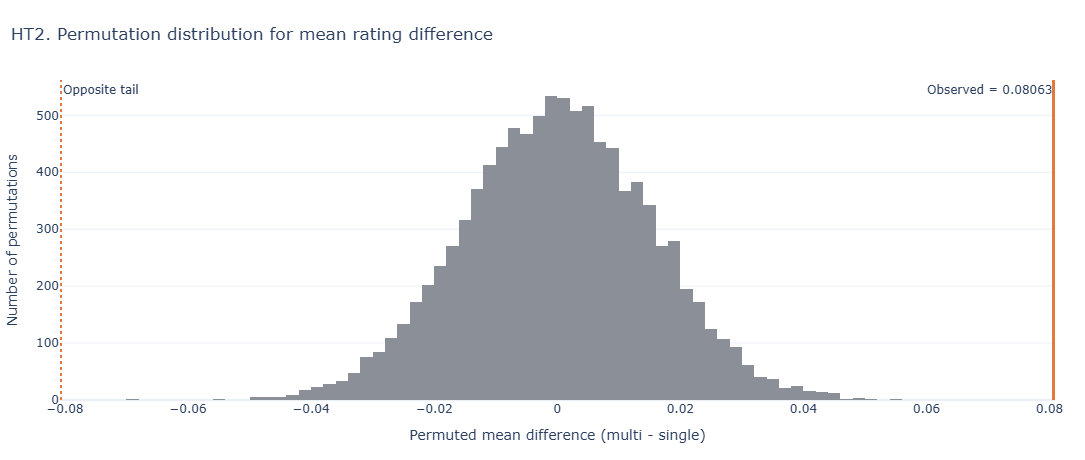

In [83]:
rating_groups = ana.dropna(subset=["n_genres", "vote_average"])
rating_multi = rating_groups.loc[rating_groups["n_genres"] >= 2, "vote_average"]
rating_single = rating_groups.loc[rating_groups["n_genres"] == 1, "vote_average"]
res3 = permutation_test(rating_multi, rating_single, statistic="mean")
print(f"Multi-genre: n={len(res3['a']):,}, mean={np.mean(res3['a']):.3f}; "
      f"single-genre: n={len(res3['b']):,}, mean={np.mean(res3['b']):.3f}")
print(f"Observed difference (multi - single) = {res3['observed']:.4f} rating points")
print(f"Extreme permutations = {res3['extreme']:,}/{N_PERM:,}; p-value = {p_label(res3['p'], N_PERM)}")
print("Decision:", test_decision(res3["p"]))
show_permutation_plot(res3, "HT2. Permutation distribution for mean rating difference", "Permuted mean difference (multi - single)")


**Interpretation:** The permutation result evaluates whether the observed mean-rating difference is unusual under shuffled group labels. Consider both the p-value and the size of the difference on the 0–10 rating scale.


### HT3 / Decision 3. Do the highest- and lowest-popularity deciles have different median ratings?

**From EDA:** Q7 examines popularity and audience ratings.

- Groups: lowest popularity decile (D1) and highest popularity decile (D10), among movies with observed positive popularity and observed ratings.
- \(H_0\): the median ratings are equal.
- \(H_1\): the median ratings differ.
- Method: two-group permutation test of the difference in medians; \(\alpha=0.05\).


D10: n=1,798, median rating=6.847; D1: n=1,798, median rating=6.200
Observed median difference (D10 - D1) = 0.6465
Extreme permutations = 0/10,000; p-value = < 0.0001 (no equally/extremely large result in 10,000 permutations)
Decision: Reject H0


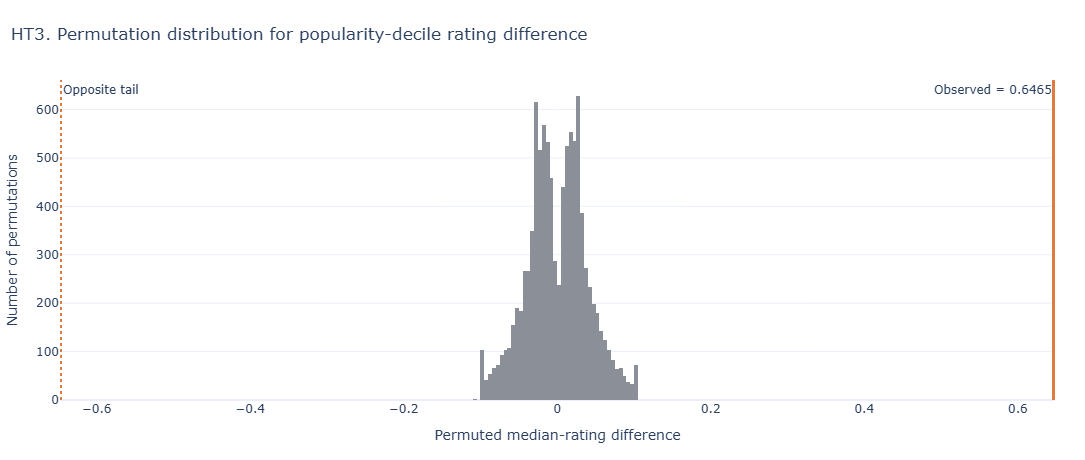

In [84]:
q7_test = q7.dropna(subset=["pop_decile", "vote_average"])
rating_d1 = q7_test.loc[q7_test["pop_decile"] == "D1", "vote_average"]
rating_d10 = q7_test.loc[q7_test["pop_decile"] == "D10", "vote_average"]
res7 = permutation_test(rating_d10, rating_d1, statistic="median")
print(f"D10: n={len(res7['a']):,}, median rating={np.median(res7['a']):.3f}; "
      f"D1: n={len(res7['b']):,}, median rating={np.median(res7['b']):.3f}")
print(f"Observed median difference (D10 - D1) = {res7['observed']:.4f}")
print(f"Extreme permutations = {res7['extreme']:,}/{N_PERM:,}; p-value = {p_label(res7['p'], N_PERM)}")
print("Decision:", test_decision(res7["p"]))
show_permutation_plot(res7, "HT3. Permutation distribution for popularity-decile rating difference", "Permuted median-rating difference")


**Interpretation:** A rejection indicates that the median ratings differ between the highest and lowest popularity deciles. Popularity is observational, so this is not a causal test.


### HT4 / Decision 4. Is Thriller tagging associated with release period?

**From EDA:** Q15 compares genre shares over time.

- Each movie is represented once, with outcome Thriller-tagged / not Thriller-tagged.
- \(H_0\): release period and Thriller-tag status are independent.
- \(H_1\): they are associated.
- Method: chi-square test of independence; \(\alpha=0.05\).
- Movies with missing genre lists or release periods are excluded.


,Not Thriller,Thriller
release_period,,
2010–2013,3066,865
2014–2017,4052,1128
2018–2021,3902,1121
2022–2025,2765,1069


,Not Thriller,Thriller
Expected counts under H0,,
2010–2013,3015.9,915.1
2014–2017,3974.1,1205.9
2018–2021,3853.6,1169.4
2022–2025,2941.4,892.6


Minimum expected count = 892.6
Chi-square = 58.211; df = 3; critical value = 7.815; p-value = 1.417e-12
Decision: Reject H0


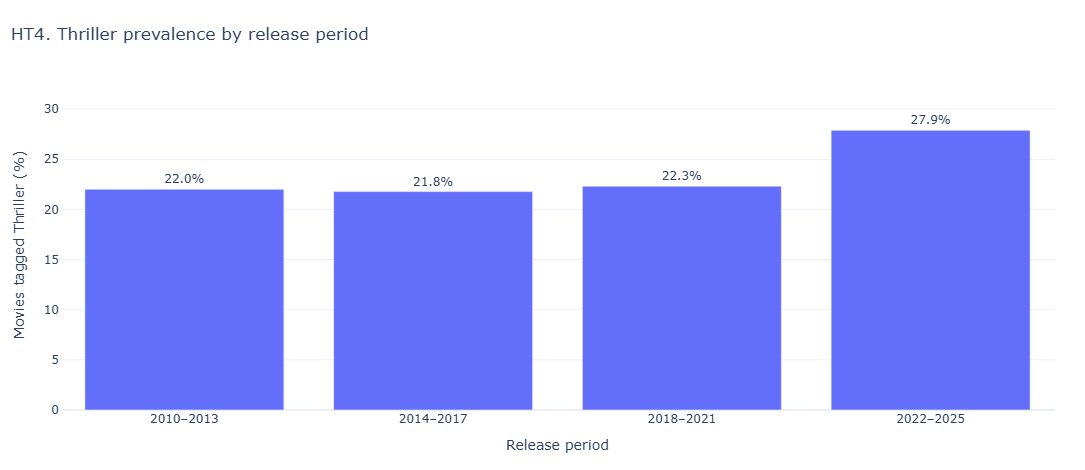

In [85]:
thr = ana[ana["genre_list"].apply(lambda g: isinstance(g, list)) & ana["release_period"].notna()].copy()
thr["has_thriller"] = thr["genre_list"].apply(lambda g: "Thriller" in g)
obs10 = pd.crosstab(thr["release_period"], thr["has_thriller"]).reindex(index=PERIODS, columns=[False, True], fill_value=0)
obs10.columns = ["Not Thriller", "Thriller"]
exp10, contrib10, chi10, df10, p10, crit10 = chi_square_independence(obs10.values)
display(obs10)
display(pd.DataFrame(exp10, index=obs10.index, columns=obs10.columns).round(1).rename_axis("Expected counts under H0"))
print(f"Minimum expected count = {exp10.min():.1f}")
print(f"Chi-square = {chi10:.3f}; df = {df10}; critical value = {crit10:.3f}; p-value = {p_label(p10)}")
print("Decision:", test_decision(p10))
thr_pct = thr.groupby("release_period", observed=True)["has_thriller"].mean().reindex(PERIODS) * 100
fig = px.bar(x=thr_pct.index.astype(str), y=thr_pct.values, text=[f"{v:.1f}%" for v in thr_pct.values],
             labels={"x":"Release period", "y":"Movies tagged Thriller (%)"},
             title="HT4. Share of movies tagged Thriller by release period")
fig.update_traces(textposition="outside", hovertemplate="%{x}<br>Thriller-tagged: %{y:.1f}%<extra></extra>")
fig.update_yaxes(range=[0, min(100, max(thr_pct.dropna())*1.18 if thr_pct.notna().any() else 100)])
finish(fig, "HT4. Thriller prevalence by release period", height=470, showlegend=False)


**Interpretation:** A rejection indicates that the share of movies tagged Thriller varies across release periods in this dataset. Because a movie can have multiple genres, this test uses a binary Thriller tag per movie and does not require genre shares to sum to 100%.


### HT5 / Decision 5. Does the mean log revenue-to-budget ratio differ from break-even?

**From EDA:** Q1 and Q14 examine reported budgets and revenues. Use only movies with both observed financial values of at least $1,000.

- \(H_0\): the population mean of \(\log(\text{revenue}/\text{budget})\) is 0 (break-even on the ratio scale).
- \(H_1\): the population mean differs from 0.
- Method: one-sample t-test, as listed in L13.
- A positive mean is consistent with revenue exceeding budget on average in this selected sample; it is not audited profit.


n=4,090; mean log ratio=0.0899; median revenue/budget ratio=1.590x
One-sample t statistic=3.0143; p-value=0.002592
Decision: Reject H0


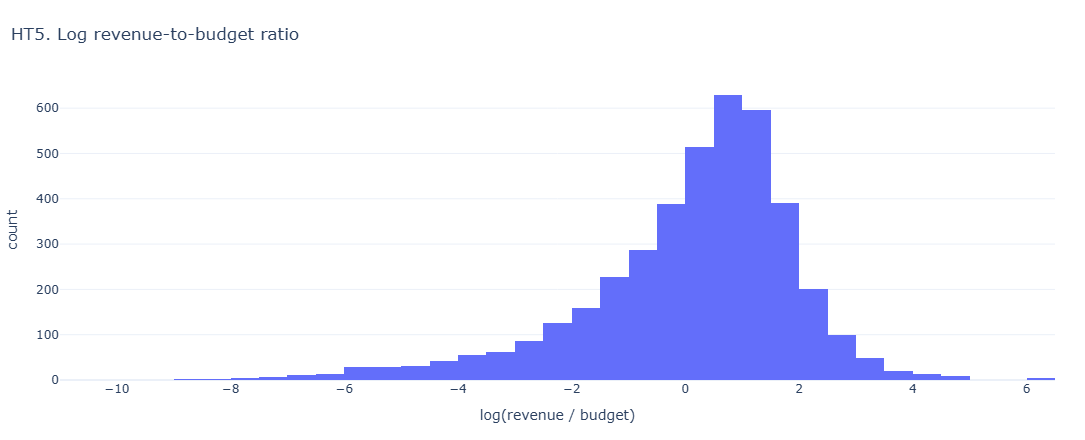

In [86]:
ratio_data = fin2.loc[(fin2["budget_eda"] > 0) & (fin2["revenue_eda"] > 0), ["budget_eda", "revenue_eda"]].dropna().copy()
ratio_data["log_ratio"] = np.log(ratio_data["revenue_eda"] / ratio_data["budget_eda"])
t5 = stats.ttest_1samp(ratio_data["log_ratio"], popmean=0.0, alternative="two-sided")
print(f"n={len(ratio_data):,}; mean log ratio={ratio_data['log_ratio'].mean():.4f}; median revenue/budget ratio={np.median(ratio_data['revenue_eda'] / ratio_data['budget_eda']):.3f}x")
print(f"One-sample t statistic={t5.statistic:.4f}; p-value={p_label(t5.pvalue)}")
print("Decision:", test_decision(t5.pvalue))
fig = px.histogram(ratio_data, x="log_ratio", nbins=50, title="HT5. Distribution of log revenue-to-budget ratios", labels={"log_ratio":"log(revenue / budget)", "count":"Number of movies"})
finish(fig, "HT5. Log revenue-to-budget ratio", height=440, showlegend=False)


**Interpretation:** Compare the calculated p-value with 0.05 and report the observed mean. The test concerns reported gross revenue relative to reported production budget, not total movie profitability.


### HT6 / Decision 6. Do short and long movies have different mean audience ratings?

**From EDA:** Q10 compares ratings across runtime groups. For this focused comparison, short movies are under 90 minutes and long movies are at least 120 minutes; movies in the middle are not included.

- \(H_0\): the two groups have equal mean audience ratings.
- \(H_1\): their mean audience ratings differ.
- Method: independent two-sample t-test, as listed in L13.


Short (<90 min): n=4,435, mean rating=6.177; long (>=120 min): n=2,645, mean rating=6.798
Observed mean difference (short - long)=-0.6209
Two-sample t statistic=-29.9347; p-value=4.903e-185
Decision: Reject H0


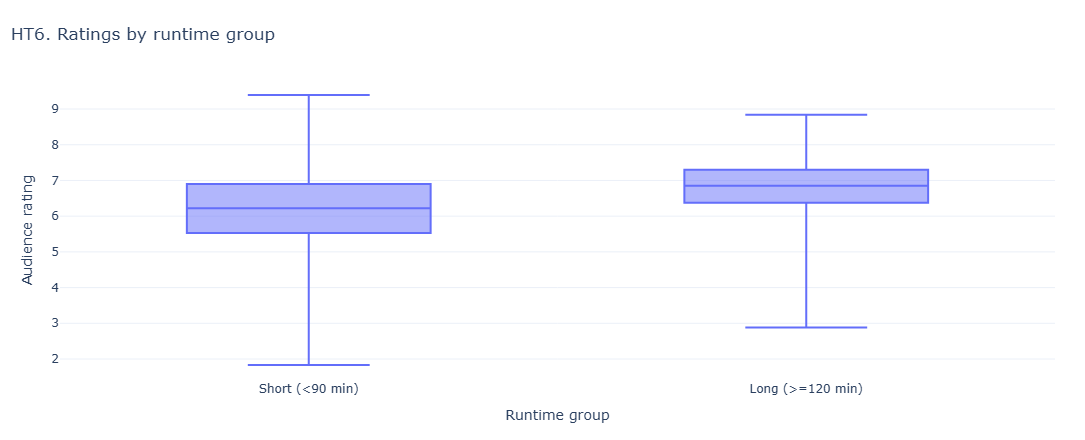

In [87]:
runtime_test = ana.dropna(subset=["runtime_eda", "vote_average"]).copy()
short_ratings = runtime_test.loc[runtime_test["runtime_eda"] < 90, "vote_average"]
long_ratings = runtime_test.loc[runtime_test["runtime_eda"] >= 120, "vote_average"]
t6 = stats.ttest_ind(short_ratings, long_ratings, equal_var=False, alternative="two-sided")
print(f"Short (<90 min): n={len(short_ratings):,}, mean rating={short_ratings.mean():.3f}; long (>=120 min): n={len(long_ratings):,}, mean rating={long_ratings.mean():.3f}")
print(f"Observed mean difference (short - long)={short_ratings.mean() - long_ratings.mean():.4f}")
print(f"Two-sample t statistic={t6.statistic:.4f}; p-value={p_label(t6.pvalue)}")
print("Decision:", test_decision(t6.pvalue))
fig = px.box(runtime_test[runtime_test["runtime_eda"].lt(90) | runtime_test["runtime_eda"].ge(120)].assign(runtime_group=lambda d: np.where(d["runtime_eda"] < 90, "Short (<90 min)", "Long (>=120 min)")), x="runtime_group", y="vote_average", points=False, title="HT6. Audience ratings for short and long movies", labels={"runtime_group":"Runtime group", "vote_average":"Audience rating"})
finish(fig, "HT6. Ratings by runtime group", height=440, showlegend=False)


**Interpretation:** Report the mean difference as well as the p-value. This is an observational comparison, so it does not show that runtime causes ratings to change.


### HT7 / Decision 7. Does the share rated at least 7 differ between low-vote and high-vote movies?

**From EDA:** Q8 compares audience ratings across vote-count groups. Here, the bottom and top vote-count quartiles form the two groups.

- \(H_0\): the proportion rated at least 7 is equal in the low-vote and high-vote groups.
- \(H_1\): the proportions differ.
- Method: A/B-style randomisation test, matching the A/B testing / randomisation approach in L12/L13.


Low-vote group (<= Q1=80 votes): n=4,576, rated >=7: 18.86%
High-vote group (>= Q3=428 votes): n=4,495, rated >=7: 31.59%
Observed difference (high - low)=12.731 percentage points
Extreme randomisations=0/10,000; randomisation p-value=9.999e-05
Decision: Reject H0


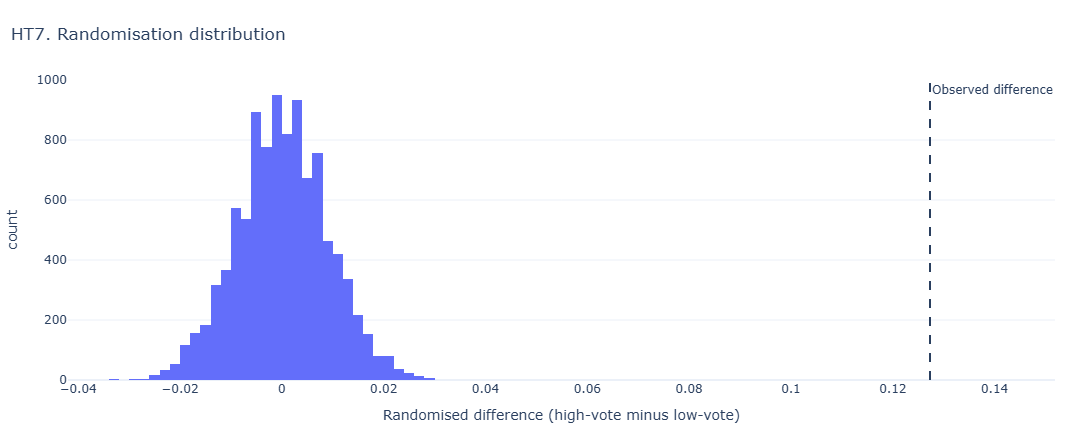

In [88]:
vote_test = ana.dropna(subset=["vote_count", "vote_average"]).copy()
q25_votes, q75_votes = vote_test["vote_count"].quantile([0.25, 0.75])
low_vote = vote_test.loc[vote_test["vote_count"] <= q25_votes, "vote_average"].ge(7).astype(int).to_numpy()
high_vote = vote_test.loc[vote_test["vote_count"] >= q75_votes, "vote_average"].ge(7).astype(int).to_numpy()
obs_diff7 = high_vote.mean() - low_vote.mean()
pooled7 = np.concatenate([high_vote, low_vote])
perm7 = np.empty(N_PERM, dtype=float)
for start in range(0, N_PERM, 250):
    k = min(250, N_PERM - start)
    shuffled7 = rng.permuted(np.tile(pooled7, (k, 1)), axis=1)
    perm7[start:start+k] = shuffled7[:, :len(high_vote)].mean(axis=1) - shuffled7[:, len(high_vote):].mean(axis=1)
extreme7 = int(np.sum(np.abs(perm7) >= abs(obs_diff7)))
p7 = (extreme7 + 1) / (N_PERM + 1)
print(f"Low-vote group (<= Q1={q25_votes:.0f} votes): n={len(low_vote):,}, rated >=7: {low_vote.mean()*100:.2f}%")
print(f"High-vote group (>= Q3={q75_votes:.0f} votes): n={len(high_vote):,}, rated >=7: {high_vote.mean()*100:.2f}%")
print(f"Observed difference (high - low)={obs_diff7*100:.3f} percentage points")
print(f"Extreme randomisations={extreme7:,}/{N_PERM:,}; randomisation p-value={p7:.4g}")
print("Decision:", test_decision(p7))
fig = px.histogram(x=perm7, nbins=50, title="HT7. A/B randomisation distribution for difference in proportions", labels={"x":"Randomised difference (high-vote minus low-vote)", "count":"Number of randomisations"})
fig.add_vline(x=obs_diff7, line_dash="dash", annotation_text="Observed difference")
finish(fig, "HT7. Randomisation distribution", height=440, showlegend=False)


**Interpretation:** Use the observed percentage-point difference and randomisation p-value together. Vote count is not randomly assigned, so the test describes an association between the groups, not a causal effect of receiving more votes.


### Summary of the seven hypothesis tests

The seven tests use methods explicitly named in L12/L13 and address distinct EDA-derived claims. The results should be interpreted with their effect sizes, group sizes and data limitations.


In [89]:
test_summary = pd.DataFrame([
    ["HT1", "Chi-square test of independence", "Budget range × earning back reported budget", f"chi²={chi1:.3f}, df={df1}", p_label(p1), test_decision(p1)],
    ["HT2", "Permutation test", "Multi-genre vs single-genre mean rating", f"mean diff={res3['observed']:.4f}", p_label(res3['p'], N_PERM), test_decision(res3['p'])],
    ["HT3", "Permutation test", "Highest vs lowest popularity-decile median rating", f"median diff={res7['observed']:.4f}", p_label(res7['p'], N_PERM), test_decision(res7['p'])],
    ["HT4", "Chi-square test of independence", "Release period × Thriller tag", f"chi²={chi10:.3f}, df={df10}", p_label(p10), test_decision(p10)],
    ["HT5", "One-sample t-test", "Mean log revenue-to-budget ratio vs break-even", f"t={t5.statistic:.4f}; mean={ratio_data['log_ratio'].mean():.4f}", p_label(t5.pvalue), test_decision(t5.pvalue)],
    ["HT6", "Two-sample t-test", "Short vs long movie mean rating", f"t={t6.statistic:.4f}; mean diff={short_ratings.mean()-long_ratings.mean():.4f}", p_label(t6.pvalue), test_decision(t6.pvalue)],
    ["HT7", "A/B randomisation test", "High-vote vs low-vote share rated >=7", f"difference={obs_diff7*100:.3f} percentage points", p_label(p7), test_decision(p7)],
], columns=["Test", "Method from L12/L13", "EDA-derived claim", "Test statistic / effect", "p-value", "Decision at alpha=0.05"])
display(test_summary)


,Test,Method from L12/L13,EDA-derived claim,Test statistic / effect,p-value,Decision at alpha=0.05
0,HT1,Chi-square test of independence,Budget range × earning back reported budget,"chi²=185.823, df=4",4.185e-39,Reject H0
1,HT2,Permutation test,Multi-genre vs single-genre mean rating,mean diff=0.0806,< 0.0001 (no equally/extremely large result in...,Reject H0
2,HT3,Permutation test,Highest vs lowest popularity-decile median rating,median diff=0.6465,< 0.0001 (no equally/extremely large result in...,Reject H0
3,HT4,Chi-square test of independence,Release period × Thriller tag,"chi²=58.211, df=3",1.417e-12,Reject H0
4,HT5,One-sample t-test,Mean log revenue-to-budget ratio vs break-even,t=3.0143; mean=0.0899,0.002592,Reject H0
5,HT6,Two-sample t-test,Short vs long movie mean rating,t=-29.9347; mean diff=-0.6209,4.903e-185,Reject H0
6,HT7,A/B randomisation test,High-vote vs low-vote share rated >=7,difference=12.731 percentage points,9.999e-05,Reject H0


## 22. Machine Learning: Predicting Movie Revenue

The hypothesis tests asked whether groups differ. This section asks a predictive question: **how well can a movie's box-office revenue be predicted from information known before release?** Two regression models are trained on the same data and tested on the same held-out movies:

- **Random Forest Regressor:** many deep decision trees trained independently on bootstrap samples; their predictions are averaged.
- **Gradient Boosting Regressor:** many shallow trees trained one after another, each correcting the errors of the earlier ones.

**Target variable:** `revenue` itself, in US dollars (the cleaned column `revenue_eda`). Nothing is transformed, so every error is in dollars and can be read directly.

| Decision | Choice | Reason |
|---|---|---|
| Records used | Movies with a valid reported budget **and** revenue (both at least $1,000) | In this dataset a budget or revenue of 0 means "not reported", not a real zero. These values are **not** used as targets or inputs and are **not** imputed. The model therefore applies only to movies with reported finances. |
| Features | Budget, runtime, release year, release month, number of genres, genre indicators, original-language indicators | All are known before or at release. |
| Excluded features | `vote_average`, `vote_count`, `popularity`, `profit_estimate`, `roi_percent` | These are measured after release or are calculated from revenue, so using them would leak the answer. |
| Missing feature values | Median imputation fitted **on the training set only** | Stops test-set information from influencing preprocessing. |
| Evaluation | One 80/20 split shared by both models, plus 5-fold cross-validation on the training set | A fair, like-for-like comparison. The test set is used once for the final scores. |

**Metrics:** MAE (average absolute error in dollars), RMSE (like MAE but punishes large errors more) and R² (share of the variation in revenue explained; 0 means no better than always predicting the average).

### 22.1 Prepare the modelling data

The existing analysis table `ana` is reused. It holds observed (not imputed) budgets, revenues and runtimes, and already sets financial values below $1,000 to missing.

In [90]:
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from collections import Counter

ML_SEED = 42

# Reuse the cleaned analysis table. Keep only movies with valid, reported budget AND revenue.
ml_raw = ana.dropna(subset=["budget_eda", "revenue_eda"]).copy()
TARGET = "revenue_eda"          # box-office revenue in US dollars

coverage_ml = pd.Series({
    "All retained movies": len(ana),
    "Valid reported budget (>= $1,000)": int(ana["budget_eda"].notna().sum()),
    "Valid reported revenue (>= $1,000)": int(ana["revenue_eda"].notna().sum()),
    "Used for modelling (both valid)": len(ml_raw),
}, name="movies")
display(coverage_ml.to_frame())

print("Target: revenue (USD) for the movies used in modelling")
rev_desc = ml_raw[TARGET].describe()
display(pd.Series({"Movies": f"{int(rev_desc['count']):,}", "Mean": fmt_money(rev_desc["mean"]),
                   "Std. deviation": fmt_money(rev_desc["std"]), "Minimum": fmt_money(rev_desc["min"]),
                   "25th percentile": fmt_money(rev_desc["25%"]), "Median": fmt_money(rev_desc["50%"]),
                   "75th percentile": fmt_money(rev_desc["75%"]), "Maximum": fmt_money(rev_desc["max"])}, name="revenue").to_frame())
print(f"Skewness of revenue: {ml_raw[TARGET].skew():.2f} (a few blockbusters are far above the rest; they are kept).")

NUM_FEATURES = ["budget_eda", "runtime_eda", "release_year", "release_month", "n_genres"]
display(ml_raw[NUM_FEATURES].isna().sum().to_frame("missing_in_modelling_data"))

,movies
All retained movies,17978
"Valid reported budget (>= $1,000)",5480
"Valid reported revenue (>= $1,000)",6777
Used for modelling (both valid),4090


Target: revenue (USD) for the movies used in modelling


,revenue
Movies,"4,090"
Mean,$97.0M
Std. deviation,$212.1M
Minimum,$1K
25th percentile,$3.4M
Median,$19.8M
75th percentile,$86.0M
Maximum,$2.80B


Skewness of revenue: 4.58 (a few blockbusters are far above the rest; they are kept).


,missing_in_modelling_data
budget_eda,0
runtime_eda,3
release_year,0
release_month,0
n_genres,0


### 22.2 Train-test split and feature construction

The split is made **first**. Genre and language indicator columns are then chosen using the **training movies only** (a category must appear in at least 30 training movies). Movies with a missing genre list simply get no genre indicators.

In [91]:
# One split, shared by both models
train_idx, test_idx = train_test_split(ml_raw.index, test_size=0.20, random_state=ML_SEED)
train_df, test_df = ml_raw.loc[train_idx], ml_raw.loc[test_idx]

MIN_CAT_TRAIN = 30
genre_counts = Counter(g for lst in train_df["genre_list"] if isinstance(lst, list) for g in lst)
GENRE_VOCAB = sorted(g for g, n in genre_counts.items() if n >= MIN_CAT_TRAIN)
lang_counts = train_df["original_language"].dropna().value_counts()
LANG_VOCAB = sorted(lang_counts[lang_counts >= MIN_CAT_TRAIN].index)

def build_features(frame):
    X = frame[NUM_FEATURES].astype(float).copy()
    for g in GENRE_VOCAB:
        X[f"genre_{g}"] = frame["genre_list"].apply(lambda lst: float(isinstance(lst, list) and g in lst))
    for lang in LANG_VOCAB:
        X[f"lang_{lang}"] = (frame["original_language"] == lang).astype(float)
    return X

X_train, X_test = build_features(train_df), build_features(test_df)
y_train, y_test = train_df[TARGET], test_df[TARGET]

# Leakage guard: no post-release or revenue-derived field may be an input
FORBIDDEN = {"revenue", "revenue_analysis", "revenue_eda", "profit_estimate", "roi_percent",
             "vote_average", "vote_count", "popularity"}
assert not FORBIDDEN.intersection(X_train.columns), "Leakage: forbidden column used as a feature"
assert X_train.columns.equals(X_test.columns) and set(train_idx).isdisjoint(test_idx)

print(f"Training movies: {len(X_train):,} | Test movies: {len(X_test):,} | Features: {X_train.shape[1]}")
print(f"Genre indicators ({len(GENRE_VOCAB)}): {', '.join(GENRE_VOCAB)}")
print(f"Language indicators ({len(LANG_VOCAB)}): {', '.join(LANG_VOCAB)}")
print("Leakage check passed: no vote, popularity, profit or ROI fields are used as inputs.")

Training movies: 3,272 | Test movies: 818 | Features: 32
Genre indicators (18): Action, Adventure, Animation, Comedy, Crime, Documentary, Drama, Family, Fantasy, History, Horror, Music, Mystery, Romance, Science Fiction, Thriller, War, Western
Language indicators (9): en, es, fr, hi, it, ja, ko, ru, zh
Leakage check passed: no vote, popularity, profit or ROI fields are used as inputs.


### 22.3 Train both models

Both models use the same training data and the same pipeline (median imputation, then the model). Hyperparameters are fixed in advance with sensible values and are **not tuned on the test set**. A baseline that always predicts the average training revenue is included as a reference: a useful model must beat it. Revenue cannot be negative, so predictions are floored at $0.

In [92]:
def make_pipeline(model):
    return Pipeline([("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
                     ("model", model)])

models = {
    "Random Forest": make_pipeline(RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2, max_features=0.5, random_state=ML_SEED, n_jobs=-1)),
    "Gradient Boosting": make_pipeline(GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=ML_SEED)),
}
baseline = make_pipeline(DummyRegressor(strategy="mean"))

baseline.fit(X_train, y_train)
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    print(f"Trained {name}")

floor0 = lambda p: np.clip(p, 0, None)
pred_test = {n: floor0(p.predict(X_test)) for n, p in models.items()}
pred_train = {n: floor0(p.predict(X_train)) for n, p in models.items()}
pred_test["Average-revenue baseline"] = baseline.predict(X_test)
pred_train["Average-revenue baseline"] = baseline.predict(X_train)

Trained Random Forest
Trained Gradient Boosting


### 22.4 Evaluation on the test set

All three metrics are computed on the same held-out test movies, in dollars.

In [93]:
def score(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R²": r2_score(y_true, y_pred)}

metrics = pd.DataFrame({n: score(y_test, p) for n, p in pred_test.items()}).T
metrics["Train R²"] = [r2_score(y_train, pred_train[n]) for n in metrics.index]

comparison = metrics.copy()
comparison["MAE"] = comparison["MAE"].map(fmt_money)
comparison["RMSE"] = comparison["RMSE"].map(fmt_money)
comparison = comparison.rename(columns={"MAE": "MAE ($)", "RMSE": "RMSE ($)"})
display(comparison.style.format({"R²": "{:.3f}", "Train R²": "{:.3f}"})
        .set_caption("Test-set performance (same split for every model)"))
print(f"For context: median test-set revenue is {fmt_money(y_test.median())}, mean is {fmt_money(y_test.mean())}.")

,MAE ($),RMSE ($),R²,Train R²
Random Forest,$63.8M,$138.7M,0.591,0.866
Gradient Boosting,$64.4M,$141.5M,0.575,0.806
Average-revenue baseline,$117.0M,$217.0M,-0.000,0.000


For context: median test-set revenue is $19.9M, mean is $95.8M.


### 22.5 Cross-validation on the training set

A single split can be lucky or unlucky. The same 5 folds are used for both models on the training data only, so the test set stays untouched. This shows how stable each model's performance is.

In [94]:
cv = KFold(n_splits=5, shuffle=True, random_state=ML_SEED)
scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}
cv_rows = {}
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_rows[name] = {"CV MAE": -res["test_mae"].mean(), "CV RMSE": -res["test_rmse"].mean(),
                     "CV R²": res["test_r2"].mean(), "CV R² sd": res["test_r2"].std()}
cv_table = pd.DataFrame(cv_rows).T
cv_show = cv_table.copy()
cv_show["CV MAE"] = cv_show["CV MAE"].map(fmt_money)
cv_show["CV RMSE"] = cv_show["CV RMSE"].map(fmt_money)
display(cv_show.style.format({"CV R²": "{:.3f}", "CV R² sd": "{:.3f}"})
        .set_caption("5-fold cross-validation on the training set (mean across folds)"))

,CV MAE,CV RMSE,CV R²,CV R² sd
Random Forest,$61.0M,$135.0M,0.584,0.082
Gradient Boosting,$63.8M,$140.4M,0.549,0.075


### 22.6 Visual comparison

Revenue spans several orders of magnitude, so the actual-vs-predicted plot uses logarithmic axes **for display only**; the models and all metrics work directly in dollars. Predictions of $0 (revenue cannot be negative) are drawn at the bottom edge of the log axis ($1K).

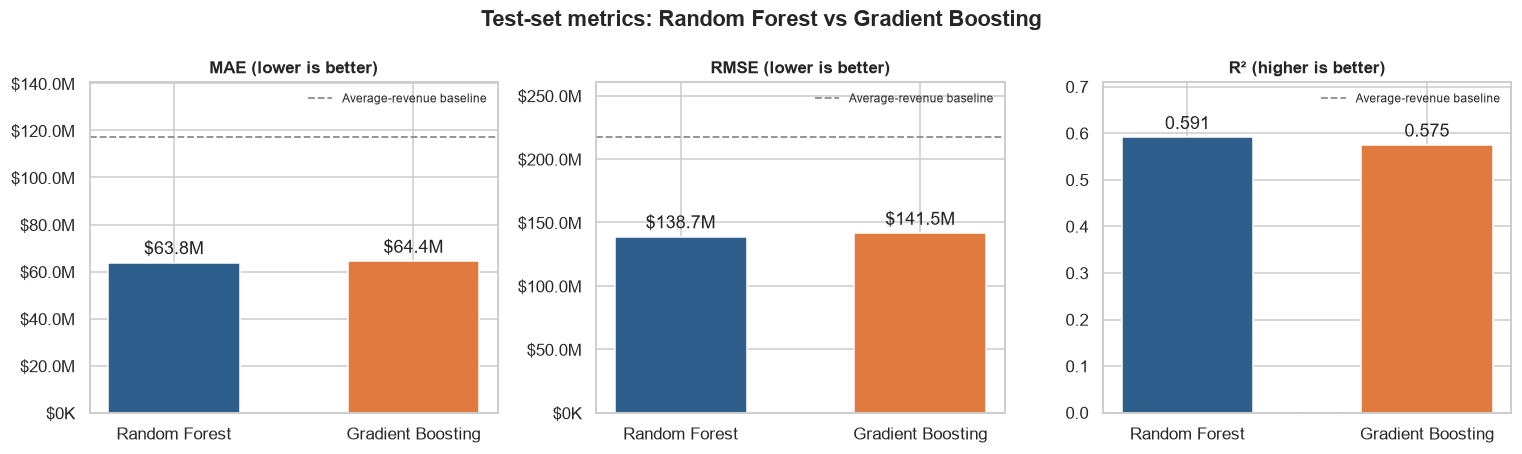

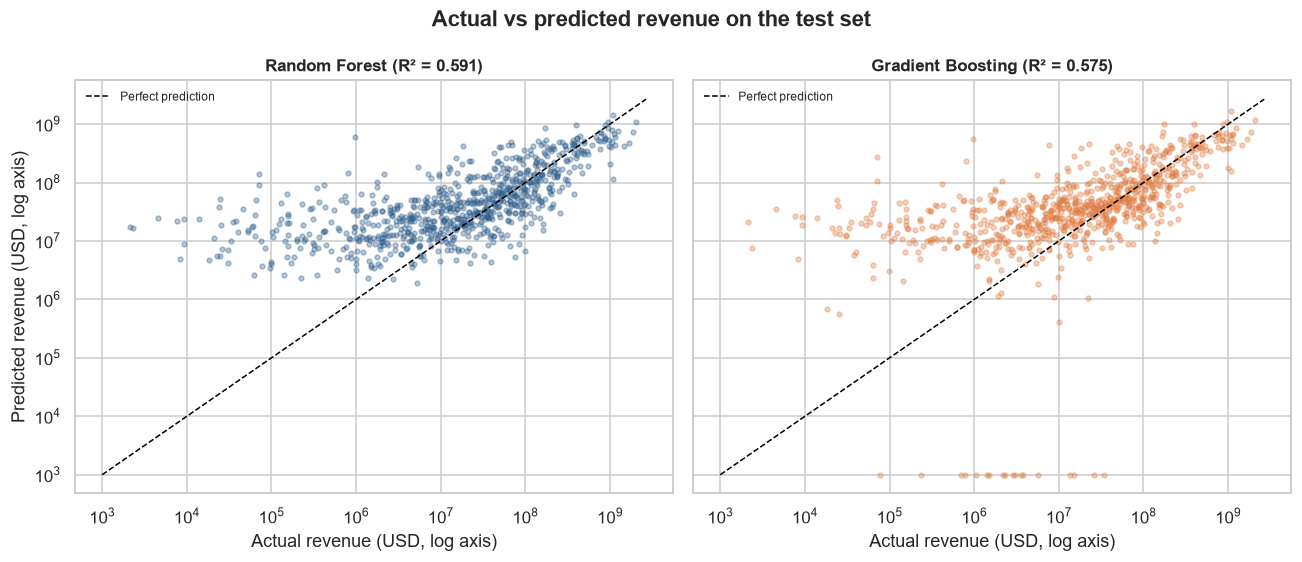

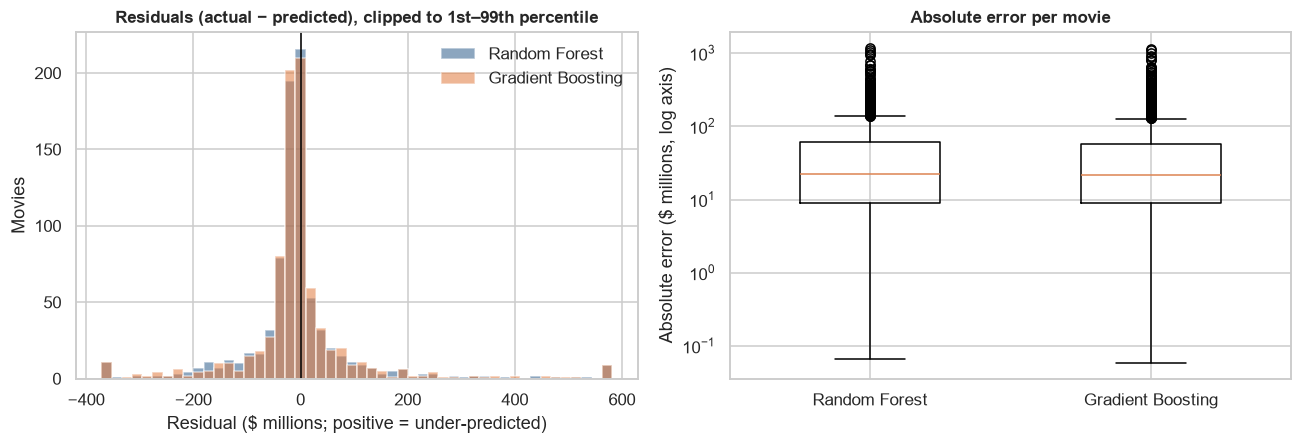

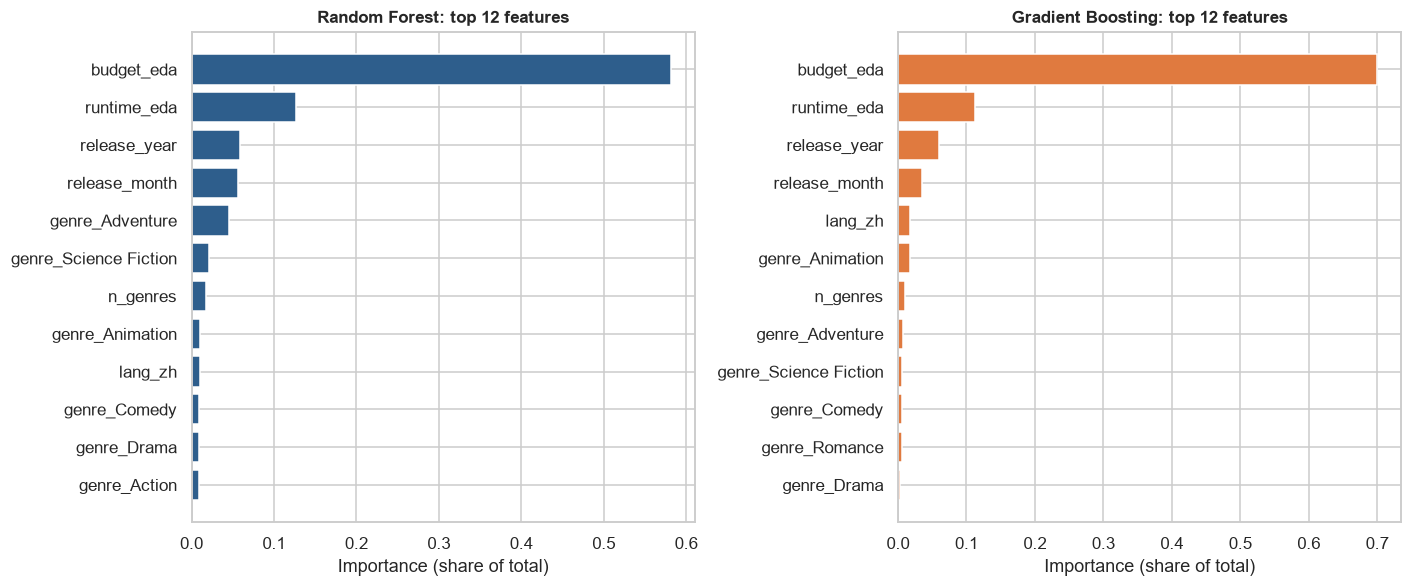

In [95]:
names = list(models)
colors = {"Random Forest": ACCENT, "Gradient Boosting": ACCENT2}

# (a) Metric comparison
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, metric, better in zip(axes, ["MAE", "RMSE", "R²"], ["lower", "lower", "higher"]):
    vals = [metrics.loc[n, metric] for n in names]
    bars = ax.bar(names, vals, color=[colors[n] for n in names], width=0.55)
    ax.bar_label(bars, labels=[f"{v:.3f}" if metric == "R²" else fmt_money(v) for v in vals], padding=3)
    bval = metrics.loc["Average-revenue baseline", metric]
    ax.axhline(bval, color=GREY, ls="--", lw=1.2, label="Average-revenue baseline")
    ax.set_title(f"{metric} ({better} is better)", fontsize=11)
    top = max(vals + [bval, 0.01])
    ax.set_ylim(min(0, min(vals + [bval])) * 1.2, top * 1.2)
    if metric != "R²":
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_money(v)))
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("Test-set metrics: Random Forest vs Gradient Boosting", fontweight="bold")
plt.tight_layout(); plt.show()

# (b) Actual vs predicted (log axes for display only)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True, sharey=True)
lo, hi = 1e3, max(y_test.max(), max(p.max() for n, p in pred_test.items() if n in names)) * 1.3
for ax, n in zip(axes, names):
    ax.scatter(y_test, np.clip(pred_test[n], lo, None), s=10, alpha=0.35, color=colors[n])
    ax.plot([lo, hi], [lo, hi], color="black", lw=1, ls="--", label="Perfect prediction")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(f"{n} (R² = {metrics.loc[n, 'R²']:.3f})", fontsize=11)
    ax.set_xlabel("Actual revenue (USD, log axis)"); ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("Predicted revenue (USD, log axis)")
fig.suptitle("Actual vs predicted revenue on the test set", fontweight="bold")
plt.tight_layout(); plt.show()

# (c) Errors in dollars
resid = {n: y_test.to_numpy() - pred_test[n] for n in names}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
allr = np.concatenate([resid[n] for n in names])
rlo, rhi = np.percentile(allr, [1, 99])
for n in names:
    axes[0].hist(np.clip(resid[n], rlo, rhi) / 1e6, bins=50, alpha=0.55, color=colors[n], label=n)
axes[0].axvline(0, color="black", lw=1)
axes[0].set_title("Residuals (actual − predicted), clipped to 1st–99th percentile", fontsize=11)
axes[0].set_xlabel("Residual ($ millions; positive = under-predicted)"); axes[0].set_ylabel("Movies"); axes[0].legend(frameon=False)
axes[1].boxplot([np.abs(resid[n]) / 1e6 for n in names], tick_labels=names, showfliers=True, widths=0.5)
axes[1].set_yscale("log"); axes[1].set_ylabel("Absolute error ($ millions, log axis)")
axes[1].set_title("Absolute error per movie", fontsize=11)
plt.tight_layout(); plt.show()

# (d) Feature importance (impurity-based; both models expose it)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, n in zip(axes, names):
    imp = pd.Series(models[n].named_steps["model"].feature_importances_, index=X_train.columns).nlargest(12)[::-1]
    ax.barh(imp.index, imp.values, color=colors[n])
    ax.set_title(f"{n}: top 12 features", fontsize=11); ax.set_xlabel("Importance (share of total)")
plt.tight_layout(); plt.show()

### 22.8 Interpretation of the results

The text below is generated from the numbers computed above, so it always matches the actual results.

In [97]:
# --- Decide the winner from the actual results ---
rf, gb = metrics.loc["Random Forest"], metrics.loc["Gradient Boosting"]
base = metrics.loc["Average-revenue baseline"]
wins = {"Random Forest": 0, "Gradient Boosting": 0}
for m in ["MAE", "RMSE"]:
    wins["Random Forest" if rf[m] < gb[m] else "Gradient Boosting"] += 1
wins["Random Forest" if rf["R²"] > gb["R²"] else "Gradient Boosting"] += 1

# Primary criterion (fixed in advance): lowest test RMSE in dollars
winner = "Random Forest" if rf["RMSE"] < gb["RMSE"] else "Gradient Boosting"
loser = "Gradient Boosting" if winner == "Random Forest" else "Random Forest"
w, l = metrics.loc[winner], metrics.loc[loser]
cv_w, cv_l = cv_table.loc[winner], cv_table.loc[loser]
cv_agrees = cv_w["CV RMSE"] < cv_l["CV RMSE"]
ci_excludes_zero = (ci_lo > 0) or (ci_hi < 0)

if ci_excludes_zero:
    strength = f"The paired bootstrap interval for the RMSE difference ([{ci_lo / 1e6:+.2f}M, {ci_hi / 1e6:+.2f}M]) excludes zero, so the advantage is reliable on this test set."
else:
    strength = f"The paired bootstrap interval for the RMSE difference ([{ci_lo / 1e6:+.2f}M, {ci_hi / 1e6:+.2f}M]) includes zero, so the gap is within sampling noise and the two models are statistically hard to separate."

overfit = lambda n: metrics.loc[n, "Train R²"] - metrics.loc[n, "R²"]
beat_base = rf["RMSE"] < base["RMSE"] and gb["RMSE"] < base["RMSE"]

text = f"""
- **{'Both models beat the baseline.' if beat_base else 'At least one model fails to beat the baseline.'}** Always predicting the average training revenue gives test RMSE {fmt_money(base['RMSE'])} and R² {base['R²']:.3f}. Random Forest reaches RMSE {fmt_money(rf['RMSE'])} (R² {rf['R²']:.3f}) and Gradient Boosting RMSE {fmt_money(gb['RMSE'])} (R² {gb['R²']:.3f}).
- **Typical error.** {winner} is off by {fmt_money(w['MAE'])} on average (MAE), {loser} by {fmt_money(l['MAE'])}. For scale, the median test-set revenue is {fmt_money(y_test.median())}, so the average error is {w['MAE'] / y_test.median():.1f}x the median movie's revenue; errors are larger on blockbusters than on small films (see the error plots).
- **RMSE versus MAE.** RMSE ({fmt_money(w['RMSE'])} for {winner}) is much larger than MAE because squaring gives the few very large errors on blockbusters heavy weight. Revenue is strongly skewed (skewness {ml_raw[TARGET].skew():.1f}), so RMSE and R² on dollars depend heavily on a handful of test movies.
- **Metric tally.** Across MAE, RMSE and R², Random Forest wins {wins['Random Forest']} and Gradient Boosting wins {wins['Gradient Boosting']}.
- **Cross-validation {'agrees' if cv_agrees else 'disagrees'}.** On the training folds, {winner}'s mean RMSE is {fmt_money(cv_w['CV RMSE'])} against {fmt_money(cv_l['CV RMSE'])} for {loser}, and mean R² is {cv_w['CV R²']:.3f} against {cv_l['CV R²']:.3f}.
- **Overfitting gap (train R² minus test R²).** Random Forest {overfit('Random Forest'):.3f}, Gradient Boosting {overfit('Gradient Boosting'):.3f}. A larger gap means the model fits the training movies more closely than unseen ones.
- **Reliability of the difference.** The test RMSE gap is {fmt_money(abs(obs_diff))} in favour of {winner} (R² gap {w['R²'] - l['R²']:+.3f}). {strength}
"""
top_feats = {n: pd.Series(models[n].named_steps["model"].feature_importances_, index=X_train.columns).nlargest(3) for n in names}
text += "- **Most important features.** " + "; ".join(
    f"{n}: " + ", ".join(f"`{f}` ({v:.2f})" for f, v in top_feats[n].items()) for n in names) + "."
display(Markdown(text))


- **Both models beat the baseline.** Always predicting the average training revenue gives test RMSE $217.0M and R² -0.000. Random Forest reaches RMSE $138.7M (R² 0.591) and Gradient Boosting RMSE $141.5M (R² 0.575).
- **Typical error.** Random Forest is off by $63.8M on average (MAE), Gradient Boosting by $64.4M. For scale, the median test-set revenue is $19.9M, so the average error is 3.2x the median movie's revenue; errors are larger on blockbusters than on small films (see the error plots).
- **RMSE versus MAE.** RMSE ($138.7M for Random Forest) is much larger than MAE because squaring gives the few very large errors on blockbusters heavy weight. Revenue is strongly skewed (skewness 4.6), so RMSE and R² on dollars depend heavily on a handful of test movies.
- **Metric tally.** Across MAE, RMSE and R², Random Forest wins 3 and Gradient Boosting wins 0.
- **Cross-validation agrees.** On the training folds, Random Forest's mean RMSE is $135.0M against $140.4M for Gradient Boosting, and mean R² is 0.584 against 0.549.
- **Overfitting gap (train R² minus test R²).** Random Forest 0.275, Gradient Boosting 0.231. A larger gap means the model fits the training movies more closely than unseen ones.
- **Reliability of the difference.** The test RMSE gap is $2.7M in favour of Random Forest (R² gap +0.016). The paired bootstrap interval for the RMSE difference ([-10.67M, +3.47M]) includes zero, so the gap is within sampling noise and the two models are statistically hard to separate.
- **Most important features.** Random Forest: `budget_eda` (0.58), `runtime_eda` (0.13), `release_year` (0.06); Gradient Boosting: `budget_eda` (0.70), `runtime_eda` (0.11), `release_year` (0.06).

### 22.9 Final model justification

In [98]:
if ci_excludes_zero and cv_agrees:
    verdict = "performs reliably better on this dataset"
elif ci_excludes_zero:
    verdict = "performs somewhat better on this dataset (cross-validation does not fully agree)"
else:
    verdict = "performs slightly better on this dataset, but the gap is within sampling noise, so the practical difference is small"

justification = f"""
**{winner} {verdict}.**

- It has the lower test RMSE ({fmt_money(w['RMSE'])} vs {fmt_money(l['RMSE'])}), the primary criterion fixed before testing, and it wins {wins[winner]} of the 3 test metrics (MAE, RMSE, R²).
- Its test R² is {w['R²']:.3f} against {l['R²']:.3f} for {loser}: it explains about {max(w['R²'], 0) * 100:.1f}% of the variation in revenue among movies with reported finances.
- Cross-validation on the training data {'points the same way' if cv_agrees else 'points the other way, so the preference is not fully consistent'} (mean RMSE {fmt_money(cv_w['CV RMSE'])} vs {fmt_money(cv_l['CV RMSE'])}).
- {strength}

**Limitations.** (1) The models cover only movies with reported budget and revenue, which may not represent all movies. (2) Revenue is nominal and unaudited, and recent releases (2024–2025) may not have finished their theatrical runs. (3) Only pre-release features were used, so marketing, star power, franchise effects and reviews are not captured. (4) Predicting raw dollars is hard because a few blockbusters dominate the error, which keeps R² and RMSE sensitive to the particular test movies. (5) Hyperparameters were not tuned, and a different split or tuning could change a small gap. (6) Feature importances show what the models used, not what causes revenue.
"""
display(Markdown(justification))


**Random Forest performs slightly better on this dataset, but the gap is within sampling noise, so the practical difference is small.**

- It has the lower test RMSE ($138.7M vs $141.5M), the primary criterion fixed before testing, and it wins 3 of the 3 test metrics (MAE, RMSE, R²).
- Its test R² is 0.591 against 0.575 for Gradient Boosting: it explains about 59.1% of the variation in revenue among movies with reported finances.
- Cross-validation on the training data points the same way (mean RMSE $135.0M vs $140.4M).
- The paired bootstrap interval for the RMSE difference ([-10.67M, +3.47M]) includes zero, so the gap is within sampling noise and the two models are statistically hard to separate.

**Limitations.** (1) The models cover only movies with reported budget and revenue, which may not represent all movies. (2) Revenue is nominal and unaudited, and recent releases (2024–2025) may not have finished their theatrical runs. (3) Only pre-release features were used, so marketing, star power, franchise effects and reviews are not captured. (4) Predicting raw dollars is hard because a few blockbusters dominate the error, which keeps R² and RMSE sensitive to the particular test movies. (5) Hyperparameters were not tuned, and a different split or tuning could change a small gap. (6) Feature importances show what the models used, not what causes revenue.


### 22.10 Takeaway for the overall project

The model comparison result is carried into the final conclusion in section 23.

## 23. Final Conclusion

Use the computed EDA outputs and all seven hypothesis tests to write the final conclusion. Separate descriptive patterns from statistically supported results. State the size and direction of differences, not only whether a p-value is significant. Mention the dataset's historical scope, missing/zero financial reporting, imputation handling, overlapping multi-genre/country groups and the fact that gross revenue is not audited profit.

**Important:** These are exploratory tests selected after inspecting the same dataset, so p-values are not independent confirmation on a separate sample. None of the tests establishes causation. The other EDA questions remain useful descriptive analyses and do not each require a hypothesis test.


In [99]:
rejected_count = int((test_summary["Decision at alpha=0.05"] == "Reject H0").sum())
not_rejected_count = int((test_summary["Decision at alpha=0.05"] == "Fail to reject H0").sum())
decision_lines = []
for _, row in test_summary.iterrows():
    decision_lines.append(
        f"- **{row['Test']}: {row['EDA-derived claim']}** {row['Decision at alpha=0.05']} "
        f"(p-value {row['p-value']})."
    )
conclusion_text = (
    f"At α = {ALPHA:.2f}, the computed results reject the null hypothesis in **{rejected_count} of 7 tests** "
    f"and fail to reject it in **{not_rejected_count} of 7 tests**.\n\n"
    + "\n".join(decision_lines)
    + "\n\nInterpret each result alongside the observed effect and group sizes. Statistical significance does not imply practical importance or causation. "
      "Financial comparisons apply only to movies with observed budget and revenue values; results describe this dataset, not all films."
)
display(Markdown(conclusion_text))


At α = 0.05, the computed results reject the null hypothesis in **7 of 7 tests** and fail to reject it in **0 of 7 tests**.

- **HT1: Budget range × earning back reported budget** Reject H0 (p-value 4.185e-39).
- **HT2: Multi-genre vs single-genre mean rating** Reject H0 (p-value < 0.0001 (no equally/extremely large result in 10,000 permutations)).
- **HT3: Highest vs lowest popularity-decile median rating** Reject H0 (p-value < 0.0001 (no equally/extremely large result in 10,000 permutations)).
- **HT4: Release period × Thriller tag** Reject H0 (p-value 1.417e-12).
- **HT5: Mean log revenue-to-budget ratio vs break-even** Reject H0 (p-value 0.002592).
- **HT6: Short vs long movie mean rating** Reject H0 (p-value 4.903e-185).
- **HT7: High-vote vs low-vote share rated >=7** Reject H0 (p-value 9.999e-05).

Interpret each result alongside the observed effect and group sizes. Statistical significance does not imply practical importance or causation. Financial comparisons apply only to movies with observed budget and revenue values; results describe this dataset, not all films.

In [100]:
ml_conclusion = (
    f"**Machine learning (section 22).** Random Forest and Gradient Boosting regressors were trained on the same "
    f"{len(X_train):,} movies and tested on the same {len(X_test):,} movies with reported budget and revenue, predicting revenue in dollars "
    f"from pre-release features only (budget, runtime, release year and month, genre count, genre and language indicators). "
    f"On the test set, Random Forest scored MAE {fmt_money(rf['MAE'])}, RMSE {fmt_money(rf['RMSE'])} and R² {rf['R²']:.3f}, "
    f"while Gradient Boosting scored MAE {fmt_money(gb['MAE'])}, RMSE {fmt_money(gb['RMSE'])} and R² {gb['R²']:.3f}. "
    f"**{winner}** {verdict}. "
    f"It explains about {max(w['R²'], 0):.0%} of the variation in revenue, so roughly {max(0, 1 - w['R²']):.0%} remains unexplained by these pre-release features, "
    f"and errors are driven by a small number of blockbusters. {strength} "
    f"The most important feature for {winner} is `{top_feats[winner].index[0]}`. "
    f"Predictive accuracy does not imply causation and applies only to movies with reported finances."
)
display(Markdown(ml_conclusion))


**Machine learning (section 22).** Random Forest and Gradient Boosting regressors were trained on the same 3,272 movies and tested on the same 818 movies with reported budget and revenue, predicting revenue in dollars from pre-release features only (budget, runtime, release year and month, genre count, genre and language indicators). On the test set, Random Forest scored MAE $63.8M, RMSE $138.7M and R² 0.591, while Gradient Boosting scored MAE $64.4M, RMSE $141.5M and R² 0.575. **Random Forest** performs slightly better on this dataset, but the gap is within sampling noise, so the practical difference is small. It explains about 59% of the variation in revenue, so roughly 41% remains unexplained by these pre-release features, and errors are driven by a small number of blockbusters. The paired bootstrap interval for the RMSE difference ([-10.67M, +3.47M]) includes zero, so the gap is within sampling noise and the two models are statistically hard to separate. The most important feature for Random Forest is `budget_eda`. Predictive accuracy does not imply causation and applies only to movies with reported finances.